# Canal endémico y modelos ARIMA, SARIMA y SARIMAX para el dengue en Colombia: vigilancia y pronóstico como herramientas complementarias
- **Proyecto final – Series de Tiempo** · Semillero de Machine Learning (feria científica)
- **Basado en:** Taller de series de tiempo SARIMAX (Modelos de Regresión y Series de Tiempo)

## 1. Introducción y pregunta de pronóstico

### 1.1 Contexto

El dengue es una de las enfermedades transmitidas por vectores de mayor impacto en Colombia. El Instituto Nacional de Salud (INS) lo vigila con el **canal endémico**, que publica cada semana en el Boletín Epidemiológico Semanal (BES): una banda construida con los casos de años anteriores que indica, semana a semana, si los casos notificados están dentro de lo esperado, en alerta o en brote.

El canal dice **cómo estamos** frente a la historia, pero no fue diseñado para decir **cuántos casos vienen**. Este cuaderno estudia si un modelo de la familia ARIMA (ARIMA, SARIMA o SARIMAX) puede aportar esa parte que falta, y cómo se usarían las dos herramientas juntas.

### 1.2 Dos herramientas que miden cosas distintas

| | Canal endémico | Modelo de la familia ARIMA |
| :--- | :--- | :--- |
| Tipo de herramienta | **Vigilancia** | **Pronóstico** |
| Pregunta que responde | ¿Los casos que **ya ocurrieron** son normales para esta semana del año? | ¿Cuántos casos habrá en las **próximas semanas**? |
| Información que usa | Los casos de años anteriores. Se calcula una sola vez y no cambia durante el año | Los casos más recientes. Se actualiza cada semana con el dato nuevo |
| Resultado | Una zona: éxito, seguridad, alerta o brote | Un número de casos con su intervalo de pronóstico |
| Lo que **no** hace | No anticipa los casos futuros | No dice si esa cantidad de casos es normal o preocupante |

Tres aclaraciones que se mantienen en todo el cuaderno:

1. **El canal endémico no es un pronóstico, y el INS no lo presenta como tal.** Es una referencia histórica de lo "normal" para cada semana, parecida a las curvas de crecimiento que usa un pediatra: no intenta adivinar el peso de un niño, dice cuál es el peso normal para poder detectar lo anormal.
2. **Usar el valor esperado del canal como "pronóstico" es una decisión metodológica de este proyecto, no del INS.** Se usa como línea base institucional: *¿qué pasa si suponemos que ocurrirá lo normal?* Por eso, que el valor esperado quede lejos de lo observado **no es una falla del canal como herramienta de vigilancia: es su señal de alarma**. Lo que muestra es que "lo normal" no sirve como pronóstico cuando el año no es normal.
3. **El error del canal es el mismo en todos los horizontes**, porque su valor para cada semana queda fijo desde el inicio del año y no usa los casos que van llegando.

Por estas razones el cuaderno **no pone a competir al ARIMA con el canal endémico**. Compara sus errores para mostrar **en qué falla cada herramienta y cómo la cubre la otra**.

### 1.3 Pregunta de pronóstico y horizonte

> **¿Cuántos casos de dengue se notificarán en Colombia en cada una de las próximas 4 semanas epidemiológicas, y en qué zona del canal endémico caerían esos casos?**

- **Horizonte principal: h = 4 semanas.** El INS analiza la vigilancia del dengue en **periodos epidemiológicos de 4 semanas** (52 semanas equivalen a 13 periodos al año). En el BES de la semana 38 de 2026 (páginas 29 a 31) el comportamiento del evento se describe comparando el último periodo analizado (semanas 34 a 37) con el periodo anterior (semanas 30 a 33), y la tabla 19 (página 30) presenta los casos de cada entidad territorial en esos dos bloques de 4 semanas. Un pronóstico a 4 semanas responde la pregunta que el sistema se hace en cada periodo: *¿qué va a pasar en el próximo?*
- **Horizontes complementarios:** 1 semana (el pronóstico más corto posible) y el año completo (el horizonte en el que el canal queda fijo).

### 1.4 Diseño del experimento

| | Detalle |
| :--- | :--- |
| Serie | Casos semanales de dengue en Colombia (nivel nacional), semana epidemiológica de notificación |
| Fuente | Microdatos del Sivigila (INS): eventos **210** (dengue), **220** (dengue grave) y **580** (mortalidad por dengue), igual que el BES |
| Periodo | 2019 – 2025 (366 semanas) |
| Entrenamiento | Semana 1 de 2019 a semana 52 de 2024 (313 semanas) |
| Prueba | Semanas 1 a 53 de 2025 (53 semanas) |
| Referencia institucional | Canal endémico (método de Bortman), replicado y validado contra la Figura 16 del BES de la semana 38 de 2026 |
| Modelos de referencia estadísticos | Ingenuo, ingenuo estacional (m = 52) e ingenuo con deriva |
| Modelos candidatos | ARIMA, SARIMA (s = 52) y SARIMAX con términos de Fourier |
| Comparación | Métricas de error en la ventana de prueba: **RMSE, MAE, MAPE y MASE** |
| Horizonte principal | **4 semanas** |
| Horizontes complementarios | 1 semana y año completo |
| Evaluación ampliada | Se repite el experimento con los años de prueba 2022, 2023, 2024 y 2025 |
| Producto final | Pronóstico de 2026-SE01 a 2026-SE04, con intervalos del 80 % y del 95 %, ubicado sobre el canal endémico de 2026 |

> **Importante:** los criterios de información (AIC, AICc, BIC) solo sirven para escoger el mejor modelo **dentro** de la familia ARIMA. El canal endémico y los modelos ingenuos no tienen verosimilitud ni AIC, así que la comparación entre herramientas se hace **únicamente con las métricas de error** sobre el periodo de prueba.

**Contenido**
1. Introducción y pregunta de pronóstico
2. Datos: ficha de la serie, construcción, ventanas, faltantes y atípicos
3. Análisis exploratorio (EDA): estadísticas descriptivas, cambios de comportamiento, STL, quiebres estructurales, términos de Fourier y estacionariedad
4. Método empírico: canal endémico, modelos de referencia, familia ARIMA y diseño de la evaluación
5. Resultados: diagnóstico de residuos, ARIMA-GARCH, pronósticos en la prueba, evaluación 2022–2025, selección del modelo final y pronóstico de 2026 sobre el canal
6. Conclusiones
7. Reproducibilidad

In [ ]:
!pip install pmdarima arch

In [2]:
# Librerias necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime as dt
from scipy import stats
from scipy.stats import pearsonr
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss, zivot_andrews, acf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.arima.model import ARIMA
from pmdarima import auto_arima
from statsmodels.tsa.seasonal import STL
from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_absolute_percentage_error
from arch import arch_model
import warnings
warnings.filterwarnings('ignore')

# Reproducibilidad: se fija una semilla. Los procesos de este cuaderno son deterministas
# (no hay simulaciones ni particiones aleatorias), asi que la semilla solo es una precaucion.
np.random.seed(123)

## 2. Datos

### 2.1 Ficha de la serie

| Campo | Detalle |
| :--- | :--- |
| Nombre | Casos semanales notificados de dengue en Colombia (nivel nacional) |
| Códigos de evento | **210** (dengue, sin y con signos de alarma), **220** (dengue grave) y **580** (mortalidad por dengue) |
| Fuente | Portal Sivigila, Instituto Nacional de Salud (INS) – microdatos por evento y año |
| Enlace | https://portalsivigila.ins.gov.co/ (sección de microdatos) |
| Fecha de descarga | **[COMPLETAR: fecha en que se descargaron los archivos del portal]** |
| Unidades | Casos notificados por semana epidemiológica |
| Frecuencia | Semanal (semana epidemiológica, de domingo a sábado) |
| Periodo | 2019-SE01 a 2025-SE53 (366 semanas) |
| Variable de tiempo | Semana epidemiológica de notificación (`ANO`, `SEMANA`) |
| Ajuste estacional | Ninguno (serie sin desestacionalizar) |
| Año base | No aplica (son conteos de casos, no un índice) |
| Transformaciones | Ninguna. Los modelos se estiman sobre los casos en niveles |

### 2.2 Construcción de la serie

Los microdatos del Sivigila traen **un registro por paciente**. Para tener una serie de tiempo se cuentan los casos por **año (`ANO`) y semana epidemiológica (`SEMANA`)** sumando los tres eventos que usa el INS en el boletín:

- **210** – dengue (sin y con signos de alarma)
- **220** – dengue grave
- **580** – mortalidad por dengue

Se incluyen todos los casos notificados en el país (también los procedentes del exterior, que el boletín muestra en la fila "Exterior" de su tabla 19).

**Fecha de cada semana:** en Colombia la semana epidemiológica va de domingo a sábado y la semana 1 es la que contiene el 4 de enero. 2020 y 2025 tienen **53 semanas**; los demás años tienen 52.

**Dos formas de cargar los datos:**
- **Opción A (por defecto):** subir a Colab el archivo `dengue_semanal_2019_2025.csv`, que ya tiene los conteos semanales.
- **Opción B:** reconstruir los conteos desde los archivos originales del Sivigila (`Datos_2019_210.xlsx`, …, `Datos_2025_580.xlsx`). Se suben a la carpeta `/content/datos` y se cambia `RECONSTRUIR_DESDE_SIVIGILA = True`. Es más lento porque son archivos grandes (el de 2024 pesa unos 200 MB).

In [3]:
# Opcion A (por defecto): leer la serie semanal ya construida
# Opcion B: reconstruirla desde los microdatos del Sivigila (archivos Datos_AAAA_EEE.xlsx en /content/datos)
RECONSTRUIR_DESDE_SIVIGILA = False

def inicio_anio_epidemiologico(anio):
    # La semana epidemiologica 1 es la semana (domingo a sabado) que contiene el 4 de enero
    d = dt.date(anio, 1, 4)
    return pd.Timestamp(d - dt.timedelta(days=(d.weekday() + 1) % 7))

if RECONSTRUIR_DESDE_SIVIGILA:
    import glob
    conteos = []
    for archivo in sorted(glob.glob("/content/datos/Datos_*_*.xlsx")):
        df = pd.read_excel(archivo, usecols=["ANO", "SEMANA", "COD_EVE"], dtype=str)
        conteos.append(df.groupby(["ANO", "SEMANA", "COD_EVE"]).size().rename("casos").reset_index())
        print(f"{archivo}: {len(df)} registros")
    conteos = pd.concat(conteos)
    conteos[["ANO", "SEMANA"]] = conteos[["ANO", "SEMANA"]].astype(int)
    datos = conteos.pivot_table(index=["ANO", "SEMANA"], columns="COD_EVE", values="casos", aggfunc="sum", fill_value=0)
    datos.columns = [f"casos_{c}" for c in datos.columns]
    datos["casos"] = datos.sum(axis=1)
    datos = datos.reset_index()
    datos["fecha_inicio_semana"] = [inicio_anio_epidemiologico(a) + pd.Timedelta(weeks=s - 1) for a, s in zip(datos["ANO"], datos["SEMANA"])]
    datos = datos.sort_values("fecha_inicio_semana")
    datos.to_csv("dengue_semanal_2019_2025.csv", index=False)
else:
    datos = pd.read_csv("dengue_semanal_2019_2025.csv", parse_dates=["fecha_inicio_semana"])

datos = datos.set_index("fecha_inicio_semana")
datos.index = pd.DatetimeIndex(datos.index, freq="W-SUN")
datos.head()

,ANO,SEMANA,casos_210,casos_220,casos_580,casos
fecha_inicio_semana,,,,,,
2018-12-30,2019,1,1653,19,5,1677
2019-01-06,2019,2,1656,24,1,1681
2019-01-13,2019,3,1628,25,2,1655
2019-01-20,2019,4,1679,12,3,1694
2019-01-27,2019,5,1753,13,0,1766


In [4]:
# Casos por año y por evento
tab_anual = datos.groupby("ANO")[["casos_210", "casos_220", "casos_580", "casos"]].sum()
tab_anual["semanas"] = datos.groupby("ANO")["SEMANA"].max()
casos_2025_s38 = datos[(datos["ANO"] == 2025) & (datos["SEMANA"] <= 38)]["casos"].sum()
print(f"Casos 2025, semanas 1 a 38: {casos_2025_s38:,} (el BES de la semana 38 de 2026 reporta 104 188 para el mismo periodo)")
tab_anual

Casos 2025, semanas 1 a 38: 98,121 (el BES de la semana 38 de 2026 reporta 104 188 para el mismo periodo)


,casos_210,casos_220,casos_580,casos,semanas
ANO,,,,,
2019,123641,1348,122,125111,52
2020,76419,862,70,77351,53
2021,49325,940,74,50339,52
2022,65691,1340,85,67116,52
2023,126411,1721,118,128250,52
2024,309627,3016,284,312927,52
2025,120564,1278,139,121981,53


**Interpretación**

- **Cada año tiene todas sus semanas:** 52 semanas, y 53 en 2020 y 2025, para un total de 366 semanas.
- **Peso de cada evento:** el evento 210 (dengue sin y con signos de alarma) es casi todo el total: en 2025 son 120 564 de los 121 981 casos. El dengue grave (220) y la mortalidad (580) suman poco, pero se incluyen para seguir la misma definición del boletín.
- **2024 fue un año epidémico:** tuvo 312 927 casos, más del doble que cualquier otro año del periodo.
- **Comparación con el boletín:** entre las semanas 1 y 38 de 2025 estos datos suman 98 121 casos, mientras que el BES reporta 104 188 para el mismo periodo, unos 6 000 más. La diferencia es esperable, porque la base del portal del Sivigila es la **versión depurada**: ya no incluye los casos que después se descartaron por laboratorio o por error de digitación. El boletín, en cambio, cuenta los casos notificados en ese momento. Por eso los conteos no son idénticos, aunque la fuente es la misma.

### 2.3 Longitud de la serie y ventanas de entrenamiento y prueba

**Nota sobre la longitud de la serie.** El enunciado del proyecto pide un mínimo de 520 observaciones. Esta serie tiene **366 semanas** (2019-SE01 a 2025-SE53) y **el docente autorizó trabajar con este periodo**, que es el que cubren los microdatos usados y el que permite replicar el canal endémico del boletín.

**Ventanas.** Los modelos se estiman con el **entrenamiento (2019-SE01 a 2024-SE52)** y se evalúan en la **prueba (2025-SE01 a 2025-SE53)**. Ningún modelo usa datos de 2025 para estimarse ni para escoger sus órdenes. Lo mismo vale para el análisis que orienta el modelado (atípicos, STL, quiebres, estacionariedad, ACF y PACF), que se hace solo con el entrenamiento. Las tablas y gráficas que solo describen los datos (ficha, faltantes, estadísticas por año y gráfica de la serie) sí muestran los siete años.

In [5]:
# Ventana de entrenamiento y de prueba
train = datos[datos["ANO"] <= 2024].copy()
test  = datos[datos["ANO"] == 2025].copy()
serie_train = train["casos"].astype(float)
serie_completa = datos["casos"].astype(float)

print(f"Serie completa: {len(datos)} semanas")
print(f"Entrenamiento: {train.index[0].date()} a {train.index[-1].date()} -> {len(train)} semanas (2019-SE01 a 2024-SE52)")
print(f"Prueba       : {test.index[0].date()} a {test.index[-1].date()} -> {len(test)} semanas (2025-SE01 a 2025-SE53)")
print(f"Prueba como porcentaje de la serie: {len(test) / len(datos) * 100:.1f} %")

Serie completa: 366 semanas
Entrenamiento: 2018-12-30 a 2024-12-22 -> 313 semanas (2019-SE01 a 2024-SE52)
Prueba       : 2024-12-29 a 2025-12-28 -> 53 semanas (2025-SE01 a 2025-SE53)
Prueba como porcentaje de la serie: 14.5 %


**Interpretación**

- **Tamaño de las ventanas:** 313 semanas de entrenamiento y 53 de prueba, que son el 14.5 % de la serie.
- **El periodo de prueba es suficiente** para evaluar los modelos, por dos razones:
  - Tiene 53 semanas, muchas más que el horizonte principal (h = 4), así que hay 53 pronósticos a 4 semanas para calcular las métricas.
  - Cubre un ciclo estacional completo (52 semanas), de modo que los modelos se evalúan en todas las épocas del año y no solo en una temporada.
- Además, en la sección 5.6 la evaluación se repite con cuatro años de prueba (2022 a 2025), para que las conclusiones no dependan de un solo año.

### 2.4 Tratamiento de datos faltantes

Una serie semanal tiene un dato faltante cuando falta una semana en el índice o cuando una semana no tiene valor. Se verifica con código que: (1) no hay valores vacíos, (2) no hay fechas repetidas, (3) entre dos semanas consecutivas siempre hay 7 días y (4) cada año tiene todas sus semanas epidemiológicas.

In [6]:
# Verificacion de datos faltantes y de la continuidad del indice semanal
dias_entre_semanas = datos.index.to_series().diff().dropna().dt.days
semanas_esperadas = int((datos.index[-1] - datos.index[0]).days / 7) + 1

verificacion = pd.DataFrame({
    "Verificación": ["Semanas en la serie",
                     "Semanas esperadas entre la primera y la última fecha",
                     "Valores faltantes (NaN) en la columna de casos",
                     "Semanas con cero casos",
                     "Fechas duplicadas",
                     "Días entre semanas consecutivas (mínimo)",
                     "Días entre semanas consecutivas (máximo)"],
    "Resultado": [len(datos), semanas_esperadas, int(datos["casos"].isna().sum()), int((datos["casos"] == 0).sum()),
                  int(datos.index.duplicated().sum()), int(dias_entre_semanas.min()), int(dias_entre_semanas.max())]
})
print(verificacion.to_string(index=False))

indice_continuo = (len(datos) == semanas_esperadas) and (dias_entre_semanas.min() == 7) and (dias_entre_semanas.max() == 7)
print(f"\n¿El índice semanal es continuo (sin semanas faltantes)? {'Sí' if indice_continuo else 'No'}")

# Semanas epidemiologicas por año: deben ir de 1 a 52 (o 53) sin saltos
semanas_anio = datos.groupby("ANO")["SEMANA"].agg(Primera="min", Ultima="max", Semanas="count")
semanas_anio["Completo"] = np.where(semanas_anio["Semanas"] == semanas_anio["Ultima"] - semanas_anio["Primera"] + 1, "Sí", "No")
semanas_anio

                                        Verificación  Resultado
                                 Semanas en la serie        366
Semanas esperadas entre la primera y la última fecha        366
      Valores faltantes (NaN) en la columna de casos          0
                              Semanas con cero casos          0
                                   Fechas duplicadas          0
            Días entre semanas consecutivas (mínimo)          7
            Días entre semanas consecutivas (máximo)          7

¿El índice semanal es continuo (sin semanas faltantes)? Sí


,Primera,Ultima,Semanas,Completo
ANO,,,,
2019,1,52,52,Sí
2020,1,53,53,Sí
2021,1,52,52,Sí
2022,1,52,52,Sí
2023,1,52,52,Sí
2024,1,52,52,Sí
2025,1,53,53,Sí


**Interpretación**

- **No hay datos faltantes:** la serie tiene 366 semanas y son exactamente las 366 que debe haber entre la primera y la última fecha. No hay valores vacíos (0), fechas duplicadas (0) ni semanas con cero casos (0).
- **El índice es continuo:** entre dos semanas consecutivas siempre hay 7 días (mínimo 7, máximo 7), y cada año va de la semana 1 a la 52 o 53 sin saltos.
- **Tratamiento:** como no falta ninguna semana, **no se imputa ni se interpola ningún valor**. La serie se usa tal como sale del conteo de los microdatos.

### 2.5 Tratamiento de datos atípicos

Los atípicos se identifican con el criterio del **rango intercuartílico (IQR)**: un valor es atípico si queda por debajo de $Q_1 - k \cdot IQR$ o por encima de $Q_3 + k \cdot IQR$, donde $IQR = Q_3 - Q_1$. Se aplica de dos formas, las dos solo con el entrenamiento:

- **Sobre el nivel de casos** ($k = 1.5$, el criterio habitual): detecta las semanas con un número de casos muy alto o muy bajo frente al resto de la serie.
- **Sobre el cambio semanal de casos** ($k = 3$, atípicos extremos): detecta los saltos bruscos de una semana a la siguiente.

ATÍPICOS POR EL CRITERIO IQR (entrenamiento 2019–2024)
Nivel de casos   : límites [-1790.5, 5821.5] -> 26 semanas atípicas
                   por año: {2024: 26}
Cambio semanal   : límites [-646.8, 660.5] -> 8 semanas atípicas
                   por año: {2019: 1, 2020: 1, 2024: 6}


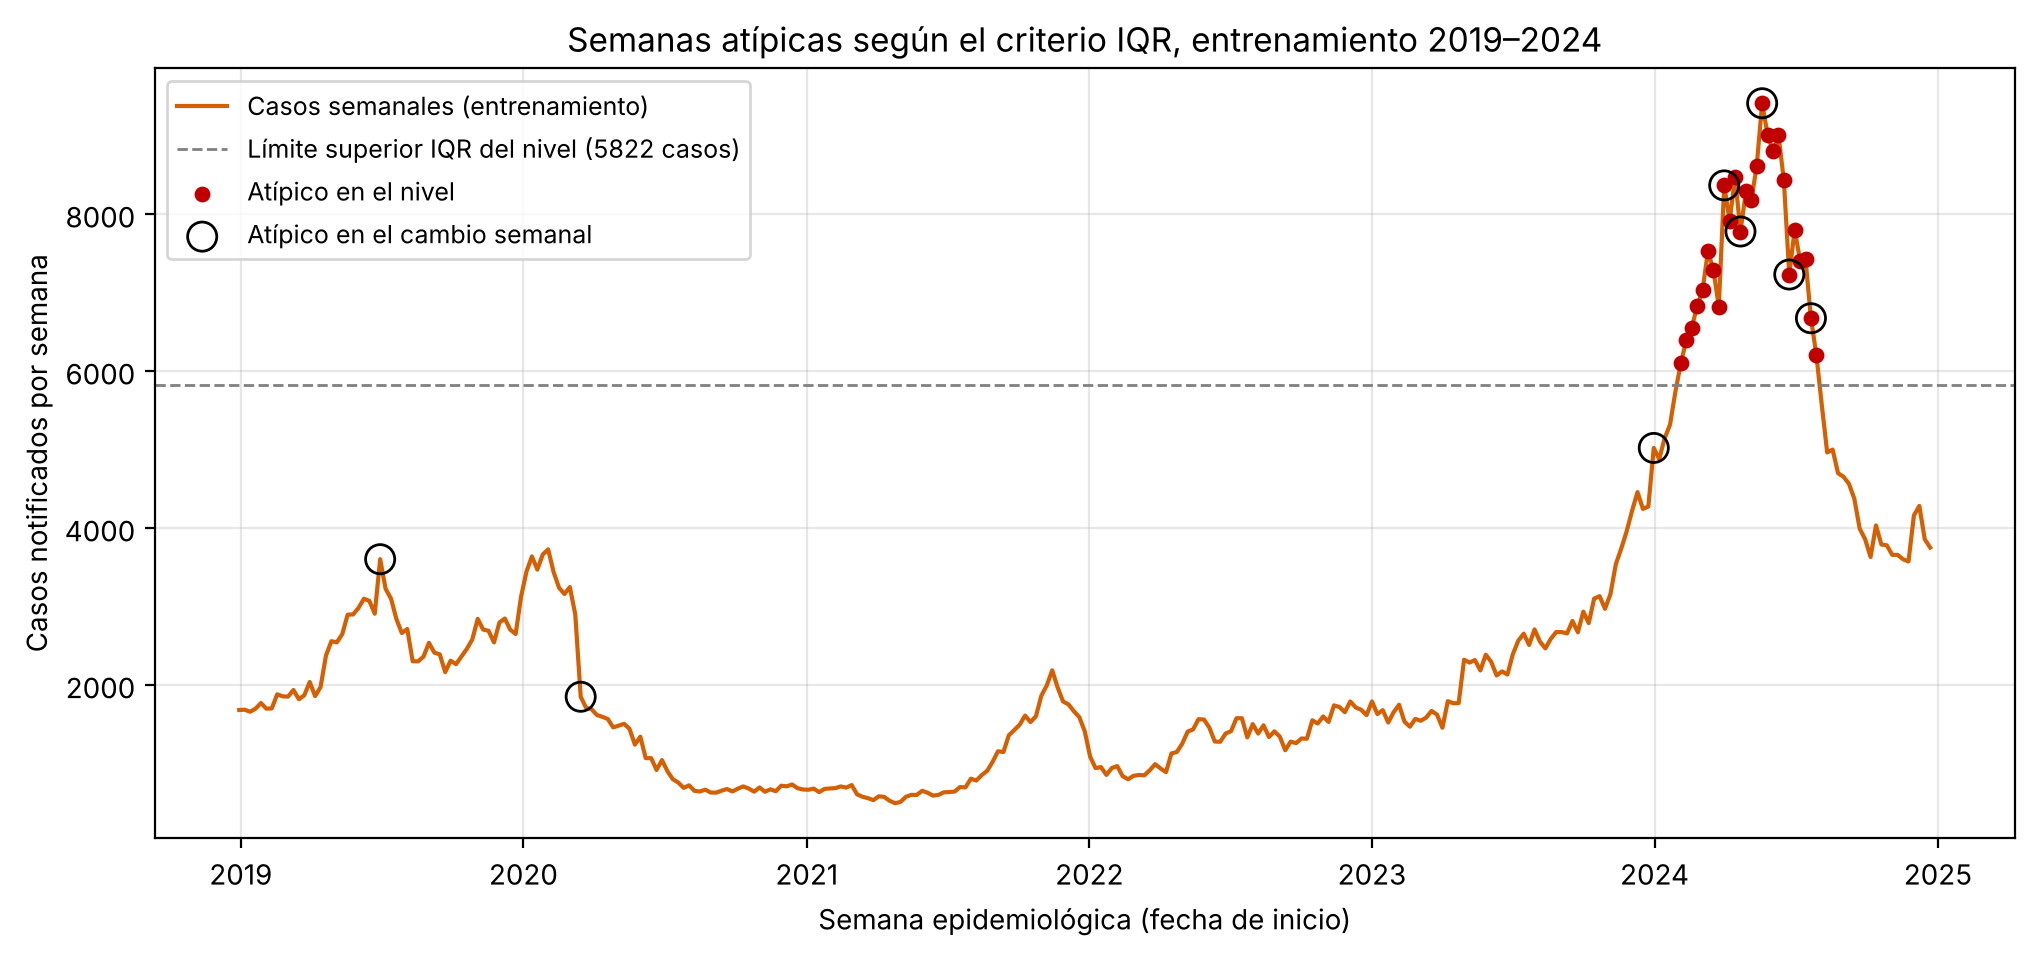

,ANO,SEMANA,casos,Cambio frente a la semana anterior
fecha_inicio_semana,,,,
2019-06-30,2019,27,3599,695.0
2020-03-15,2020,12,1846,-1049.0
2023-12-31,2024,1,5017,747.0
2024-03-31,2024,14,8363,1544.0
2024-04-21,2024,17,7775,-696.0
2024-05-19,2024,21,9410,796.0
2024-06-23,2024,26,7227,-1204.0
2024-07-21,2024,30,6670,-750.0


In [7]:
# Identificacion de atipicos con el criterio del rango intercuartilico (IQR), solo con el entrenamiento
def limites_iqr(serie, k):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    return q1 - k * (q3 - q1), q3 + k * (q3 - q1)

# 1. Atipicos en el NIVEL de casos (k = 1.5)
li_nivel, ls_nivel = limites_iqr(serie_train, 1.5)
atipicos_nivel = serie_train[(serie_train < li_nivel) | (serie_train > ls_nivel)]

# 2. Atipicos en el CAMBIO semanal de casos (k = 3, atipicos extremos)
cambio_semanal = serie_train.diff().dropna()
li_cambio, ls_cambio = limites_iqr(cambio_semanal, 3)
atipicos_cambio = cambio_semanal[(cambio_semanal < li_cambio) | (cambio_semanal > ls_cambio)]

print("=" * 80)
print("ATÍPICOS POR EL CRITERIO IQR (entrenamiento 2019–2024)")
print("=" * 80)
print(f"Nivel de casos   : límites [{li_nivel:.1f}, {ls_nivel:.1f}] -> {len(atipicos_nivel)} semanas atípicas")
print(f"                   por año: {train.loc[atipicos_nivel.index, 'ANO'].value_counts().sort_index().to_dict()}")
print(f"Cambio semanal   : límites [{li_cambio:.1f}, {ls_cambio:.1f}] -> {len(atipicos_cambio)} semanas atípicas")
print(f"                   por año: {train.loc[atipicos_cambio.index, 'ANO'].value_counts().sort_index().to_dict()}")
print("=" * 80)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(serie_train.index, serie_train, color="#D55F03", linewidth=1.5, label="Casos semanales (entrenamiento)")
ax.axhline(ls_nivel, color="grey", linestyle="--", linewidth=1, label=f"Límite superior IQR del nivel ({ls_nivel:.0f} casos)")
ax.scatter(atipicos_nivel.index, atipicos_nivel, color="#C00000", s=22, zorder=3, label="Atípico en el nivel")
ax.scatter(atipicos_cambio.index, serie_train[atipicos_cambio.index], facecolors="none", edgecolors="black", s=110, zorder=4, label="Atípico en el cambio semanal")
ax.set_xlabel("Semana epidemiológica (fecha de inicio)")
ax.set_ylabel("Casos notificados por semana")
ax.set_title("Semanas atípicas según el criterio IQR, entrenamiento 2019–2024")
ax.legend(loc="upper left", fontsize=9)
ax.grid(True, alpha=0.3)
plt.show()

# Detalle de los cambios semanales atipicos
tab_atipicos_cambio = train.loc[atipicos_cambio.index, ["ANO", "SEMANA", "casos"]].copy()
tab_atipicos_cambio["Cambio frente a la semana anterior"] = atipicos_cambio
tab_atipicos_cambio

**Interpretación**

- **Atípicos en el nivel:** los límites son −1 790.5 y 5 821.5 casos. Hay **26 semanas atípicas y todas son de 2024**: la mitad del año epidémico supera el límite superior. No hay atípicos hacia abajo, porque el límite inferior es negativo. Es decir, la caída de 2020–2021 no aparece como atípica por su nivel: esos valores bajos están dentro del rango habitual de la serie.
- **Atípicos en el cambio semanal:** los límites son −646.8 y 660.5 casos de una semana a otra. Hay **8 saltos atípicos**:
  - **2020-SE12:** una caída de 1 049 casos en una sola semana. Es la semana anterior al inicio del aislamiento por COVID-19 (2020-SE13) y marca el final de la epidemia de 2019–2020.
  - **Seis semanas de 2024** (SE01, SE14, SE17, SE21, SE26 y SE30), con saltos de entre −1 204 y +1 544 casos: son las subidas y bajadas bruscas de la epidemia.
  - **2019-SE27:** una subida de 695 casos, en el pico de 2019.
- **¿Por qué no se eliminan ni se corrigen?**
  - **No son errores, son el fenómeno.** Los valores de 2024 y la caída de 2020 son casos reales notificados al Sivigila. Una epidemia es justo lo que la vigilancia quiere detectar y lo que un pronóstico quiere anticipar.
  - **Sin ellos las herramientas no se podrían evaluar.** Si se quitara 2024, no se podría comprobar que el canal marca la epidemia como brote ni que el ARIMA sigue el nivel epidémico.
  - **El canal ya tiene su propio tratamiento:** el INS excluye el año epidémico 2024 de los años históricos del canal, y eso se replica en la sección 4.1. Para los modelos de pronóstico, en cambio, 2024 se deja en el entrenamiento, porque el modelo debe aprender cómo se comporta la serie en una epidemia.
- **Consecuencia para los modelos:** estos saltos hacen que los errores sean más grandes en las epidemias que en los periodos tranquilos. Eso se revisa en el diagnóstico de residuos (sección 5.1) y se modela con un GARCH (sección 5.2).

## 3. Análisis exploratorio de datos (EDA)

### 3.1 Estadísticas descriptivas

Para cada año y para toda la serie se calculan el número de semanas, el total de casos, la media, la mediana, la desviación estándar, el mínimo, el máximo y el coeficiente de variación (CV = desviación estándar / media) de los casos semanales.

In [8]:
# Estadisticas descriptivas de los casos semanales: por año y para toda la serie
def descriptivas(serie):
    return pd.Series({
        "Semanas": serie.count(), "Total": serie.sum(), "Media": serie.mean(), "Mediana": serie.median(),
        "Desv. estándar": serie.std(), "Mínimo": serie.min(), "Máximo": serie.max(),
        "CV (%)": serie.std() / serie.mean() * 100})

tab_desc = pd.DataFrame({anio: descriptivas(grupo) for anio, grupo in datos.groupby("ANO")["casos"]}).T
tab_desc.loc["2019–2025"] = descriptivas(datos["casos"])
tab_desc.index.name = "Año"

# Semana epidemiologica en la que ocurre el minimo y el maximo de cada año
semana_extremos = pd.DataFrame({
    "Semana del mínimo": {anio: grupo.set_index("SEMANA")["casos"].idxmin() for anio, grupo in datos.groupby("ANO")},
    "Semana del máximo": {anio: grupo.set_index("SEMANA")["casos"].idxmax() for anio, grupo in datos.groupby("ANO")}})

print(tab_desc.round(1).to_string())
print()
print(semana_extremos.to_string())

           Semanas     Total   Media  Mediana  Desv. estándar  Mínimo  Máximo  CV (%)
Año                                                                                  
2019          52.0  125111.0  2406.0   2432.5           483.8  1655.0  3599.0    20.1
2020          53.0   77351.0  1459.5    913.0          1051.0   624.0  3724.0    72.0
2021          52.0   50339.0   968.1    689.5           491.8   489.0  2183.0    50.8
2022          52.0   67116.0  1290.7   1330.0           290.2   794.0  1786.0    22.5
2023          52.0  128250.0  2466.3   2385.5           807.4  1451.0  4454.0    32.7
2024          52.0  312927.0  6017.8   5918.5          1855.3  3570.0  9410.0    30.8
2025          53.0  121981.0  2301.5   2073.0           821.8  1224.0  4106.0    35.7
2019–2025    366.0  883075.0  2412.8   1797.0          1834.8   489.0  9410.0    76.0

      Semana del mínimo  Semana del máximo
2019                  3                 27
2020                 37                  6
2021      

**Interpretación**

- **Serie completa:** en promedio se notifican 2 412.8 casos por semana, pero la mediana es 1 797.0. La media es mayor que la mediana porque las semanas de epidemia jalan el promedio hacia arriba (asimetría a la derecha). El coeficiente de variación es 76.0 %: la serie es muy variable.
- **Rango:** va de 489 casos (semana 17 de 2021) a 9 410 casos (semana 21 de 2024).
- **El nivel cambia mucho de un año a otro:** la media semanal pasa de 968.1 casos en 2021 a 6 017.8 en 2024. Esto anticipa que la serie no es estacionaria en media.
- **Variabilidad dentro de cada año:**
  - Los años más estables son 2019 (CV 20.1 %) y 2022 (CV 22.5 %).
  - El más variable es 2020 (CV 72.0 %), porque junta el final de una epidemia (máximo de 3 724 casos en la semana 6) con la caída posterior (mínimo de 624 en la semana 37). Por eso su media (1 459.5) es mucho mayor que su mediana (913.0).
- **El máximo no cae en la misma época cada año:** semana 27 en 2019, semana 6 en 2020, semana 46 en 2021, semana 49 en 2022, semana 50 en 2023, semana 21 en 2024 y semana 4 en 2025. Es una primera señal de que no hay un patrón anual fijo.
- **2025 (periodo de prueba):** tiene una media de 2 301.5 casos, con el máximo al inicio del año (4 106 en la semana 4) y el mínimo hacia el final (1 224 en la semana 41). Es un año de descenso.

### 3.2 La serie y sus cambios de comportamiento

La gráfica muestra la serie completa. Las franjas de color señalan los cambios de comportamiento y las líneas punteadas, dos fechas documentadas que se usan más adelante como candidatas en la prueba de quiebres estructurales.

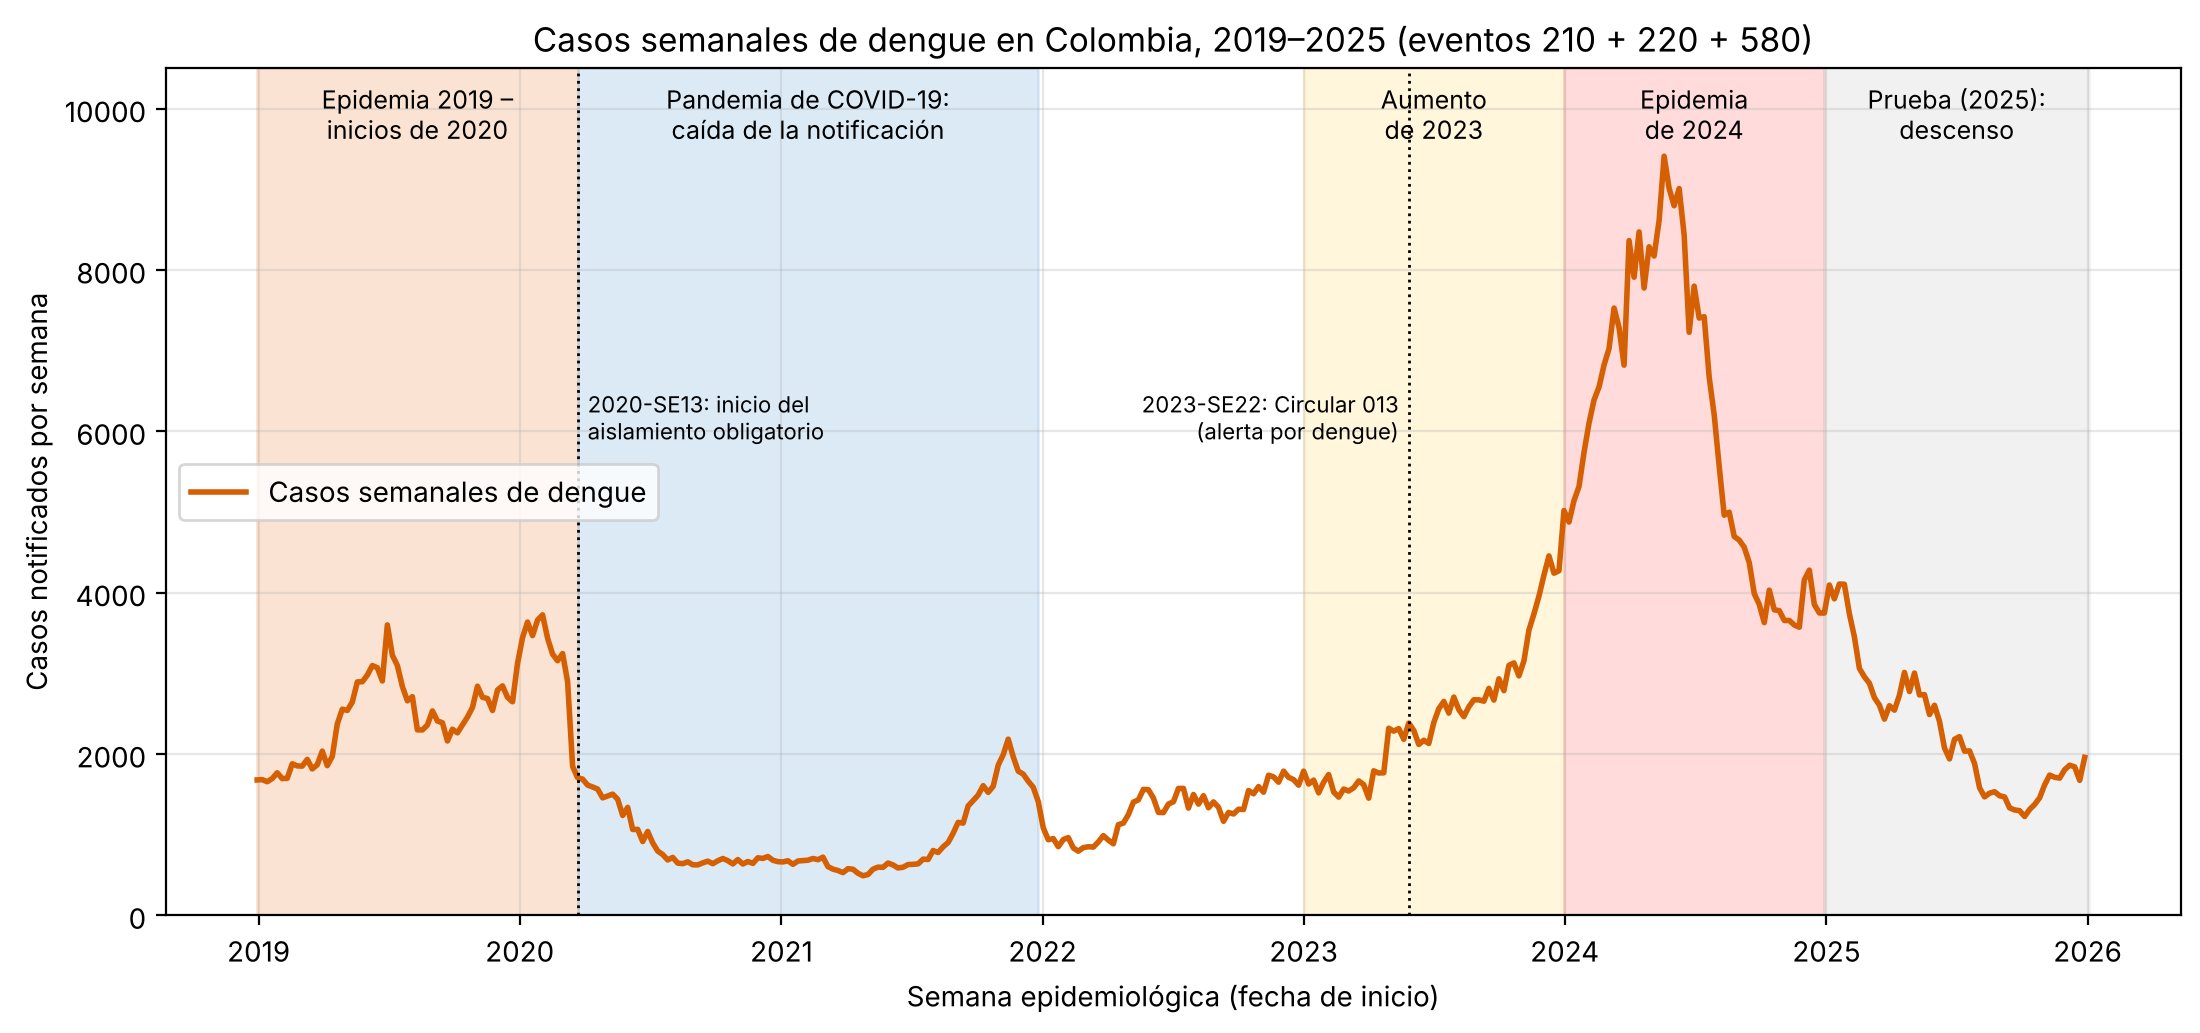

In [9]:
# Serie completa con los cambios de comportamiento señalados
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(datos.index, datos["casos"], color="#D55F03", linewidth=2, label="Casos semanales de dengue")

franjas = [
    ("2018-12-30", "2020-03-22", "#F4B183", "Epidemia 2019 –\ninicios de 2020"),
    ("2020-03-22", "2021-12-26", "#9DC3E6", "Pandemia de COVID-19:\ncaída de la notificación"),
    ("2023-01-01", "2023-12-31", "#FFE699", "Aumento\nde 2023"),
    ("2023-12-31", "2024-12-29", "#FF9999", "Epidemia\nde 2024"),
    ("2024-12-29", "2026-01-03", "#D9D9D9", "Prueba (2025):\ndescenso"),
]
for inicio, fin, color, texto in franjas:
    ax.axvspan(pd.Timestamp(inicio), pd.Timestamp(fin), color=color, alpha=0.35)
    ax.text(pd.Timestamp(inicio) + (pd.Timestamp(fin) - pd.Timestamp(inicio)) / 2, 10300, texto, ha="center", va="top", fontsize=9)

# Fechas de referencia documentadas
ax.axvline(pd.Timestamp("2020-03-22"), color="black", linestyle=":", linewidth=1)
ax.text(pd.Timestamp("2020-04-05"), 6500, "2020-SE13: inicio del\naislamiento obligatorio", fontsize=8, va="top")
ax.axvline(pd.Timestamp("2023-05-28"), color="black", linestyle=":", linewidth=1)
ax.text(pd.Timestamp("2023-05-14"), 6500, "2023-SE22: Circular 013\n(alerta por dengue)", fontsize=8, va="top", ha="right")

ax.set_ylim(0, 10500)
ax.set_xlabel("Semana epidemiológica (fecha de inicio)")
ax.set_ylabel("Casos notificados por semana")
ax.set_title("Casos semanales de dengue en Colombia, 2019–2025 (eventos 210 + 220 + 580)")
ax.legend(loc="center left")
ax.grid(True, alpha=0.3)
plt.show()

**Interpretación: cambios de comportamiento y sus causas**

| Periodo | Qué se ve en la serie | Causa documentada |
| :--- | :--- | :--- |
| **2019 – inicios de 2020** | Epidemia, con máximos de 3 599 casos (2019-SE27) y 3 724 casos (2020-SE06) | 2019 fue un año epidémico en toda la región. La OPS reportó más de 3 millones de casos de dengue en las Américas, el mayor número registrado hasta ese momento, y 127 553 casos en Colombia [1]. (Los datos depurados de este cuaderno suman 125 111 para 2019.) |
| **2020-SE12 a 2021** | Caída brusca y niveles muy bajos: mediana de 913.0 casos semanales en 2020 y media de 968.1 en 2021, con el mínimo de toda la serie (489 casos) | Coincide con la **pandemia de COVID-19**. Un estudio en 23 países del sudeste asiático y América Latina encontró que la incidencia de dengue cayó 44.1 % en 2020 y asoció la caída con las medidas de la pandemia, sobre todo el cierre de colegios y la menor movilidad [2]. También influye que la epidemia de 2019–2020 ya venía terminando. |
| **2022** | Niveles bajos y en lenta subida (media de 1 290.7 casos) | Periodo entre epidemias. |
| **2023** | Aumento sostenido, hasta 4 454 casos en la semana 50 | El 30 de mayo de 2023, Minsalud, la Supersalud y el INS emitieron la Circular Conjunta Externa 013 por el aumento del dengue: a la semana 18, los casos superaban en más del 100 % los del mismo periodo de 2017, 2018, 2021 y 2022. La circular recuerda que el dengue tiene picos epidémicos cada tres a cuatro años y advierte sobre el fenómeno de El Niño, que lleva a almacenar agua y favorece los criaderos del mosquito [3]. |
| **2024** | Gran epidemia: 312 927 casos en el año y un máximo de 9 410 casos en la semana 21 | Fue la mayor epidemia de dengue registrada en las Américas: más de 12.6 millones de casos, con Argentina, Brasil, Colombia y México concentrando el 90 % [4]. El propio INS trata 2024 como periodo epidémico y lo excluye de sus análisis históricos (BES de la semana 38 de 2026, página 12). |
| **2025 (prueba)** | Descenso después de la epidemia: de 4 106 casos en la semana 4 a 1 224 en la semana 41, con una leve subida al final | Regreso gradual a los niveles habituales. |

- **Sobre la subnotificación en 2020–2021:** es posible que parte de la caída se deba a que durante la pandemia se consultó y se notificó menos, pero **no se encontró una fuente que la cuantifique para Colombia**. Se deja como una posibilidad, no como un hecho.
- **No hay un patrón anual fijo:** lo que domina la serie son **ciclos epidémicos de varios años**. Esto será importante para entender los resultados: el canal resume "lo normal" de cada semana del año, y en esta serie los años se parecen poco entre sí.

**Fuentes**

[1] OPS (12 de febrero de 2020). *Los casos de dengue en las Américas superaron los 3 millones en 2019.* https://www.paho.org/es/noticias/12-2-2020-casos-dengue-americas-superaron-3-millones-2019

[2] Chen Y, Li N, Lourenço J, et al. (2022). Measuring the effects of COVID-19-related disruption on dengue transmission in southeast Asia and Latin America: a statistical modelling study. *The Lancet Infectious Diseases*, 22(5), 657–667. https://doi.org/10.1016/S1473-3099(22)00025-1

[3] Ministerio de Salud y Protección Social, Superintendencia Nacional de Salud e Instituto Nacional de Salud (30 de mayo de 2023). *Circular Conjunta Externa 013 de 2023.* https://normograma.supersalud.gov.co/compilacion/docs/circular_minsaludps_0013_2023.htm

[4] OPS (10 de diciembre de 2024). *La OPS destaca el aumento de casos de dengue, Oropouche y gripe aviar en las Américas, y recomienda medidas de control.* https://www.paho.org/es/noticias/10-12-2024-ops-destaca-aumento-casos-dengue-oropouche-gripe-aviar-americas-recomienda

### 3.3 Comportamiento de la serie y descomposición STL

Los datos son semanales y el ciclo anual tiene unas 52 semanas, así que la STL se hace con `period=52` (en el taller era 365 porque los datos eran diarios). Desde aquí, todo el análisis se hace con el entrenamiento (2019–2024).

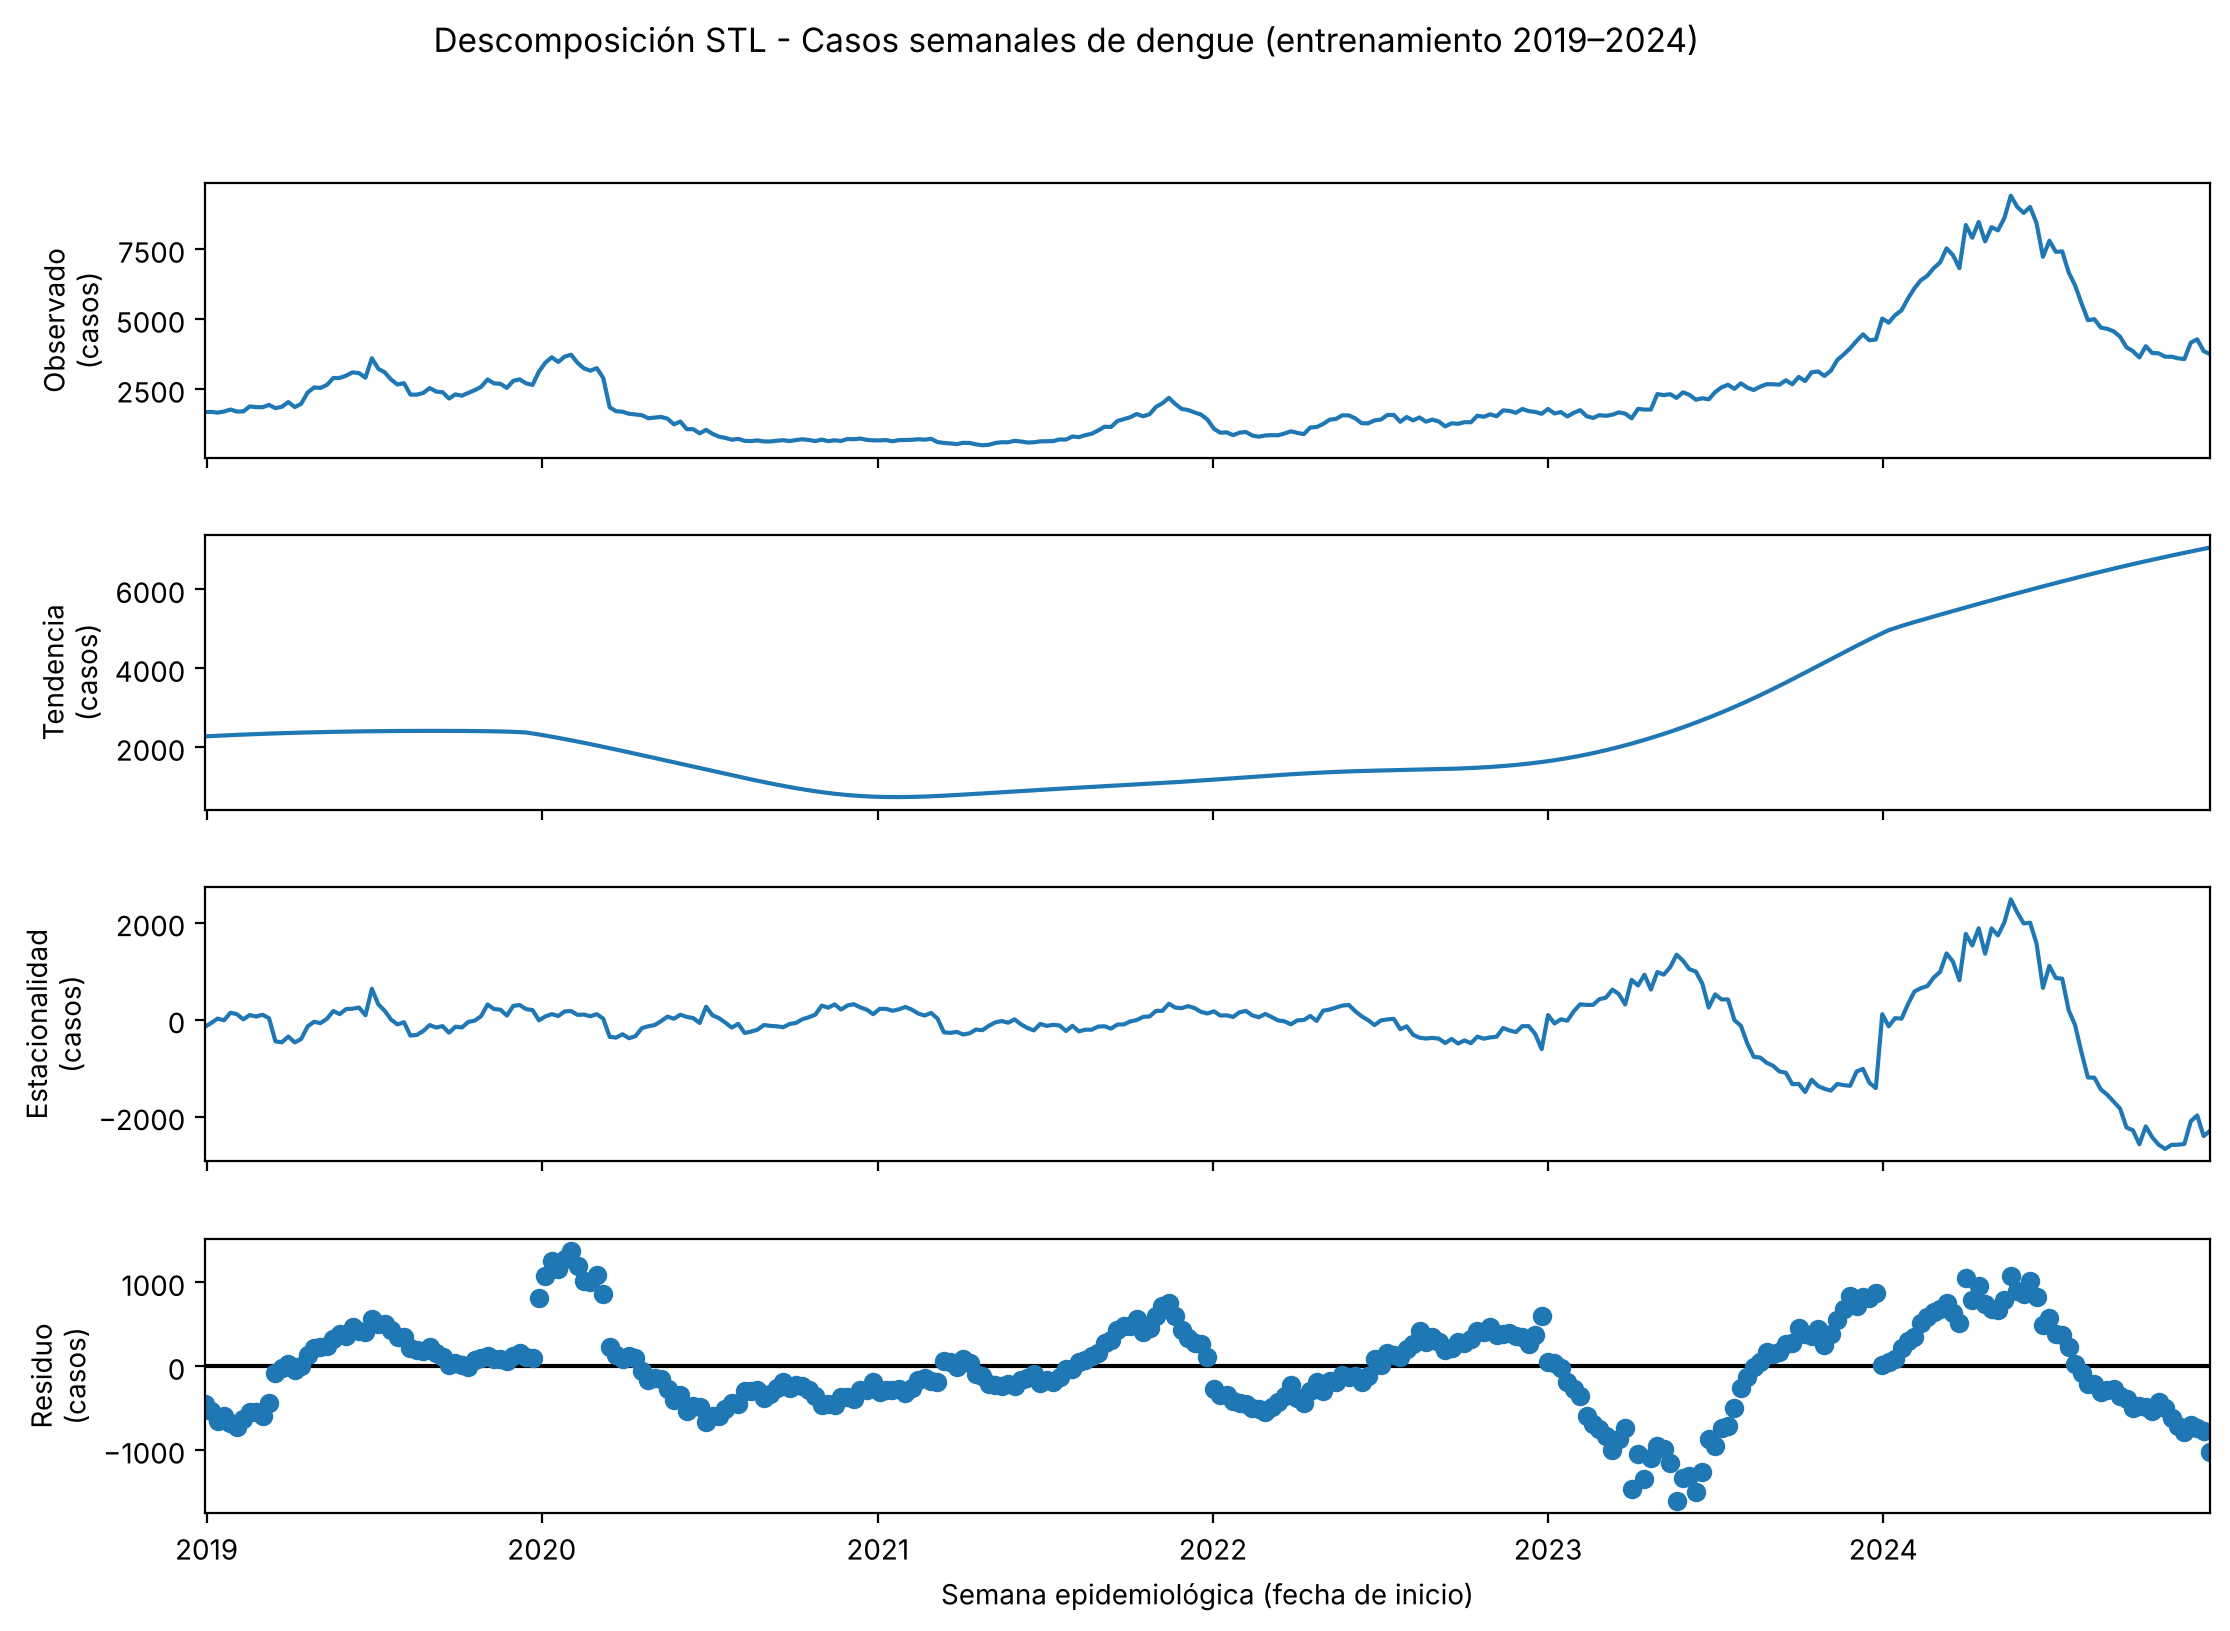

In [10]:
# Descomposicion STL de los casos (ciclo anual = 52 semanas)
stl_casos = STL(serie_train, period=52).fit()
fig = stl_casos.plot()
fig.set_size_inches(12, 8)
for ax, nombre in zip(fig.axes, ["Observado\n(casos)", "Tendencia\n(casos)", "Estacionalidad\n(casos)", "Residuo\n(casos)"]):
    ax.set_ylabel(nombre)
    ax.set_title("")
fig.axes[-1].set_xlabel("Semana epidemiológica (fecha de inicio)")
fig.suptitle("Descomposición STL - Casos semanales de dengue (entrenamiento 2019–2024)", y=1.02)
plt.show()

In [11]:
# Fuerza de la tendencia y de la estacionalidad
def fuerza_stl(stl_fit):
    Ft = max(0, 1 - stl_fit.resid.var() / (stl_fit.trend + stl_fit.resid).var())
    Fs = max(0, 1 - stl_fit.resid.var() / (stl_fit.seasonal + stl_fit.resid).var())
    return round(Ft, 4), round(Fs, 4)

tab_fuerza = pd.DataFrame({
    "Serie" : ["Casos de dengue"],
    "Fuerza tendencia" : [fuerza_stl(stl_casos)[0]],
    "Fuerza estacionalidad" : [fuerza_stl(stl_casos)[1]]
})
tab_fuerza

,Serie,Fuerza tendencia,Fuerza estacionalidad
0,Casos de dengue,0.9255,0.7275


**Interpretación**

- **Tendencia:** su fuerza es alta (≈0.93), pero no es un crecimiento sostenido. Baja entre 2020 y 2021, sube desde 2023 y se dispara con la epidemia de 2024. El aumento al final de la gráfica es en parte un efecto de borde de la STL.
- **Estacionalidad:** su fuerza también es alta (≈0.73), pero hay que leerla con cuidado. La STL deja que la estacionalidad cambie de un año a otro, y lo que hace es **absorber la forma de la epidemia de 2024**: el componente estacional es casi plano entre 2019 y 2022 y luego oscila con fuerza en 2023–2024. **No hay un patrón anual estable** que se repita igual cada año.
- **Residuo:** sigue mostrando ondas largas, no ruido puro, lo que confirma que la dinámica del dengue está dominada por **ciclos epidémicos de varios años** más que por la época del año.

### 3.4 Quiebres estructurales

Un quiebre estructural es un cambio permanente en el comportamiento de la serie (en su nivel, su tendencia o su dinámica). Se aplican dos pruebas, las dos con el entrenamiento:

**Prueba de Chow.** Compara una regresión estimada con toda la muestra frente a dos regresiones separadas, antes y después de una fecha candidata. H0: los coeficientes son iguales antes y después (no hay quiebre). Si p < 0.05 hay quiebre. Se prueba con dos especificaciones:
- **Determinista:** $Casos_t = a + b \cdot t + e_t$ (un nivel y una tendencia fijos).
- **AR(1):** $Casos_t = a + b \cdot Casos_{t-1} + e_t$ (los casos de esta semana dependen de los de la semana anterior).

Las **fechas candidatas** se escogen por hechos documentados, no mirando los datos:
- **2020-SE13** (22 al 28 de marzo de 2020): inicio del aislamiento preventivo obligatorio por COVID-19 en Colombia (Decreto 457 de 2020, vigente desde el 25 de marzo).
- **2023-SE22** (28 de mayo al 3 de junio de 2023): Circular Conjunta Externa 013 del 30 de mayo de 2023, en la que Minsalud, Supersalud y el INS dan instrucciones para el control del dengue por el aumento de casos.
- **2024-SE01:** inicio de 2024, año que el INS excluye de sus análisis históricos de dengue por ser un periodo epidémico (BES de la semana 38 de 2026, página 12).

**Prueba de Zivot-Andrews.** Es una prueba de raíz unitaria que permite **un quiebre en una fecha desconocida**, que la misma prueba busca. H0: la serie tiene raíz unitaria. H1: la serie es estacionaria alrededor de un nivel (o tendencia) con un quiebre. Sirve para saber si la no estacionariedad de la serie se debe solo a un cambio de nivel puntual o si se mantiene aun permitiendo ese cambio.

In [12]:
# Prueba de Chow: ¿cambian los coeficientes de la regresion antes y despues de una fecha candidata?
def prueba_chow(y, X, fecha_quiebre):
    antes = y.index < fecha_quiebre
    k = X.shape[1]
    sce_total = sm.OLS(y, X).fit().ssr
    sce_antes = sm.OLS(y[antes], X[antes]).fit().ssr
    sce_despues = sm.OLS(y[~antes], X[~antes]).fit().ssr
    gl = len(y) - 2 * k
    F = ((sce_total - sce_antes - sce_despues) / k) / ((sce_antes + sce_despues) / gl)
    return F, 1 - stats.f.cdf(F, k, gl), int(antes.sum()), int((~antes).sum())

# Dos especificaciones, las dos con el entrenamiento:
# (1) Modelo determinista: casos_t = a + b*t + e_t
# (2) Modelo AR(1):        casos_t = a + b*casos_{t-1} + e_t
y_det = serie_train
X_det = sm.add_constant(pd.DataFrame({"t": np.arange(1, len(serie_train) + 1)}, index=serie_train.index))
ar1 = pd.DataFrame({"y": serie_train, "y_1": serie_train.shift(1)}).dropna()
y_ar1, X_ar1 = ar1["y"], sm.add_constant(ar1[["y_1"]])

fechas_candidatas = {
    "2020-SE13 (inicio del aislamiento por COVID-19)" : pd.Timestamp("2020-03-22"),
    "2023-SE22 (Circular 013 de 2023, alerta por dengue)" : pd.Timestamp("2023-05-28"),
    "2024-SE01 (inicio del año epidémico 2024)" : pd.Timestamp("2023-12-31"),
}
filas = []
for nombre, fecha in fechas_candidatas.items():
    for especificacion, (y_, X_) in {"Determinista (constante + tendencia)": (y_det, X_det), "AR(1)": (y_ar1, X_ar1)}.items():
        F, p_valor, n_antes, n_despues = prueba_chow(y_, X_, fecha)
        filas.append({"Fecha candidata": nombre, "Modelo": especificacion, "Semanas antes": n_antes, "Semanas después": n_despues,
                      "Estadístico F": round(F, 3), "P-valor": round(p_valor, 4), "Quiebre (5%)": "Sí" if p_valor < 0.05 else "No"})
tab_chow = pd.DataFrame(filas)

print("=" * 110)
print("PRUEBA DE CHOW (H0: no hay quiebre estructural en la fecha candidata)")
print("=" * 110)
print(tab_chow.to_string(index=False))
print("=" * 110)

# Autocorrelacion de los residuos de cada especificacion (la prueba de Chow supone errores no autocorrelacionados)
for especificacion, (y_, X_) in {"Determinista": (y_det, X_det), "AR(1)": (y_ar1, X_ar1)}.items():
    r1 = sm.OLS(y_, X_).fit().resid.autocorr(1)
    print(f"Autocorrelación de orden 1 de los residuos, modelo {especificacion}: {r1:.3f}")

PRUEBA DE CHOW (H0: no hay quiebre estructural en la fecha candidata)
                                    Fecha candidata                               Modelo  Semanas antes  Semanas después  Estadístico F  P-valor Quiebre (5%)
    2020-SE13 (inicio del aislamiento por COVID-19) Determinista (constante + tendencia)             64              249        113.847   0.0000           Sí
    2020-SE13 (inicio del aislamiento por COVID-19)                                AR(1)             63              249          1.295   0.2754           No
2023-SE22 (Circular 013 de 2023, alerta por dengue) Determinista (constante + tendencia)            230               83        156.910   0.0000           Sí
2023-SE22 (Circular 013 de 2023, alerta por dengue)                                AR(1)            229               83          1.963   0.1421           No
          2024-SE01 (inicio del año epidémico 2024) Determinista (constante + tendencia)            261               52        254.159   0.

In [13]:
# Prueba de Zivot-Andrews: raiz unitaria permitiendo UN quiebre estructural en una fecha desconocida
# H0: la serie tiene raiz unitaria (sin quiebre). H1: la serie es estacionaria con un quiebre.
filas = []
for regresion, nombre in {"c": "Quiebre en el nivel", "ct": "Quiebre en el nivel y la tendencia"}.items():
    za_est, za_p, za_crit, za_rezagos, za_pos = zivot_andrews(serie_train, regression=regresion, autolag="AIC")
    filas.append({"Especificación": nombre, "Estadístico": round(za_est, 3), "P-valor": round(za_p, 4),
                  "Valor crítico 5%": round(za_crit["5%"], 3), "Estacionaria con quiebre": "Sí" if za_p < 0.05 else "No",
                  "Fecha más probable del quiebre": f"{int(train['ANO'].iloc[za_pos])}-SE{int(train['SEMANA'].iloc[za_pos]):02d}"})
tab_za = pd.DataFrame(filas)

print("=" * 110)
print("PRUEBA DE ZIVOT-ANDREWS")
print("=" * 110)
print(tab_za.to_string(index=False))
print("=" * 110)

PRUEBA DE ZIVOT-ANDREWS
                    Especificación  Estadístico  P-valor  Valor crítico 5% Estacionaria con quiebre Fecha más probable del quiebre
               Quiebre en el nivel       -4.316   0.1850            -4.811                       No                      2023-SE44
Quiebre en el nivel y la tendencia       -3.899   0.5725            -5.073                       No                      2021-SE46


**Interpretación**

**Prueba de Chow**
- **Con el modelo determinista (constante + tendencia), hay quiebre en las tres fechas** (F = 113.8, 156.9 y 254.2; p < 0.001). Confirma lo que se ve en la gráfica: el nivel y la tendencia de la serie no son los mismos antes y después de la pandemia, del aumento de 2023 ni de la epidemia de 2024. Sin embargo, este resultado hay que leerlo con cuidado: los residuos de ese modelo tienen una autocorrelación de 0.990, y la prueba de Chow supone errores sin autocorrelación, así que tiende a encontrar quiebres con demasiada facilidad.
- **Con el modelo AR(1), no hay quiebre en ninguna fecha** (F = 1.295, 1.963 y 0.718; p = 0.2754, 0.1421 y 0.4885). Sus residuos casi no tienen autocorrelación (−0.048), así que aquí la prueba es más confiable. Significa que la relación entre los casos de una semana y los de la semana anterior **es la misma antes y después** de cada fecha.
- **Lectura conjunta:** el nivel de la serie sí cambia, pero no salta de un valor fijo a otro. Cambia de forma gradual, y la propia memoria de la serie (los casos de la semana anterior) alcanza para explicar esos cambios.

**Prueba de Zivot-Andrews**
- Aun permitiendo un quiebre, **no se rechaza la raíz unitaria**: con quiebre en el nivel el estadístico es −4.316 (valor crítico −4.811, p = 0.185), y con quiebre en el nivel y la tendencia es −3.899 (valor crítico −5.073, p = 0.5725).
- Las fechas más probables del quiebre serían 2023-SE44 y 2021-SE46, pero ninguna alcanza a volver estacionaria la serie.

**Conclusión para el modelado**
- La no estacionariedad de la serie **no se debe a un cambio de nivel puntual** que se pueda corregir con una variable indicadora. Se comporta como una **tendencia estocástica**, que se trata con **una diferencia (d = 1)**, como confirman las pruebas ADF y KPSS de la sección 3.6.
- Por eso los modelos no incluyen variables para los quiebres.
- **Limitación:** la prueba de Chow también supone varianza constante, y en 2024 los errores son mucho más grandes que en el resto de la serie.
- **Relación con el canal endémico:** estos cambios de nivel son justo lo que el canal detecta como alerta o brote. Un modelo con d = 1 los sigue semana a semana, pero no puede saber cuándo empiezan ni cuándo terminan.

### 3.5 Variable exógena: términos de Fourier

En el taller la variable exógena era la temperatura. Aquí se usan **términos de Fourier**: pares de ondas seno y coseno con periodo de un año que el modelo combina para dibujar la forma de la estacionalidad anual.

$$ S_{k,t} = \sin\left(\frac{2\pi k t}{m}\right), \qquad C_{k,t} = \cos\left(\frac{2\pi k t}{m}\right), \qquad k = 1, \dots, K $$

- $t$ es el número de la semana (1, 2, 3, …) y $m = 365.25/7 \approx 52.18$ semanas es la duración promedio de un año.
- $K$ es el número de **armónicos**. Con $K = 1$ la estacionalidad es una sola onda suave por año. Con más armónicos la forma puede ser más detallada, pero se agregan más parámetros.

**¿Por qué Fourier y no un SARIMA con s = 52?**
- Un SARIMA con s = 52 necesita muchos años de datos y estima la estacionalidad de forma muy rígida (un rezago de 52 semanas). Con Fourier, toda la estacionalidad anual se resume en $2K$ coeficientes.
- Los términos de Fourier **se conocen de antemano para cualquier semana futura**, porque solo dependen del calendario. Con una variable climática habría que pronosticar también el clima de 2025.

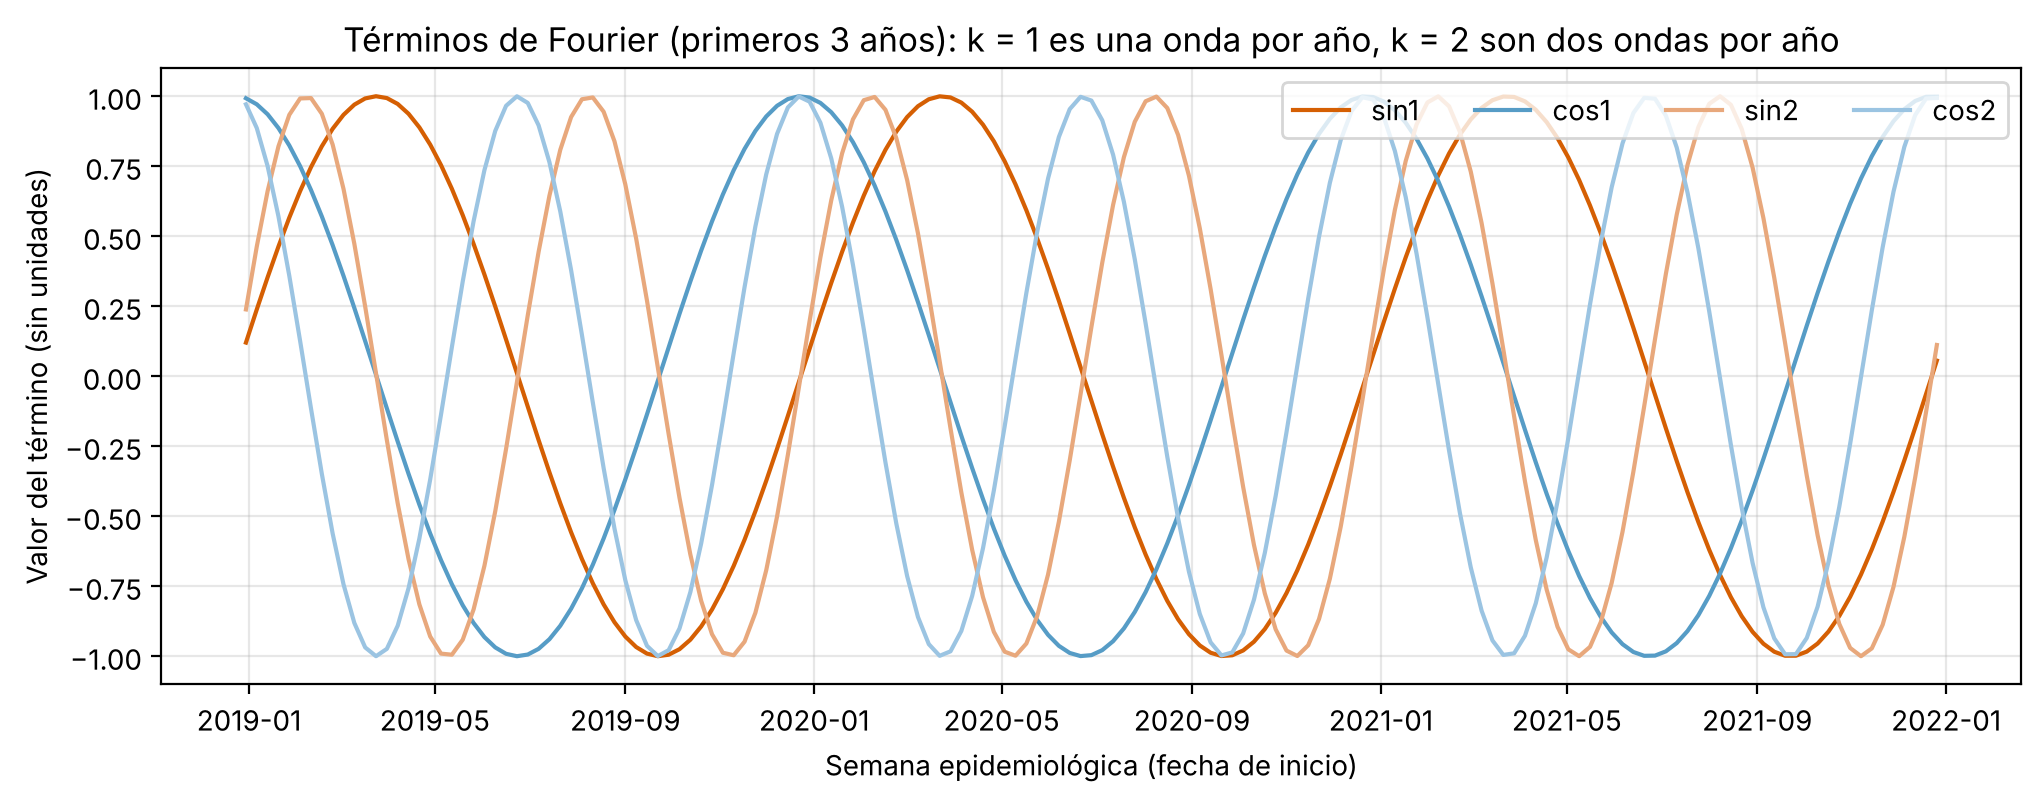

In [14]:
# Terminos de Fourier para toda la serie (entrenamiento + prueba), periodo anual de 52.18 semanas
periodo_anual = 365.25 / 7
t_semana = np.arange(1, len(datos) + 1)
fourier = pd.DataFrame(index=datos.index)
for k in range(1, 6):
    fourier[f"sin{k}"] = np.sin(2 * np.pi * k * t_semana / periodo_anual)
    fourier[f"cos{k}"] = np.cos(2 * np.pi * k * t_semana / periodo_anual)

fig, ax = plt.subplots(figsize=(12, 4))
for col, color in zip(["sin1", "cos1", "sin2", "cos2"], ["#D55F03", "#569CC6", "#E8A87C", "#9BC4E2"]):
    ax.plot(fourier.index[:157], fourier[col][:157], label=col, color=color)
ax.set_title("Términos de Fourier (primeros 3 años): k = 1 es una onda por año, k = 2 son dos ondas por año")
ax.set_xlabel("Semana epidemiológica (fecha de inicio)")
ax.set_ylabel("Valor del término (sin unidades)")
ax.legend(loc="upper right", ncol=4)
ax.grid(True, alpha=0.3)
plt.show()

In [15]:
# Correlacion de los casos con los terminos de Fourier (entrenamiento)
filas = []
for col in ["sin1", "cos1", "sin2", "cos2", "sin3", "cos3"]:
    r, p_valor = pearsonr(fourier.loc[train.index, col], serie_train)
    filas.append({"Término": col, "Correlación": round(r, 3), "p-valor": round(p_valor, 4), "Significativo (5%)": "Sí" if p_valor < 0.05 else "No"})
pd.DataFrame(filas)

,Término,Correlación,p-valor,Significativo (5%)
0,sin1,0.070,0.2198,No
1,cos1,-0.055,0.3302,No
2,sin2,-0.043,0.4470,No
3,cos2,0.063,0.2641,No
4,sin3,-0.001,0.9868,No
5,cos3,-0.019,0.7421,No


**Interpretación**

- **Correlaciones casi nulas:** las correlaciones de los casos con los términos de Fourier están entre -0.06 y 0.07, y ninguna es significativa (todos los p-valores > 0.2). Es decir, **no hay una estacionalidad anual clara** en los casos de 2019–2024, lo cual coincide con la STL.
- **Esto no significa que la época del año no importe:** las epidemias empiezan y terminan en momentos distintos de cada año, así que un patrón fijo por calendario explica poco de la serie. Aun así se incluyen los términos de Fourier en el SARIMAX para comprobar si aportan algo una vez que el ARIMA modela la dinámica de corto plazo.

### 3.6 Pruebas de estacionariedad
- **ADF:** H0: la serie tiene raíz unitaria (no estacionaria). Si p < 0.05 → estacionaria.
- **KPSS:** H0: la serie es estacionaria. Si p < 0.05 → no estacionaria.

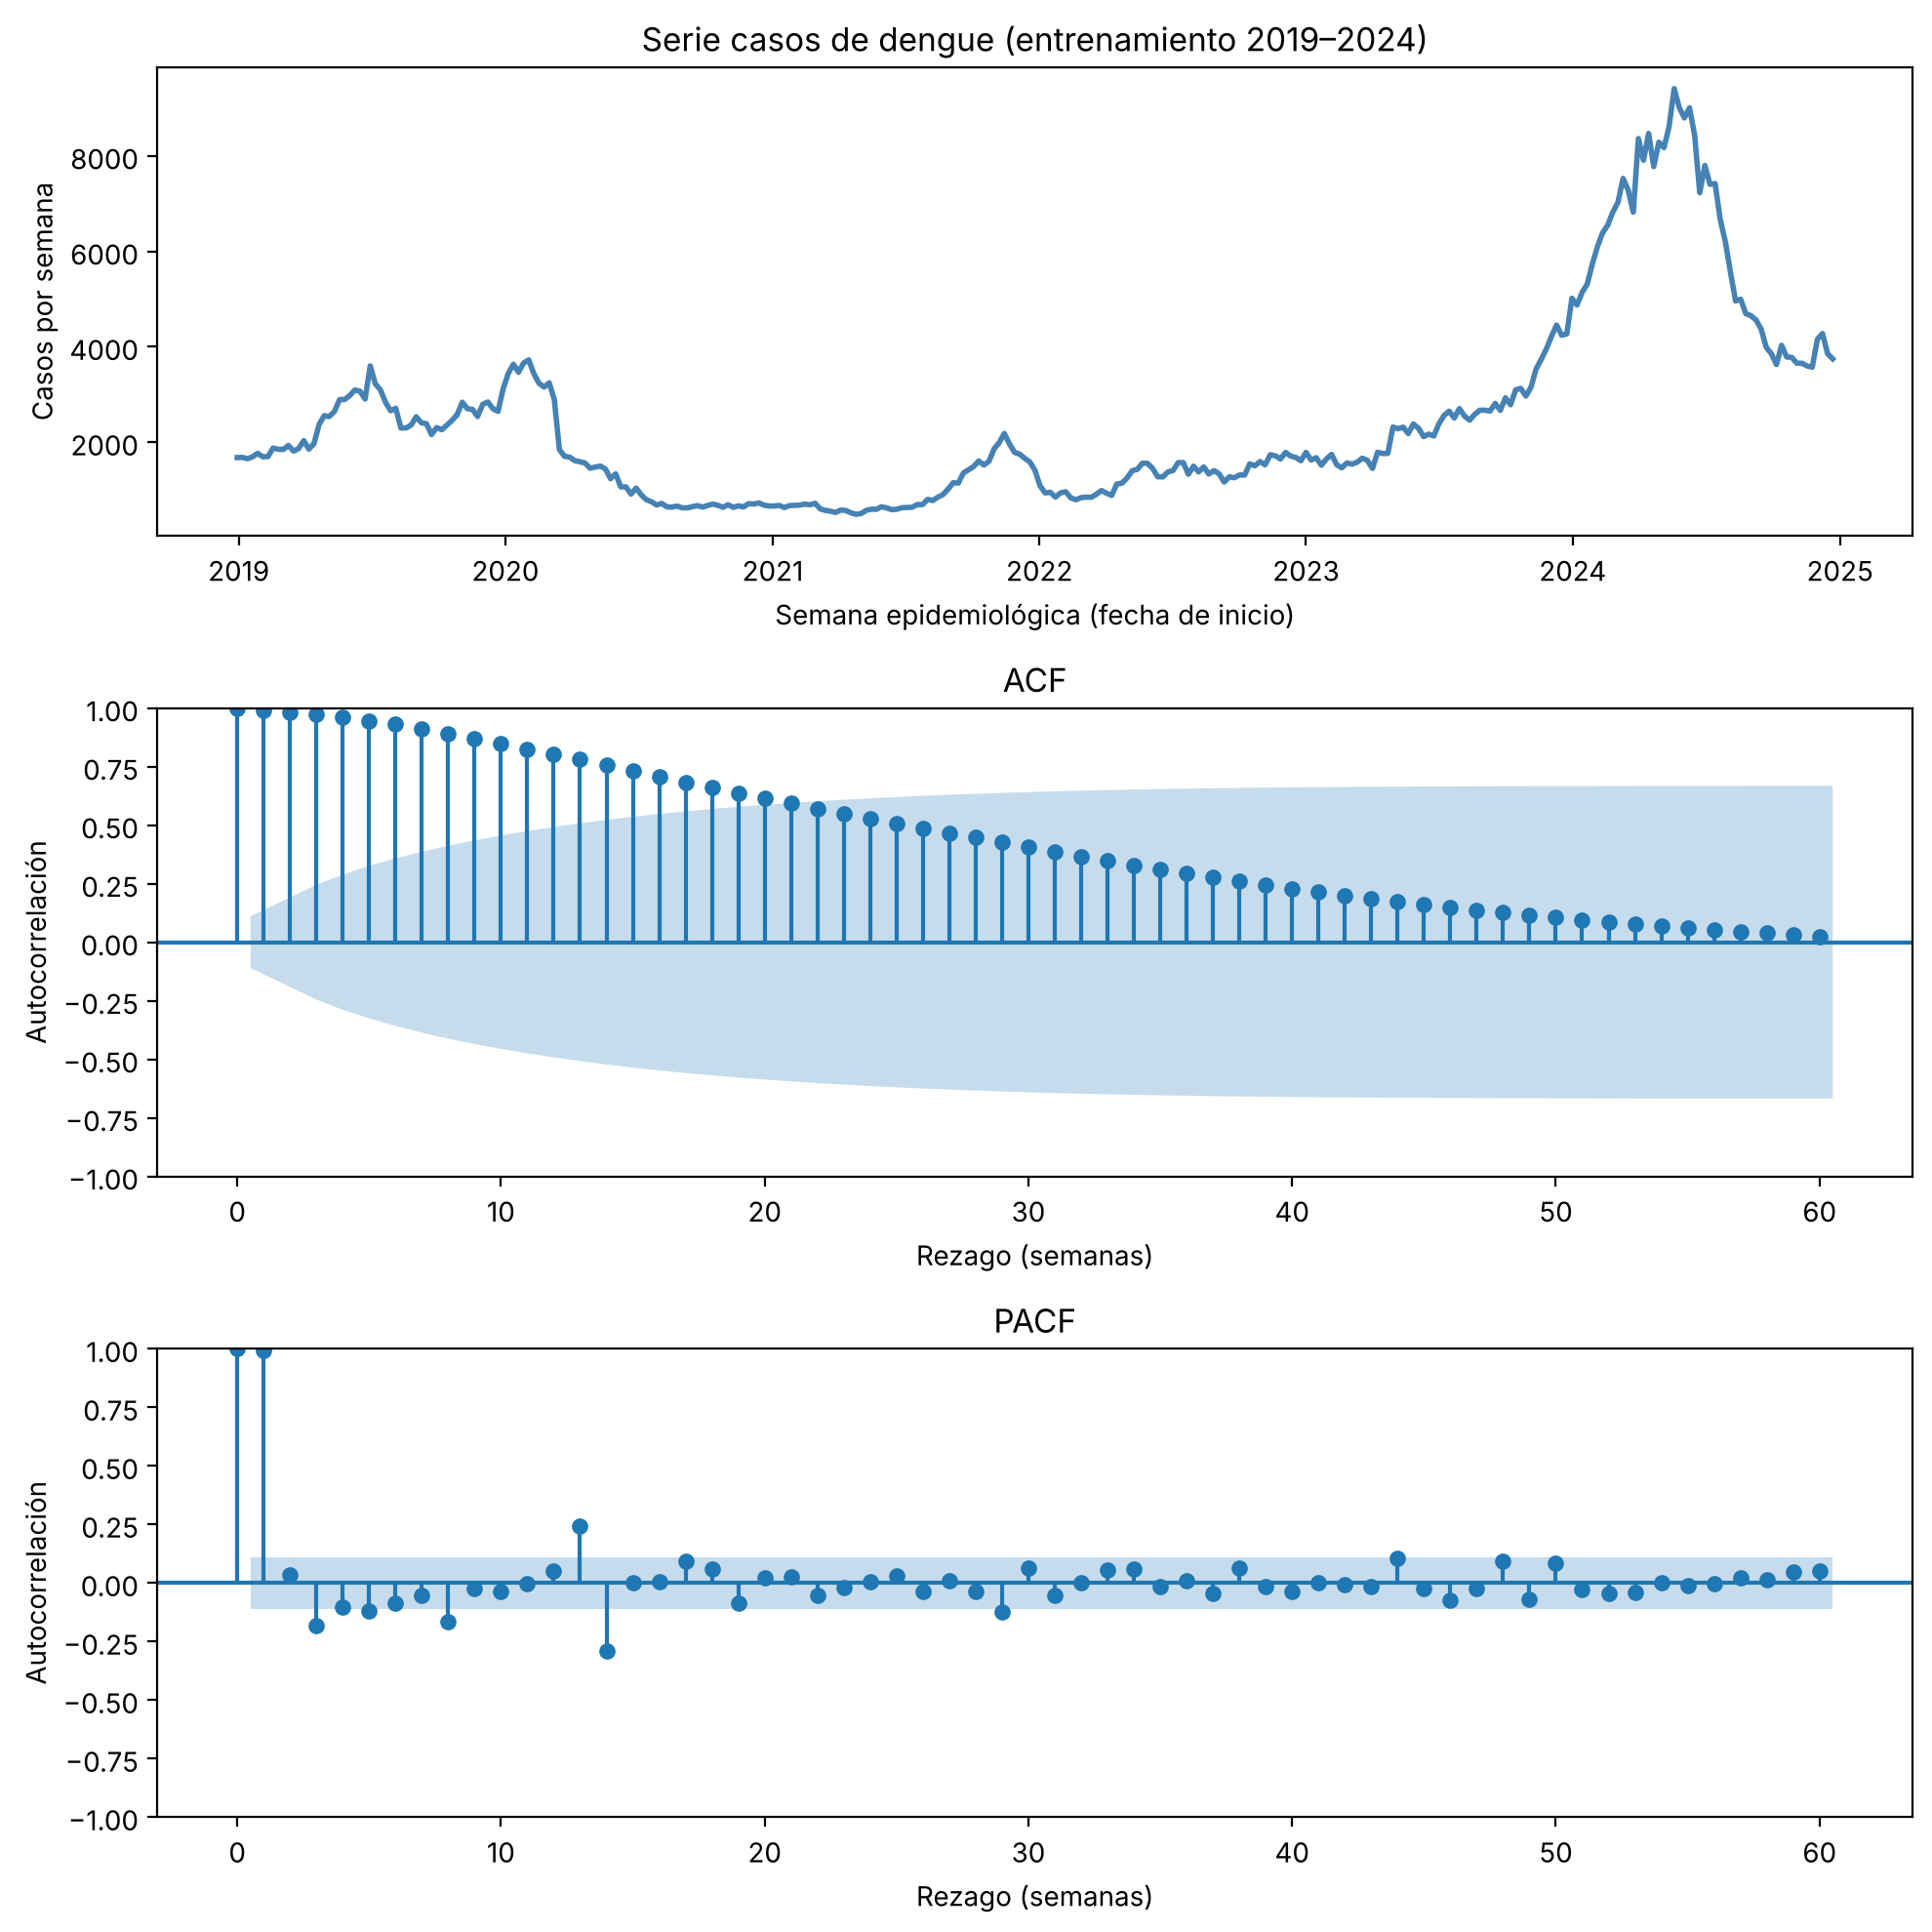

In [16]:
# Sin diferencia
fig, axes = plt.subplots(3, 1, figsize=(10, 10))
axes[0].plot(serie_train.index, serie_train, color='steelblue', linewidth=2)
axes[0].set_title('Serie casos de dengue (entrenamiento 2019–2024)')
axes[0].set_xlabel('Semana epidemiológica (fecha de inicio)')
axes[0].set_ylabel('Casos por semana')
plot_acf(serie_train, ax=axes[1], lags=60, title=f'ACF')
plot_pacf(serie_train, ax=axes[2], lags=60, title=f'PACF')
for ax in axes[1:]:
    ax.set_xlabel('Rezago (semanas)')
    ax.set_ylabel('Autocorrelación')
plt.tight_layout()
plt.show()

In [17]:
def test_estacionariedad(datos):
    # Augmented Dickey-Fuller
    adf_result = adfuller(datos)
    # KPSS
    kpss_result = kpss(datos, regression='c')

    # Tabla de resultados
    tab_test = pd.DataFrame({
        'Test'        : ["Prueba Augmented Dickey-Fuller (ADF)", "Prueba KPSS"],
        'Estadístico' : [round(adf_result[0],  4), round(kpss_result[0],  4)],
        'P-valor'     : [round(adf_result[1], 4), round(kpss_result[1], 4)],
        "Estacionario" : ["Sí" if adf_result[1] < 0.05 else "No", "No" if kpss_result[1] < 0.05 else "Sí"]
    })

    print("=" * 80)
    print("PRUEBA DE ESTACIONARIEDAD")
    print("=" * 80)
    print(tab_test)
    print("=" * 80)


print("Prueba casos de dengue")
test_estacionariedad(serie_train)

Prueba casos de dengue
PRUEBA DE ESTACIONARIEDAD
                                   Test  Estadístico  P-valor Estacionario
0  Prueba Augmented Dickey-Fuller (ADF)      -1.9977   0.2876           No
1                           Prueba KPSS       1.0519   0.0100           No


**Interpretación en niveles**

- **Las dos pruebas coinciden en que la serie no es estacionaria:** la ADF (p ≈ 0.29) no rechaza la raíz unitaria, y la KPSS (p ≈ 0.01) rechaza la estacionariedad.
- **La ACF decae muy lentamente,** con correlaciones mayores a 0.5 hasta unos 25 rezagos, que es la señal típica de una serie no estacionaria.
- Por eso se toma **una primera diferencia**.

In [18]:
# Primera diferencia
diff_serie_train = serie_train.diff().dropna()

print("Prueba casos de dengue diferenciada")
test_estacionariedad(diff_serie_train)

Prueba casos de dengue diferenciada
PRUEBA DE ESTACIONARIEDAD
                                   Test  Estadístico  P-valor Estacionario
0  Prueba Augmented Dickey-Fuller (ADF)      -3.6759   0.0045           Sí
1                           Prueba KPSS       0.1113   0.1000           Sí


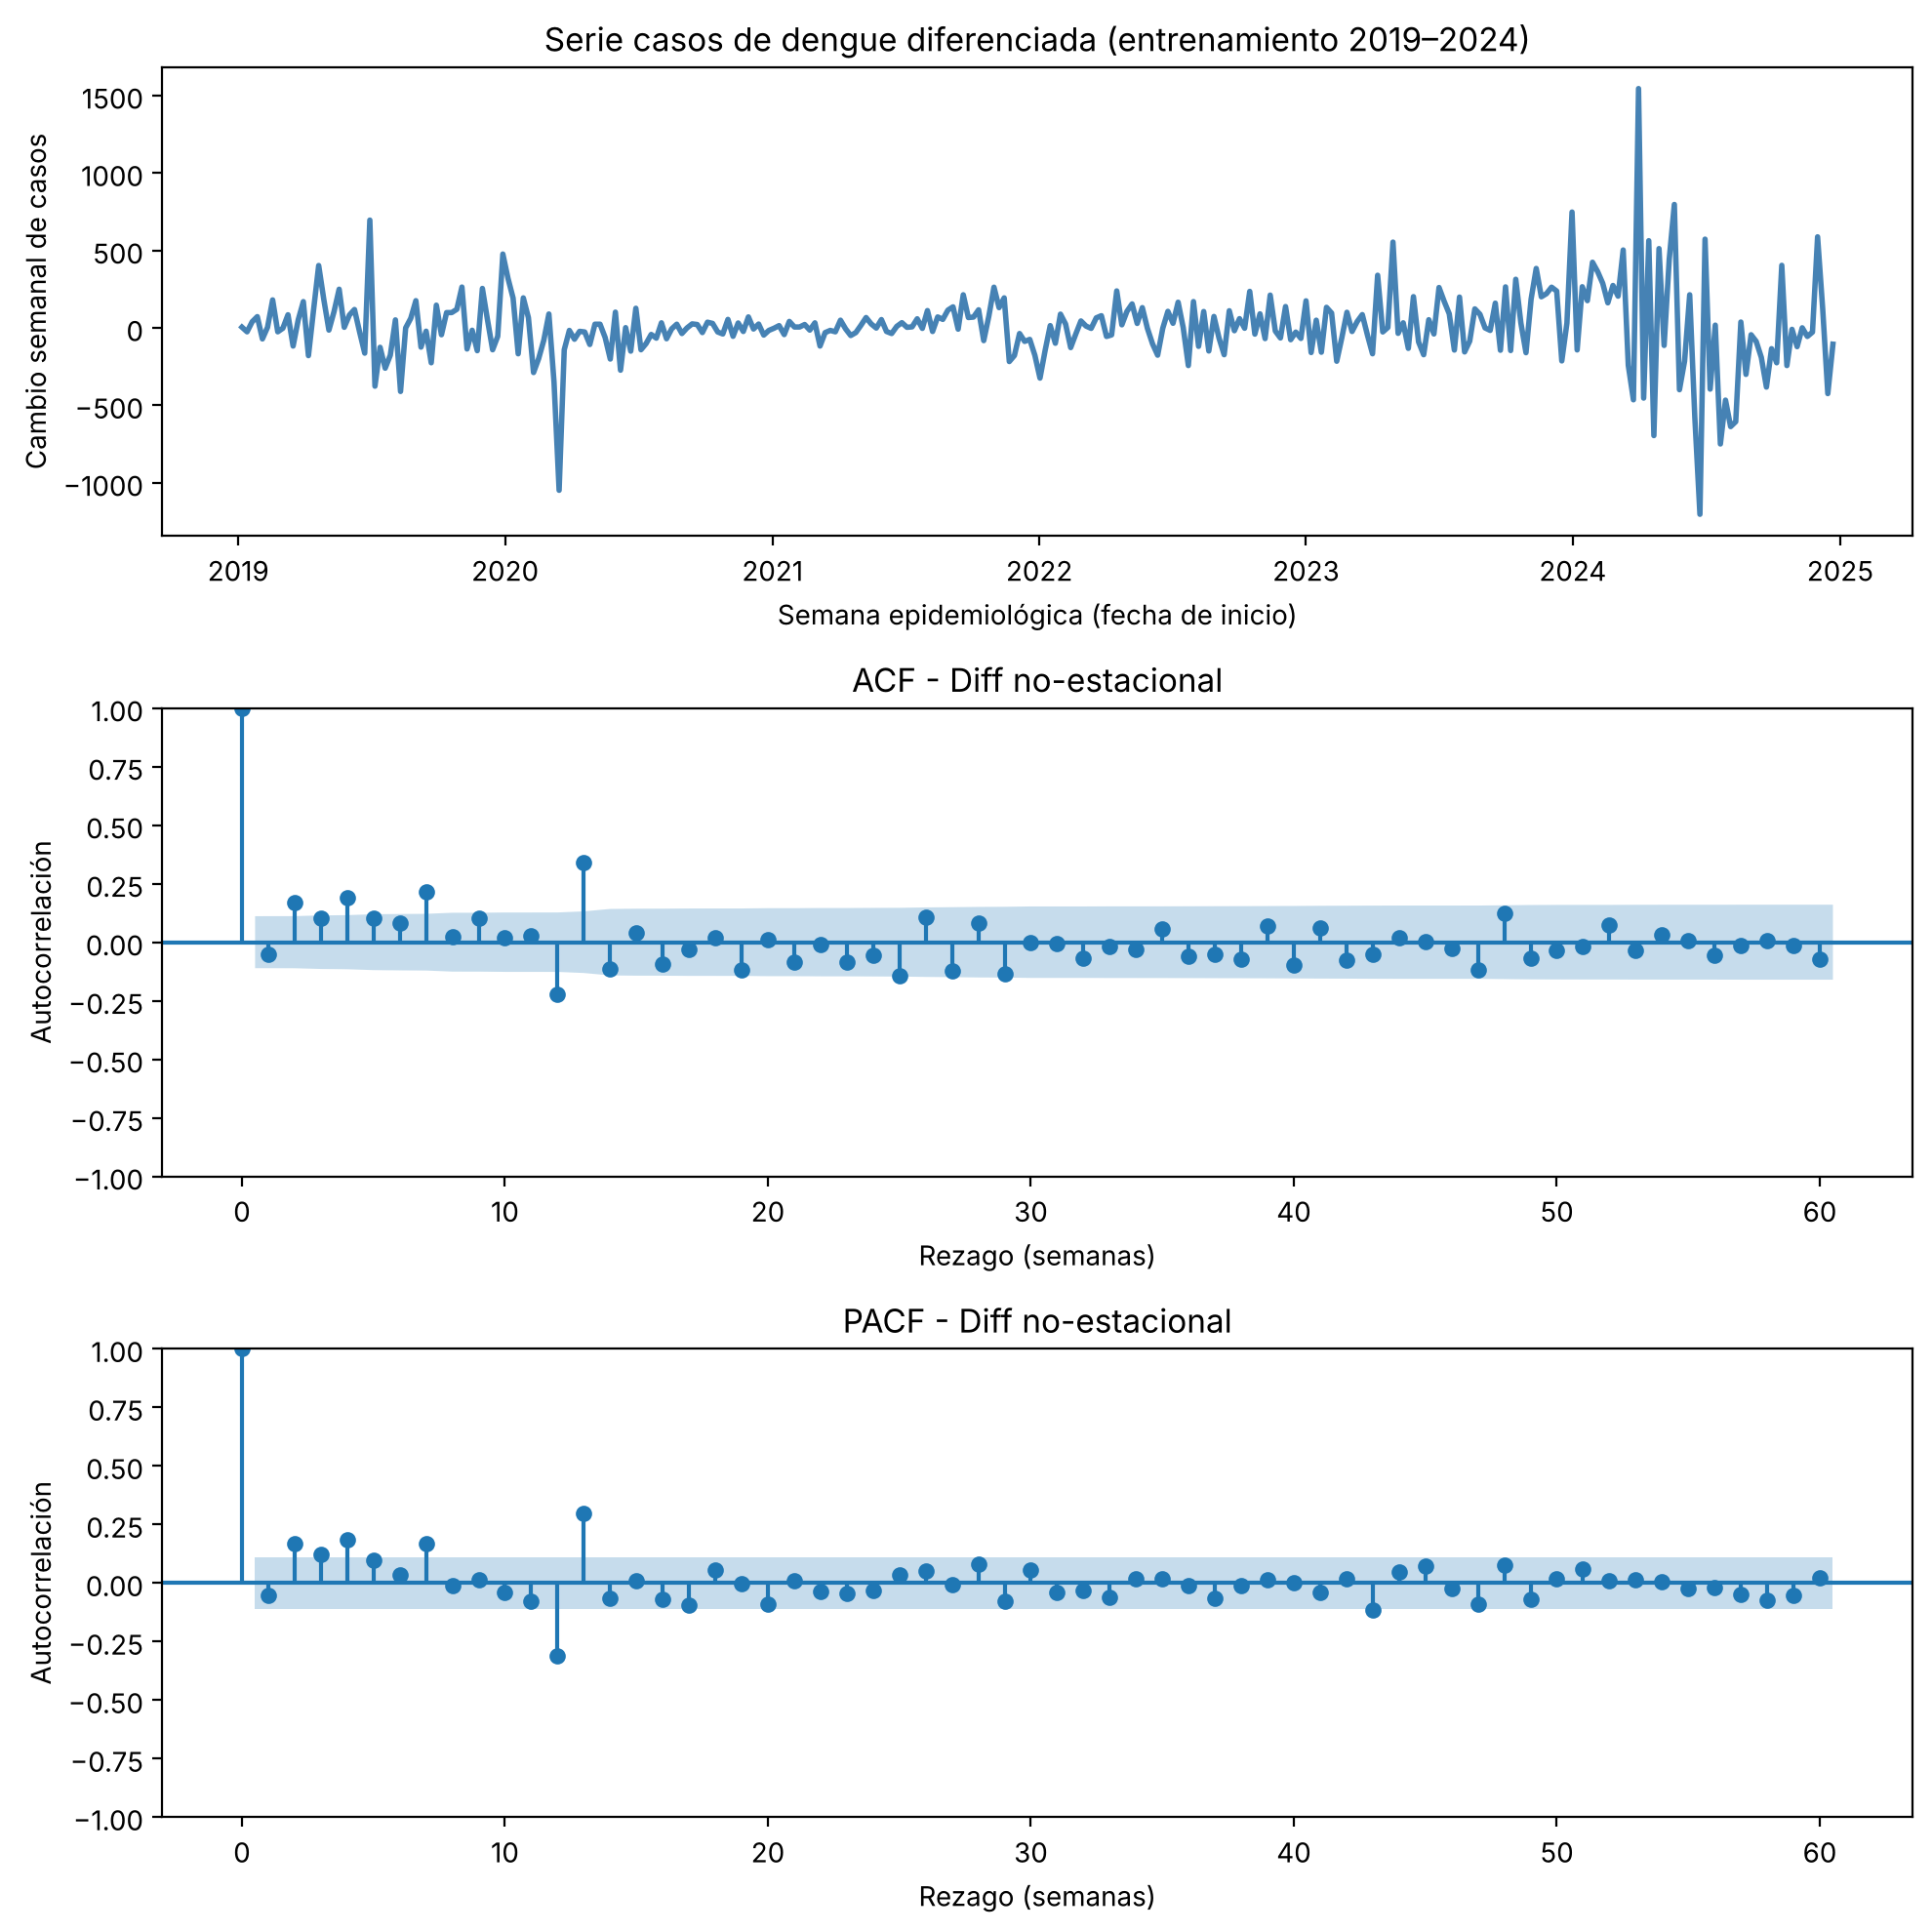

In [19]:
# Primera diferencia
fig, axes = plt.subplots(3, 1, figsize=(10, 10))
axes[0].plot(diff_serie_train.index, diff_serie_train, color='steelblue', linewidth=2)
axes[0].set_title('Serie casos de dengue diferenciada (entrenamiento 2019–2024)')
axes[0].set_xlabel('Semana epidemiológica (fecha de inicio)')
axes[0].set_ylabel('Cambio semanal de casos')
plot_acf(diff_serie_train, ax=axes[1], lags=60, title=f'ACF - Diff no-estacional')
plot_pacf(diff_serie_train, ax=axes[2], lags=60, title=f'PACF - Diff no-estacional')
for ax in axes[1:]:
    ax.set_xlabel('Rezago (semanas)')
    ax.set_ylabel('Autocorrelación')
plt.tight_layout()
plt.show()

In [20]:
# ¿De donde vienen los picos aislados de la ACF en los rezagos 7, 12 y 13? ACF de la serie diferenciada con y sin el año epidemico 2024
diff_sin_2024 = serie_train[train["ANO"] <= 2023].diff().dropna()
filas = []
for nombre, serie in {"Con 2024 (2019–2024)": diff_serie_train, "Sin 2024 (2019–2023)": diff_sin_2024}.items():
    valores = acf(serie, nlags=13)
    banda = 1.96 / np.sqrt(len(serie))
    for k in [7, 12, 13]:
        filas.append({"Serie diferenciada": nombre, "Rezago": k, "ACF": round(valores[k], 3), "Banda (±1.96/√n)": round(banda, 3),
                      "Fuera de la banda": "Sí" if abs(valores[k]) > banda else "No"})
print(pd.DataFrame(filas).to_string(index=False))

  Serie diferenciada  Rezago    ACF  Banda (±1.96/√n) Fuera de la banda
Con 2024 (2019–2024)       7  0.215             0.111                Sí
Con 2024 (2019–2024)      12 -0.222             0.111                Sí
Con 2024 (2019–2024)      13  0.338             0.111                Sí
Sin 2024 (2019–2023)       7  0.035             0.122                No
Sin 2024 (2019–2023)      12 -0.069             0.122                No
Sin 2024 (2019–2023)      13  0.123             0.122                Sí


**Interpretación con primera diferencia**

- **Con una diferencia, la serie es estacionaria según las dos pruebas** (ADF p ≈ 0.005 y KPSS p = 0.10). Por lo tanto, **d = 1**.
- **ACF y PACF de la serie diferenciada:**
  - La **PACF** tiene picos fuera de la banda en los rezagos 2, 3 y 4, y después se mantiene dentro de la banda salvo picos aislados en los rezagos 7, 12 y 13. Esto sugiere una parte **AR de orden 4**.
  - La **ACF** tiene picos en los rezagos 2 y 4 (y aislados en 7, 12 y 13). Esto sugiere una parte **MA de orden 4**.
  - **Los picos aislados en 7, 12 y 13 vienen de la epidemia de 2024.** Con 2024, la ACF en esos rezagos es 0.215, −0.222 y 0.338, fuera de la banda (±0.111). Sin 2024 baja a 0.035, −0.069 y 0.123: los rezagos 7 y 12 quedan dentro de la banda (±0.122) y el 13 queda justo en el borde. Por parsimonia no se modelan.
- **En el rezago 52 no hay un pico importante,** así que la estacionalidad anual es débil, igual que en la STL y la correlación con Fourier.

## 4. Método empírico

Se comparan tres tipos de herramientas sobre los mismos datos:

| Tipo | Herramienta | Qué supone |
| :--- | :--- | :--- |
| **Referencia institucional** | Valor esperado del canal endémico del INS | Pasará lo "normal" para esa semana del año |
| **Referencias estadísticas** | Ingenuo, ingenuo estacional e ingenuo con deriva | Pasará lo mismo que la última semana, que hace un año, o seguirá el cambio promedio |
| **Modelos candidatos** | ARIMA, SARIMA y SARIMAX con términos de Fourier | La dinámica reciente de la serie, estimada con el entrenamiento |

Se sigue la misma metodología del taller: comportamiento de la serie y STL, variable exógena y pruebas de estacionariedad (sección 3), modelos en la ventana de entrenamiento (sección 4.3), pronóstico en la ventana de prueba y elección del mejor modelo (sección 5).

### 4.1 Canal endémico: la referencia institucional (método de las medias geométricas de Bortman)

#### 4.1.1 ¿Cómo se construye?

El canal endémico es el método que usa el INS (página 29 del BES de la semana 38 de 2026): *"El canal endémico nacional […] se construyó con la metodología de medias geométricas (Marcelo Bortman)"*. Para **cada semana epidemiológica** $s$ (1, 2, …, 53):

1. Se toman los casos de esa misma semana en los $n$ años históricos: $x_{1,s}, x_{2,s}, \dots, x_{n,s}$.
2. **Valor esperado** = media geométrica de esos casos:
$$ \bar{x}_{G,s} = \exp\left(\frac{1}{n}\sum_{i=1}^{n} \ln x_{i,s}\right) $$
   Se usa la media geométrica y no la aritmética porque un solo año epidémico infla mucho el promedio aritmético; la geométrica es más resistente a esos valores extremos.
3. **Límites de control (IC 95 %)**:
$$ \text{Límite} = \bar{x}_{G,s} \pm t_{0.975,\,n-1}\cdot\frac{S_s}{\sqrt{n}} $$
   donde $S_s$ es la desviación estándar de los casos de esa semana y $t_{0.975,\,n-1}$ el cuantil de la t de Student. Si el límite inferior da negativo se deja en 0, porque no puede haber casos negativos.

**Zonas del canal** (definiciones del boletín):

| Zona | Condición | Lectura |
| :--- | :--- | :--- |
| Por debajo de lo esperado (éxito) | casos < límite inferior | Menos casos de lo habitual |
| Dentro de lo esperado (seguridad) | límite inferior ≤ casos ≤ valor esperado | Comportamiento habitual |
| Alerta | valor esperado < casos ≤ límite superior | Más casos de lo habitual: vigilar |
| Por encima de lo esperado (brote) | casos > límite superior | Situación de brote |

**Años históricos.** El boletín menciona el histórico 2019–2025 (sin 2021) para clasificar los periodos de transmisión, y en su metodología excluye 2024 por ser un año epidémico (para dengue grave y con signos de alarma), pero **no dice qué años entran exactamente al canal nacional de dengue**. Por eso en la sección 4.1.2 se prueban todas las combinaciones posibles de años entre 2019 y 2025: la que reproduce la Figura 16 es **2020, 2021, 2022, 2023 y 2025**, es decir, los 5 años más recientes sin el año epidémico 2024.

**Semana 53.** Solo 2020 y 2025 tienen semana 53. Para los demás años se usa el valor de su semana 52. El boletín no explica cómo trata esta semana, así que es la única que no se replica exactamente.

In [21]:
def canal_endemico(datos, anios, nivel=0.95):
    # Tabla semana x año con los casos de los años historicos
    tabla = datos.pivot_table(index="SEMANA", columns="ANO", values="casos", aggfunc="sum")[anios]
    # Semana 53: los años que no la tienen usan el valor de su semana 52
    if 53 not in tabla.index:
        tabla.loc[53] = np.nan
    tabla.loc[53] = tabla.loc[53].fillna(tabla.loc[52])

    n = len(anios)
    media_geom = np.exp(np.log(tabla).mean(axis=1))
    t_student = stats.t.ppf(1 - (1 - nivel) / 2, df=n - 1)
    margen = t_student * tabla.std(axis=1, ddof=1) / np.sqrt(n)

    canal = pd.DataFrame({
        "Limite_inferior": (media_geom - margen).clip(lower=0),
        "Esperado": media_geom,
        "Limite_superior": media_geom + margen
    })
    canal.index.name = "SEMANA"
    return canal

def clasificar_zona(casos, canal):
    if casos < canal["Limite_inferior"]:
        return "Por debajo de lo esperado"
    elif casos <= canal["Esperado"]:
        return "Dentro de lo esperado"
    elif casos <= canal["Limite_superior"]:
        return "Alerta"
    else:
        return "Por encima de lo esperado (brote)"

#### 4.1.2 Validación: réplica del canal de la Figura 16 del BES (semana 38 de 2026)

Para comprobar que el método está bien implementado se construye el canal de **2026** con los años 2020, 2021, 2022, 2023 y 2025 y se compara con la Figura 16 del boletín (página 31). Como el boletín solo trae la gráfica, sus valores se obtuvieron **digitalizando la imagen** (leyendo el color de cada línea en cada semana) y están en el archivo `canal_ins_figura16_digitalizado.csv`. En las semanas 24, 25, 28, 30 y 32 los puntos negros de los casos observados tapan la línea roja, así que el límite superior del INS se interpola entre las semanas vecinas. Los valores digitalizados tienen un error de lectura de aproximadamente ±25 casos.

In [22]:
# Valores de la Figura 16 del BES (digitalizados de la imagen)
canal_ins = pd.read_csv("canal_ins_figura16_digitalizado.csv").set_index("SEMANA")
canal_ins = canal_ins.interpolate()

# ¿Qué años históricos usó el INS? Se prueban todas las combinaciones de 3 a 7 años entre 2019 y 2025
# y se mide qué tan lejos queda el valor esperado de la réplica del valor esperado de la Figura 16 (semanas 1 a 52)
from itertools import combinations
resultados = []
for n_anios in range(3, 8):
    for anios in combinations(range(2019, 2026), n_anios):
        esperado = canal_endemico(datos, list(anios))["Esperado"]
        error = (esperado - canal_ins["Esperado"]).abs().loc[1:52].mean()
        resultados.append({"Años históricos": anios, "N° años": n_anios, "Diferencia media absoluta (casos)": round(error, 1)})
busqueda_anios = pd.DataFrame(resultados).sort_values("Diferencia media absoluta (casos)").reset_index(drop=True)
print(f"Combinaciones probadas: {len(busqueda_anios)}")
busqueda_anios.head(5)

Combinaciones probadas: 99


,Años históricos,N° años,Diferencia media absoluta (casos)
0,"(2020, 2021, 2022, 2023, 2025)",5,6.3
1,"(2019, 2020, 2021, 2022, 2025)",5,62.1
2,"(2020, 2021, 2023, 2025)",4,80.0
3,"(2020, 2022, 2023)",3,85.2
4,"(2019, 2020, 2021, 2023)",4,113.3


**Interpretación:** de las 99 combinaciones de años probadas, la de **2020, 2021, 2022, 2023 y 2025** reproduce el valor esperado de la Figura 16 con una diferencia media de solo **6.3 casos por semana**. La segunda mejor combinación ya se aleja 62.1 casos en promedio. Hay una combinación claramente ganadora y tiene sentido epidemiológico: son los 5 años más recientes sin el año epidémico 2024.

In [23]:
# Canal 2026 replicado
anios_canal_2026 = [2020, 2021, 2022, 2023, 2025]
canal_2026 = canal_endemico(datos, anios_canal_2026)

comparacion_canal = pd.DataFrame({
    "Inferior (réplica)": canal_2026["Limite_inferior"].round(0),
    "Inferior (INS)": canal_ins["Limite_inferior"],
    "Esperado (réplica)": canal_2026["Esperado"].round(0),
    "Esperado (INS)": canal_ins["Esperado"],
    "Superior (réplica)": canal_2026["Limite_superior"].round(0),
    "Superior (INS)": canal_ins["Limite_superior"],
})

semanas_1_52 = comparacion_canal.index <= 52
resumen_validacion = pd.DataFrame({
    "Línea": ["Límite inferior", "Valor esperado", "Límite superior"],
    "Diferencia media absoluta (casos)": [
        (comparacion_canal["Inferior (réplica)"] - comparacion_canal["Inferior (INS)"])[semanas_1_52].abs().mean(),
        (comparacion_canal["Esperado (réplica)"] - comparacion_canal["Esperado (INS)"])[semanas_1_52].abs().mean(),
        (comparacion_canal["Superior (réplica)"] - comparacion_canal["Superior (INS)"])[semanas_1_52].abs().mean()],
    "Diferencia relativa media (%)": [
        np.nan,
        ((comparacion_canal["Esperado (réplica)"] - comparacion_canal["Esperado (INS)"]).abs() / comparacion_canal["Esperado (INS)"])[semanas_1_52].mean() * 100,
        ((comparacion_canal["Superior (réplica)"] - comparacion_canal["Superior (INS)"]).abs() / comparacion_canal["Superior (INS)"])[semanas_1_52].mean() * 100]
}).round(2)

print("Semanas 1 a 52 (la semana 53 se analiza aparte)")
print(resumen_validacion.to_string(index=False))
print("\nSemana 53:")
print(comparacion_canal.loc[[53]].to_string())
comparacion_canal.iloc[::4]

Semanas 1 a 52 (la semana 53 se analiza aparte)
          Línea  Diferencia media absoluta (casos)  Diferencia relativa media (%)
Límite inferior                              13.19                            NaN
 Valor esperado                               6.33                           0.41
Límite superior                              19.41                           0.77

Semana 53:
        Inferior (réplica)  Inferior (INS)  Esperado (réplica)  Esperado (INS)  Superior (réplica)  Superior (INS)
SEMANA                                                                                                            
53                     0.0              41              1660.0            1221              3353.0          3488.0


,Inferior (réplica),Inferior (INS),Esperado (réplica),Esperado (INS),Superior (réplica),Superior (INS)
SEMANA,,,,,,
1,80.0,63,1718.0,1712,3355.0,3367.000000
5,0.0,0,1735.0,1718,3695.0,3692.000000
9,115.0,85,1545.0,1541,2975.0,2986.000000
13,380.0,361,1284.0,1287,2188.0,2203.000000
17,204.0,184,1359.0,1359,2514.0,2529.000000
21,510.0,493,1514.0,1514,2518.0,2534.000000
25,457.0,438,1293.0,1299,2130.0,2214.333333
29,333.0,322,1362.0,1359,2390.0,2402.000000
33,360.0,366,1240.0,1238,2120.0,2120.000000


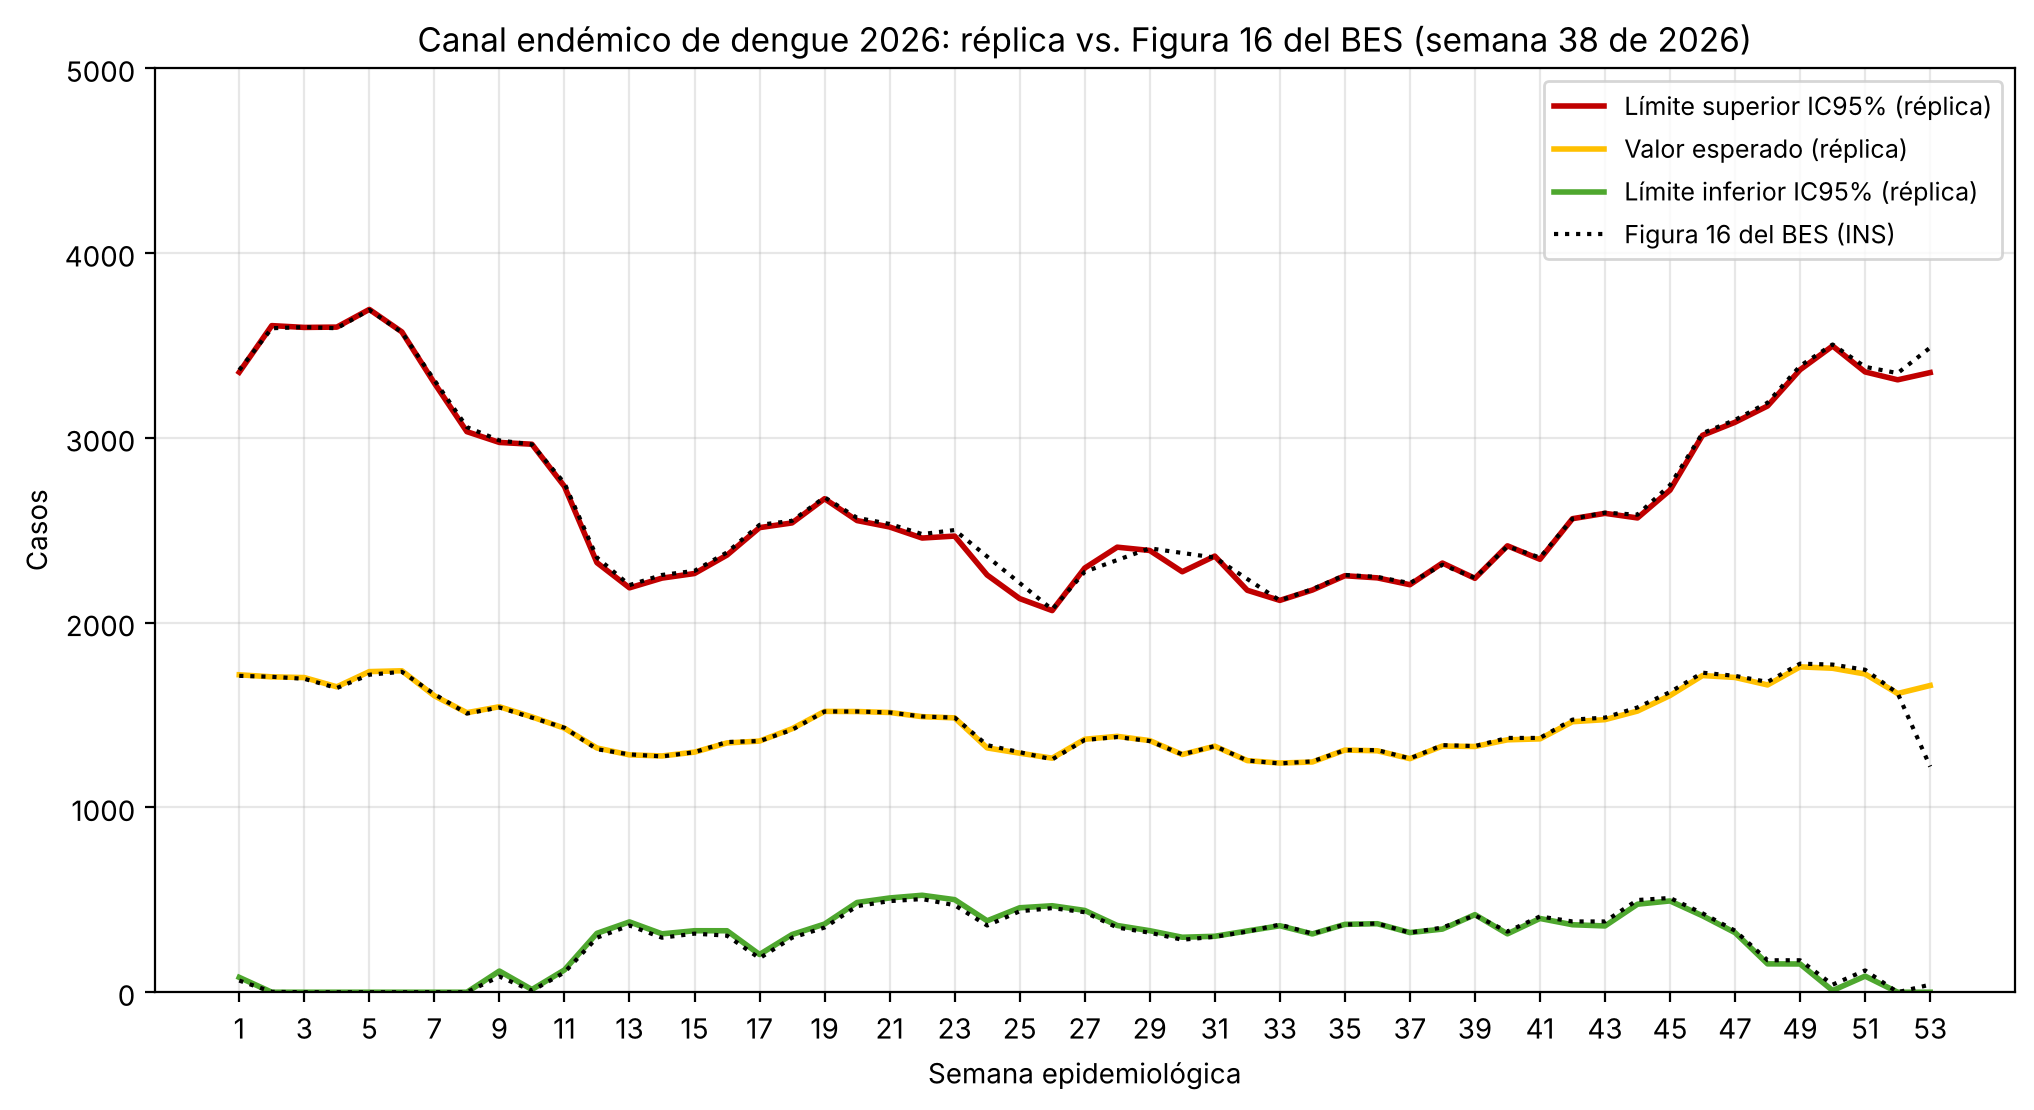

SEMANA                 1    2    3    4    5    6    7    8      9
Inferior (réplica)  80.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0  115.0
Inferior (INS)      63.0  2.0  0.0  0.0  0.0  0.0  0.0  0.0   85.0


In [24]:
fig, ax = plt.subplots(figsize=(12, 6))
semanas = canal_2026.index
ax.plot(semanas, canal_2026["Limite_superior"], color="#C00000", linewidth=2, label="Límite superior IC95% (réplica)")
ax.plot(semanas, canal_2026["Esperado"], color="#FFC000", linewidth=2, label="Valor esperado (réplica)")
ax.plot(semanas, canal_2026["Limite_inferior"], color="#4EA72E", linewidth=2, label="Límite inferior IC95% (réplica)")
ax.plot(semanas, canal_ins["Limite_superior"], color="black", linestyle=":", linewidth=1.5, label="Figura 16 del BES (INS)")
ax.plot(semanas, canal_ins["Esperado"], color="black", linestyle=":", linewidth=1.5)
ax.plot(semanas, canal_ins["Limite_inferior"], color="black", linestyle=":", linewidth=1.5)
ax.set_xticks(range(1, 54, 2))
ax.set_ylim(0, 5000)
ax.set_xlabel("Semana epidemiológica")
ax.set_ylabel("Casos")
ax.set_title("Canal endémico de dengue 2026: réplica vs. Figura 16 del BES (semana 38 de 2026)")
ax.legend(loc="upper right", fontsize=9)
ax.grid(True, alpha=0.3)
plt.show()

# Limite inferior en las primeras semanas: replica frente a la Figura 16
print(pd.DataFrame({"Inferior (réplica)": canal_2026["Limite_inferior"].round(0), "Inferior (INS)": canal_ins["Limite_inferior"]}).loc[1:9].T.to_string())

**Interpretación**

- **La réplica coincide con el canal del INS:** en las semanas 1 a 52, el valor esperado se diferencia en promedio **6.33 casos (0.41 %)**, el límite superior **19.41 casos (0.77 %)** y el límite inferior **13.19 casos**. Estas diferencias son del mismo tamaño que el error de lectura de la imagen (±25 casos), así que en la práctica las líneas son iguales: en la gráfica las líneas de la réplica tapan casi por completo a las del INS.
- **El límite inferior queda en cero o casi en cero** en las semanas 2 a 8, igual que en el boletín. Esto confirma que el INS calcula los límites como media geométrica ± t·S/√n y los recorta en 0.
- **La única semana que no coincide es la 53:** la réplica da 1 660 casos esperados y el INS 1 221. El boletín no explica cómo trata esta semana, que solo existe en 2020 y 2025, así que en la réplica se usó la semana 52 para los años que no la tienen.
- **Conclusión:** el método del canal endémico quedó **bien replicado**. Se puede usar con confianza para construir el canal de 2025 (periodo de prueba) y para leer el pronóstico de 2026 (sección 5.8).

#### 4.1.3 Canal endémico de 2025 (el que acompaña a los modelos en el periodo de prueba)

Para la prueba se necesita un canal que **no use información de 2025**. Se aplica la misma regla del INS: los 5 años anteriores sin el año epidémico 2024, es decir **2019, 2020, 2021, 2022 y 2023**.

**¿Cómo se pone el canal endémico al lado de un modelo de pronóstico?**

El canal endémico es una herramienta de **vigilancia**: su objetivo es clasificar cada semana en una zona (éxito, seguridad, alerta o brote), no pronosticar. Aun así, su línea central, el **valor esperado** (la media geométrica), es lo que el sistema de vigilancia considera *normal* para cada semana. En este proyecto se usa como **línea base institucional**, es decir, como el pronóstico de alguien que supone que ocurrirá lo normal:

$$\hat{y}^{\,canal}_{2025,s} = \bar{x}_{G,s} \qquad s = 1, \dots, 53$$

Esta es una decisión metodológica del proyecto, no del INS. El valor esperado se construye antes de que empiece 2025 y no se actualiza con los casos que van llegando; por eso su error es el mismo en todos los horizontes.

El canal se evalúa entonces de dos maneras:
- **Como herramienta de vigilancia** (su función real): en qué zona cayó cada semana de 2025.
- **Como línea base de pronóstico:** con las mismas métricas de error que los modelos (sección 5).

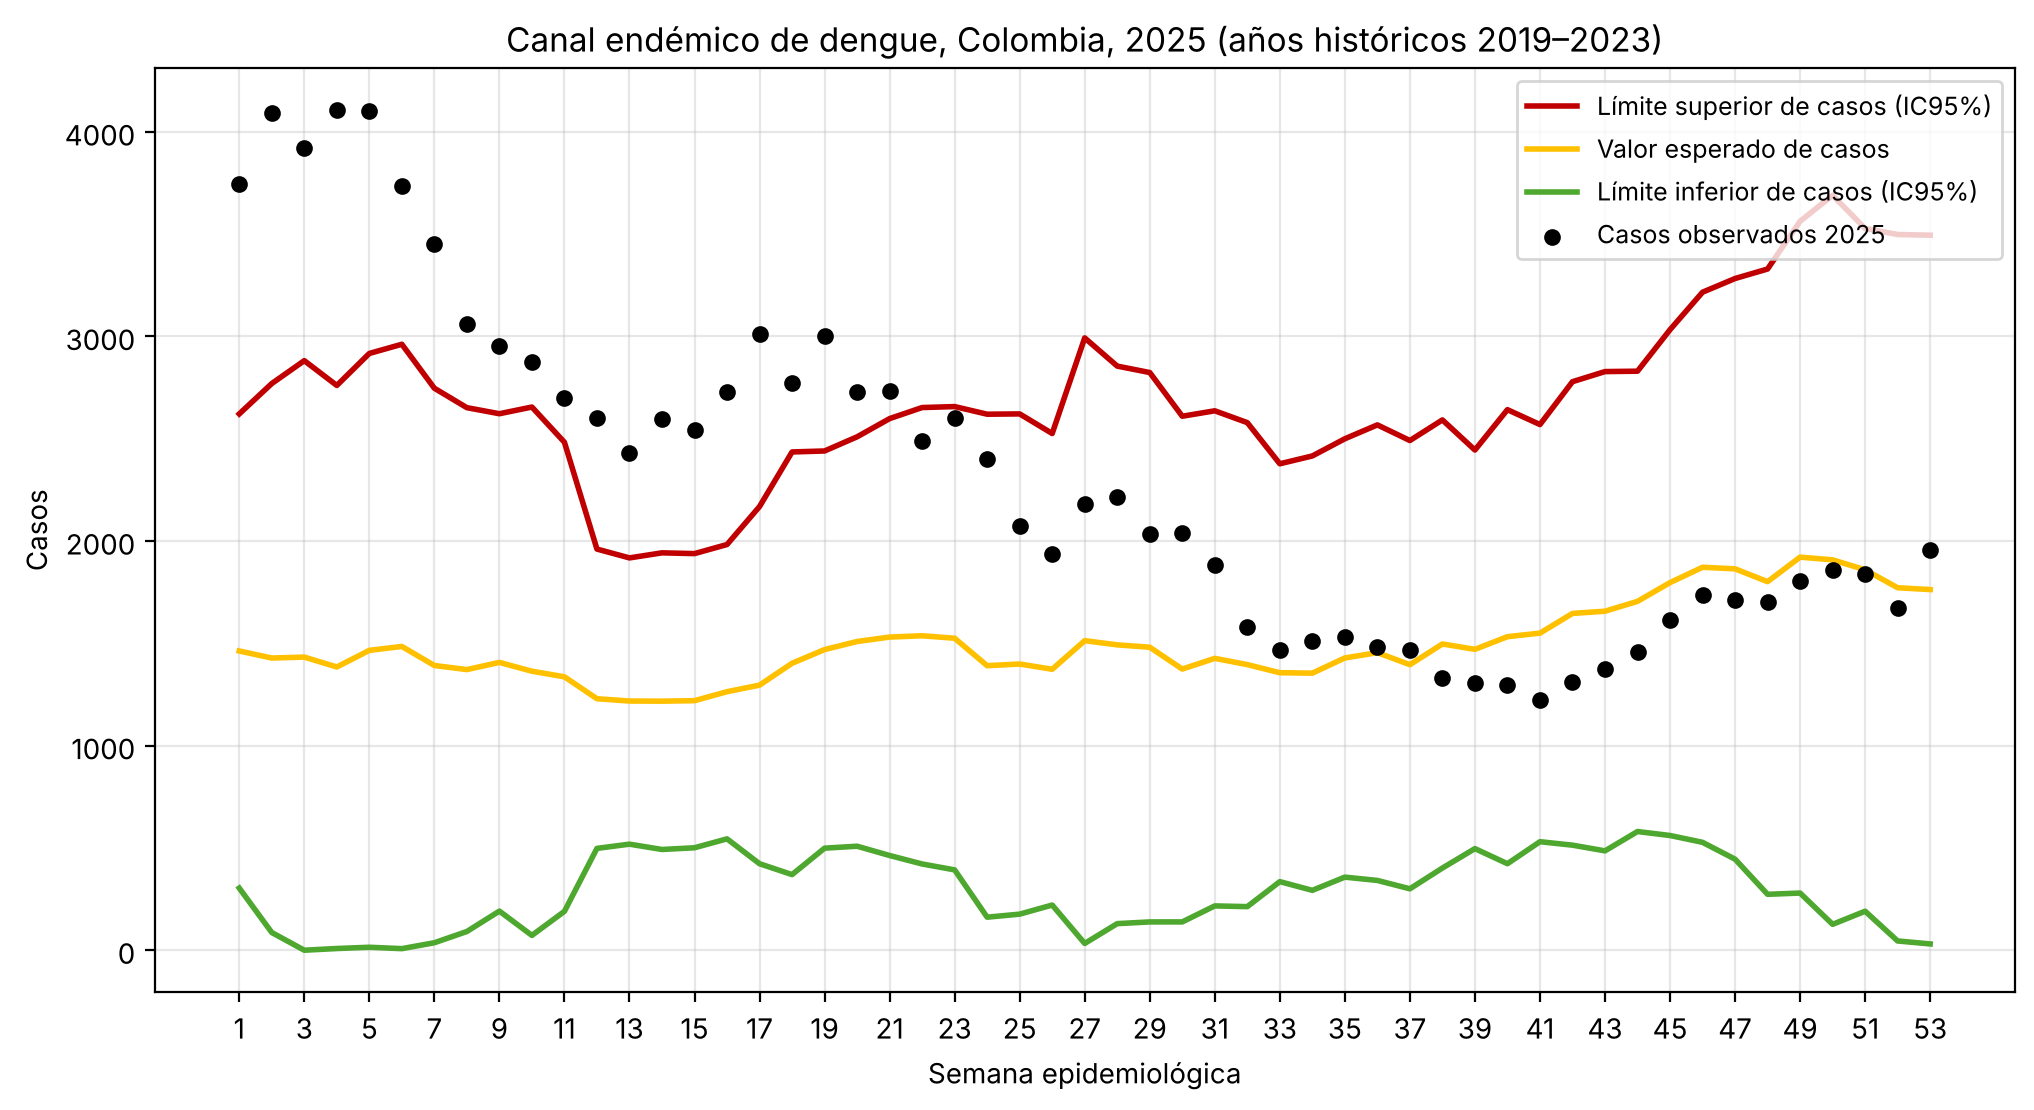

                                   Semanas     %
Zona                                            
Por debajo de lo esperado                0   0.0
Dentro de lo esperado                   15  28.3
Alerta                                  17  32.1
Por encima de lo esperado (brote)       21  39.6

Por debajo de lo esperado: semanas []
Dentro de lo esperado: semanas [38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52]
Alerta: semanas [22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 53]
Por encima de lo esperado (brote): semanas [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]

Valor esperado del canal 2025: mínimo 1217 y máximo 1921 casos por semana


,Limite_inferior,Esperado,Limite_superior,Observado_2025,Zona
SEMANA,,,,,
1,304.0,1463.0,2622.0,3746,Por encima de lo esperado (brote)
2,87.0,1428.0,2770.0,4094,Por encima de lo esperado (brote)
3,0.0,1433.0,2882.0,3922,Por encima de lo esperado (brote)
4,8.0,1385.0,2761.0,4106,Por encima de lo esperado (brote)
5,14.0,1466.0,2917.0,4103,Por encima de lo esperado (brote)
6,8.0,1485.0,2962.0,3737,Por encima de lo esperado (brote)
7,37.0,1392.0,2747.0,3451,Por encima de lo esperado (brote)
8,92.0,1372.0,2652.0,3060,Por encima de lo esperado (brote)
9,191.0,1407.0,2622.0,2955,Por encima de lo esperado (brote)


In [25]:
# Canal 2025: 5 años anteriores sin el año epidemico 2024
anios_canal_2025 = [2019, 2020, 2021, 2022, 2023]
canal_2025 = canal_endemico(datos, anios_canal_2025)

# Casos observados en 2025 y zona del canal en la que cae cada semana
obs_2025 = datos[datos["ANO"] == 2025].set_index("SEMANA")["casos"]
canal_2025["Observado_2025"] = obs_2025
canal_2025["Zona"] = [clasificar_zona(obs_2025[s], canal_2025.loc[s]) for s in canal_2025.index]

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(canal_2025.index, canal_2025["Limite_superior"], color="#C00000", linewidth=2, label="Límite superior de casos (IC95%)")
ax.plot(canal_2025.index, canal_2025["Esperado"], color="#FFC000", linewidth=2, label="Valor esperado de casos")
ax.plot(canal_2025.index, canal_2025["Limite_inferior"], color="#4EA72E", linewidth=2, label="Límite inferior de casos (IC95%)")
ax.scatter(canal_2025.index, canal_2025["Observado_2025"], color="black", s=25, zorder=3, label="Casos observados 2025")
ax.set_xticks(range(1, 54, 2))
ax.set_xlabel("Semana epidemiológica")
ax.set_ylabel("Casos")
ax.set_title("Canal endémico de dengue, Colombia, 2025 (años históricos 2019–2023)")
ax.legend(loc="upper right", fontsize=9)
ax.grid(True, alpha=0.3)
plt.show()

orden_zonas = ["Por debajo de lo esperado", "Dentro de lo esperado", "Alerta", "Por encima de lo esperado (brote)"]
tab_zonas = canal_2025["Zona"].value_counts().reindex(orden_zonas, fill_value=0).rename("Semanas").to_frame()
tab_zonas["%"] = (tab_zonas["Semanas"] / tab_zonas["Semanas"].sum() * 100).round(1)
print(tab_zonas)
print()
for zona in orden_zonas:
    print(f"{zona}: semanas {canal_2025.index[canal_2025['Zona'] == zona].tolist()}")
print(f"\nValor esperado del canal 2025: mínimo {canal_2025['Esperado'].min():.0f} y máximo {canal_2025['Esperado'].max():.0f} casos por semana")
canal_2025.round(0).head(10)

**Interpretación**

- **Valor esperado 2025:** la media geométrica de 2019–2023 va de **1 217 a 1 921 casos semanales**, según la semana.
- **Zonas en que cayó 2025:**
  - **Semanas 1 a 21 (39.6 % del año): por encima del límite superior, es decir, en brote.** Es la cola de la epidemia de 2024.
  - **Semanas 22 a 37 y semana 53 (32.1 %): en alerta.**
  - **Semanas 38 a 52 (28.3 %): dentro de lo esperado.**
  - **Ninguna semana** quedó por debajo del límite inferior.
- **Como herramienta de vigilancia, el canal hizo su trabajo:** mostró que la primera mitad de 2025 seguía siendo anormalmente alta y que hacia el final del año la situación volvió a la normalidad.
- **Lo que el canal no puede dar:** su valor esperado no sabe que el país venía de una epidemia, así que en el primer semestre queda muy por debajo de los casos reales. Eso no es una falla: **esa distancia es precisamente la señal de brote**. Pero quiere decir que, si alguien necesita saber cuántos casos habrá en las próximas semanas para planear, "lo normal" no le sirve mientras el año no sea normal. Esa es la parte que puede cubrir un modelo de pronóstico.

### 4.2 Modelos de referencia estadísticos (ingenuos)

Antes de decir que un modelo pronostica bien hay que compararlo con reglas muy simples que no estiman ningún parámetro. Si un modelo no les gana, su complejidad no se justifica. Se usan tres. Si $y_T$ es el último dato disponible al momento de pronosticar y $h$ el horizonte:

- **Ingenuo (último valor):** los casos seguirán en el último nivel observado.
$$\hat{y}_{T+h} = y_T$$
- **Ingenuo estacional ($m = 52$):** habrá los mismos casos que en la misma semana de hace un año.
$$\hat{y}_{T+h} = y_{T+h-52}$$
- **Ingenuo con deriva:** el último valor más el cambio promedio semanal de toda la historia disponible.
$$\hat{y}_{T+h} = y_T + h \cdot \frac{y_T - y_1}{T - 1}$$

En los pronósticos a 1 y 4 semanas, $y_T$ es el dato de 1 o 4 semanas antes de la semana que se pronostica, así que estos modelos también se actualizan con los casos que van llegando, igual que los modelos ARIMA. En el pronóstico del año completo, $y_T$ es la semana 52 de 2024.

**Diferencia con el canal endémico.** Las dos son referencias, pero de distinto tipo:

| | Modelos ingenuos | Canal endémico |
| :--- | :--- | :--- |
| Tipo de referencia | **Estadística**: la mínima vara que debe superar cualquier modelo de pronóstico | **Institucional**: la herramienta que usa el INS para vigilar |
| Información que usan | La serie reciente (último dato o el de hace 52 semanas) | Varios años anteriores, resumidos en una media geométrica por semana |
| ¿Se actualizan durante el año? | Sí, con cada dato nuevo | No, quedan fijas desde el inicio del año |
| Para qué sirven aquí | Saber si los modelos ARIMA aportan algo frente a reglas simples | Saber qué es "lo normal" y clasificar la situación |

In [26]:
# Modelos de referencia estadisticos (ingenuos). Ninguno estima parametros.

def pronostico_ingenuos(serie, semanas_objetivo, h):
    # Pronostico a h semanas: para cada semana objetivo solo se usan los datos observados hasta h semanas antes
    ingenuo, estacional, deriva = [], [], []
    for semana in semanas_objetivo:
        pos = serie.index.get_loc(semana)
        historia = serie.iloc[:pos - h + 1]                   # datos disponibles al momento de pronosticar
        ultimo = historia.iloc[-1]
        pendiente = (ultimo - historia.iloc[0]) / (len(historia) - 1)
        ingenuo.append(ultimo)                                 # ingenuo: ultimo valor observado
        estacional.append(serie.iloc[pos - 52])                # ingenuo estacional: misma semana, 52 semanas atras
        deriva.append(ultimo + h * pendiente)                  # ingenuo con deriva: ultimo valor + h * cambio promedio historico
    return np.array(ingenuo), np.array(estacional), np.array(deriva)

def pronostico_ingenuos_anio(historia, pasos):
    # Pronostico de todo el año de una sola vez, con la informacion disponible al final de la historia
    ultimo = historia.iloc[-1]
    pendiente = (ultimo - historia.iloc[0]) / (len(historia) - 1)
    ingenuo = np.repeat(ultimo, pasos)
    estacional = np.array([historia.iloc[len(historia) - 52 + (k % 52)] for k in range(pasos)])
    deriva = ultimo + np.arange(1, pasos + 1) * pendiente
    return ingenuo, estacional, deriva

print(f"Último valor del entrenamiento (2024-SE52): {serie_train.iloc[-1]:.0f} casos")
print(f"Cambio promedio semanal del entrenamiento (deriva): {(serie_train.iloc[-1] - serie_train.iloc[0]) / (len(serie_train) - 1):.2f} casos por semana")

Último valor del entrenamiento (2024-SE52): 3747 casos
Cambio promedio semanal del entrenamiento (deriva): 6.63 casos por semana


**Interpretación:** el entrenamiento termina con 3 747 casos en la semana 52 de 2024. Para el pronóstico del año completo, el modelo ingenuo repetirá ese valor en las 53 semanas de 2025 y el ingenuo con deriva le sumará 6.63 casos por cada semana, que es el cambio promedio de 2019 a 2024.

### 4.3 Modelos de la familia ARIMA en la ventana de entrenamiento (2019-SE01 – 2024-SE52)

Todo el ajuste se hace **solo con el entrenamiento (2019–2024)**. 2025 se reserva para evaluar los pronósticos; así ningún modelo "ve" los datos con los que se le califica, igual que el canal de 2025.

#### 4.3.1 Modelo ARIMA(p,d,q)

Según la ACF/PACF de la serie diferenciada se proponen:

- **ARIMA(4,1,0):** AR(4) por el corte de la PACF después del rezago 4.
- **ARIMA(0,1,4):** MA(4) por los picos de la ACF hasta el rezago 4.
- **AutoARIMA:** seleccionado automáticamente con `auto_arima`.

In [27]:
# Estimar modelos ARIMA (sin componente estacional)
arima410 = ARIMA(serie_train, order=(4, 1, 0)).fit()
arima014 = ARIMA(serie_train, order=(0, 1, 4)).fit()
# Búsqueda automática
m_autoarima = auto_arima(serie_train, seasonal=False, trace=False)
auto_arima_fit = ARIMA(serie_train, order=m_autoarima.order).fit()

# guardar modelos
list_modelos_arima = {"ARIMA(4,1,0)" : arima410, "ARIMA(0,1,4)" : arima014, "AutoARIMA": auto_arima_fit}

In [28]:
def comparar_modelos_arima(modelos: dict) -> pd.DataFrame:
    df_modelos = (
        pd.DataFrame({
            "Modelo"  : list(modelos),
            "Orden"   : [f"{m.model.order}{m.model.seasonal_order}" for m in modelos.values()],
            "AIC"     : [m.aic       for m in modelos.values()],
            "AICc"    : [m.aicc      for m in modelos.values()],
            "BIC"     : [m.bic       for m in modelos.values()],
            "Log-Lik" : [m.llf       for m in modelos.values()],
            "MSE"     : [m.mse       for m in modelos.values()],
            "RMSE"    : [m.mse**0.5  for m in modelos.values()],
            "MAE"     : [m.mae       for m in modelos.values()],
            "Params"  : [m.df_model  for m in modelos.values()],
            "Obs"     : [m.nobs      for m in modelos.values()],
        })
        .sort_values("AICc")
        .assign(Ranking=lambda df: range(1, len(df) + 1))
        .set_index("Ranking")
    )

    mejor      = df_modelos.iloc[0]["Modelo"]
    mejor_aicc = df_modelos.iloc[0]["AICc"]

    print("=" * 100)
    print("COMPARACIÓN DE MODELOS ARIMA")
    print("=" * 100)
    print(df_modelos.to_string())
    print("-" * 100)
    print(f"Mejor modelo (menor AICc): {mejor}  →  AICc: {mejor_aicc}")
    print("=" * 100)

comparar_modelos_arima(list_modelos_arima)

COMPARACIÓN DE MODELOS ARIMA
               Modelo                  Orden          AIC         AICc          BIC      Log-Lik           MSE        RMSE         MAE  Params  Obs
Ranking                                                                                                                                            
1           AutoARIMA  (2, 1, 2)(0, 0, 0, 0)  4284.736542  4284.932620  4303.451558 -2137.368271  60969.342187  246.919708  151.922341       5  313
2        ARIMA(4,1,0)  (4, 1, 0)(0, 0, 0, 0)  4291.439671  4291.635749  4310.154687 -2140.719835  62123.236351  249.245334  150.948107       5  313
3        ARIMA(0,1,4)  (0, 1, 4)(0, 0, 0, 0)  4297.540342  4297.736420  4316.255358 -2143.770171  63194.226722  251.384619  151.496111       5  313
----------------------------------------------------------------------------------------------------
Mejor modelo (menor AICc): AutoARIMA  →  AICc: 4284.932620248531


**Interpretación**

- **El mejor modelo por AICc es el AutoARIMA, que eligió ARIMA(2,1,2)** (AICc ≈ 4284.9). Supera al ARIMA(4,1,0), con AICc ≈ 4291.6, por casi 7 puntos, y al ARIMA(0,1,4), con AICc ≈ 4297.7.
- **Los tres modelos tienen el mismo número de parámetros,** así que la diferencia está en cómo combinan la parte AR y la MA. Con dos términos AR y dos MA el ARIMA(2,1,2) resume mejor la dependencia que los modelos puros AR(4) o MA(4).

In [29]:
# Reporte del mejor modelo (menor AICc)
nombre_mejor_arima = min(list_modelos_arima, key=lambda k: list_modelos_arima[k].aicc)
mejor_arima = list_modelos_arima[nombre_mejor_arima]
print(f"Mejor modelo ARIMA: {nombre_mejor_arima}")
print(mejor_arima.summary())

Mejor modelo ARIMA: AutoARIMA
                               SARIMAX Results                                
Dep. Variable:                  casos   No. Observations:                  313
Model:                 ARIMA(2, 1, 2)   Log Likelihood               -2137.368
Date:                Thu, 19 Nov 2026   AIC                           4284.737
Time:                        19:02:27   BIC                           4303.452
Sample:                    12-30-2018   HQIC                          4292.216
                         - 12-22-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.3302      0.141      9.401      0.000       1.053       1.607
ar.L2         -0.4366      0.133     -3.275      0.001      -0.698      -0.175
ma.L1         -1.4479 

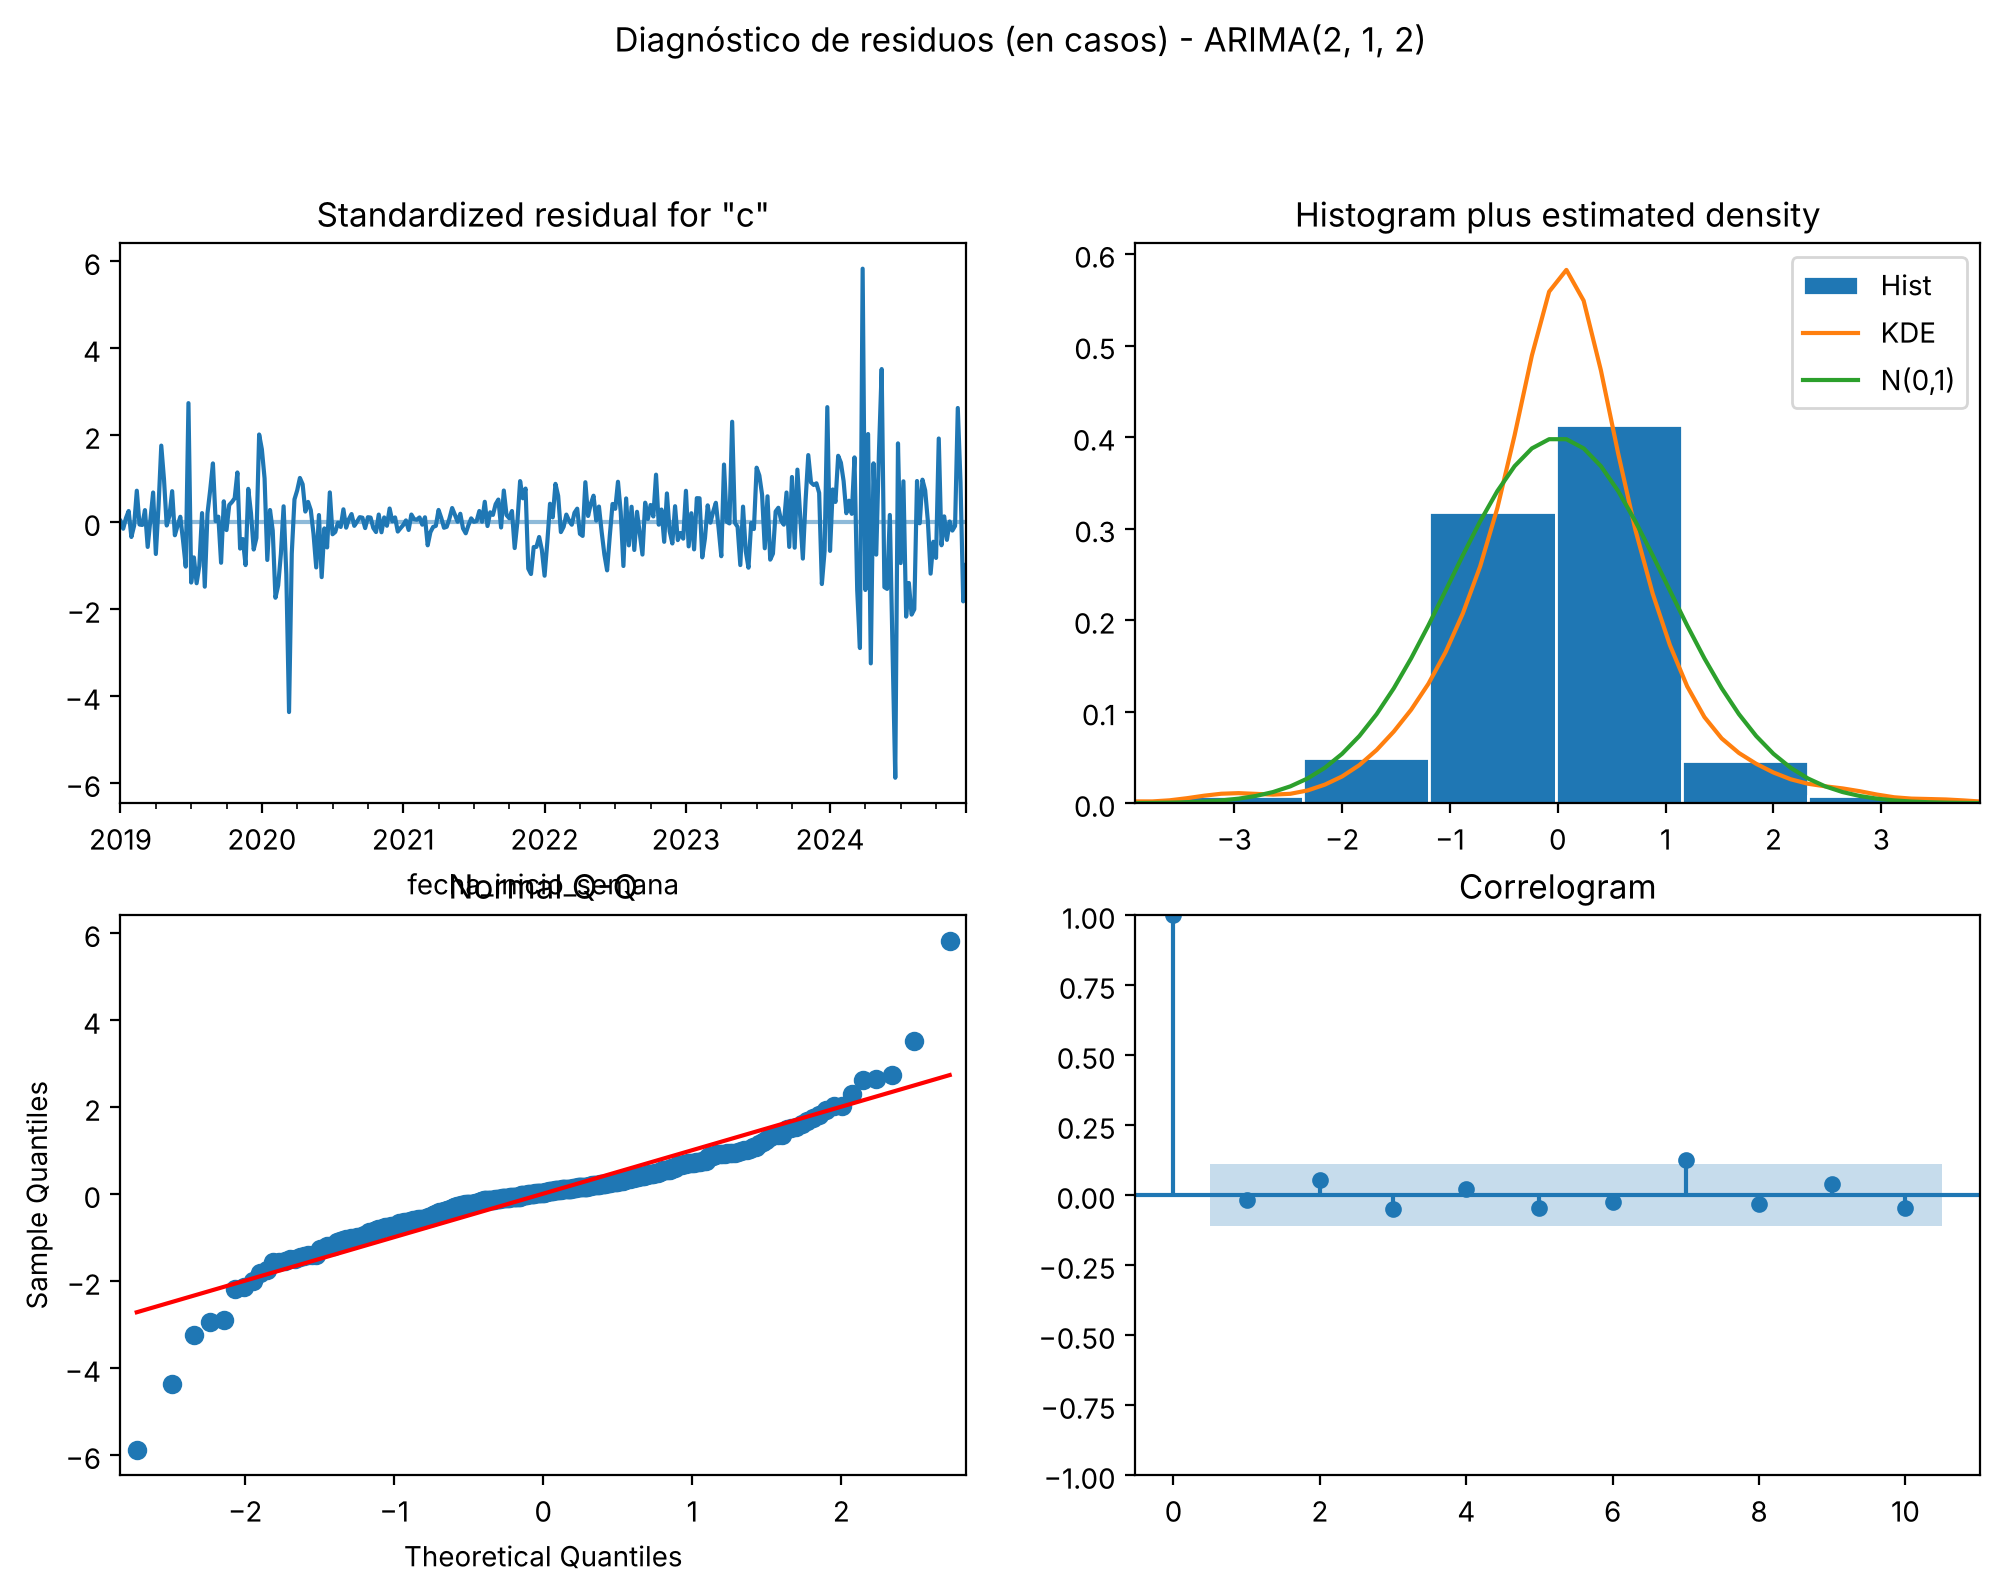

,lb_stat,lb_pvalue
13,62.356896,1.983015e-08
26,85.855964,2.550101e-08
52,124.521337,6.934908e-08


In [30]:
# Verificar ruido blanco
fig = mejor_arima.plot_diagnostics(figsize=(12,8))
fig.suptitle(f"Diagnóstico de residuos (en casos) - ARIMA{mejor_arima.model.order}", y=1.02)
plt.show()

# Ljung-Box (rezagos de 13, 26 y 52 semanas: un trimestre, un semestre y un año)
acorr_ljungbox(mejor_arima.resid[1:], lags=[13, 26, 52], return_df=True)

**Interpretación**

- **Coeficientes:** los cuatro (AR(1) = 1.33, AR(2) = -0.44, MA(1) = -1.45 y MA(2) = 0.65) son significativos (p < 0.01).
- **Ljung-Box rechaza H0** en los rezagos 13, 26 y 52 (p < 0.001), así que **los residuos no son ruido blanco**. En el correlograma casi todos los primeros 10 rezagos están dentro de la banda, de modo que la autocorrelación que queda está sobre todo en rezagos más largos, como los picos de 12 y 13 semanas vistos antes.
- **Normalidad:** los residuos no son normales (Jarque-Bera ≈ 954, curtosis ≈ 11.6).
- **Varianza:** los residuos son **heterocedásticos** (H = 2.89, p ≈ 0). Esto se ve en la gráfica de residuos, que crecen mucho durante la epidemia de 2024: cuando hay más casos, los errores son más grandes.
- **Conclusión:** el modelo capta la dinámica de corto plazo, pero no toda la estructura de la serie. Esta limitación se repite en todos los modelos de la familia ARIMA de este cuaderno. En la sección 5.1 se reúne el diagnóstico completo, en la 5.2 se modela la varianza con un GARCH y en la 5.5 se prueba si una transformación logarítmica la corrige.

#### 4.3.2 Modelo SARIMA(p,d,q)(P,D,Q)₅₂

Se agrega un componente estacional con **s = 52 semanas** (ciclo anual). Se proponen:
- **SARIMA(4,1,0)(1,0,0)₅₂:** la parte regular del ARIMA(4,1,0) más un AR estacional: la semana actual depende de la misma semana del año anterior.
- **SARIMA(4,1,0)(0,0,1)₅₂:** la parte regular del ARIMA(4,1,0) más un MA estacional: el error de la misma semana del año anterior influye en la semana actual.
- **AutoSARIMA:** seleccionado automáticamente con `auto_arima` y `m = 52`. Esta búsqueda tarda unos minutos.

> No se usa diferencia estacional (D = 0). Las pruebas de estacionariedad mostraron que con una diferencia regular (d = 1) la serie ya es estacionaria. Además, el AICc **solo se puede comparar entre modelos con el mismo orden de diferenciación**: un modelo con D = 1 pierde las primeras 52 semanas al calcular la verosimilitud, y su AICc saldría artificialmente más bajo.

In [31]:
# Estimar modelos SARIMA (s = 52, ciclo anual)
sarima410100 = ARIMA(serie_train, order=(4, 1, 0), seasonal_order=(1, 0, 0, 52)).fit()
sarima410001 = ARIMA(serie_train, order=(4, 1, 0), seasonal_order=(0, 0, 1, 52)).fit()
# Búsqueda automática (puede tardar unos minutos)
m_autosarima = auto_arima(serie_train, seasonal=True, m=52, trace=False)
auto_sarima = ARIMA(serie_train, order=m_autosarima.order, seasonal_order=m_autosarima.seasonal_order).fit()

# guardar modelos
list_modelos_sarima = {"SARIMA(4,1,0)(1,0,0)52" : sarima410100, "SARIMA(4,1,0)(0,0,1)52" : sarima410001, "AutoSARIMA": auto_sarima}

comparar_modelos_arima(list_modelos_sarima)

COMPARACIÓN DE MODELOS ARIMA
                         Modelo                   Orden          AIC         AICc          BIC      Log-Lik           MSE        RMSE         MAE  Params  Obs
Ranking                                                                                                                                                       
1                    AutoSARIMA  (2, 1, 2)(0, 0, 1, 52)  4279.066683  4279.342093  4301.524702 -2133.533342  59538.303018  244.004719  150.292037       6  313
2        SARIMA(4,1,0)(0,0,1)52  (4, 1, 0)(0, 0, 1, 52)  4288.083060  4288.358470  4310.541079 -2138.041530  61089.342380  247.162583  149.863680       6  313
3        SARIMA(4,1,0)(1,0,0)52  (4, 1, 0)(1, 0, 0, 52)  4288.677970  4288.953380  4311.135989 -2138.338985  61221.906618  247.430610  149.964273       6  313
----------------------------------------------------------------------------------------------------
Mejor modelo (menor AICc): AutoSARIMA  →  AICc: 4279.342093104926


**Interpretación**

- **El mejor modelo es el AutoSARIMA, SARIMA(2,1,2)(0,0,1)₅₂** (AICc ≈ 4279.3). Su parte regular es la misma del mejor ARIMA y agrega un MA estacional de 52 semanas.
- **Supera a los dos modelos propuestos** (AICc ≈ 4288.4 y 4289.0) y también al mejor ARIMA sin estacionalidad (≈ 4284.9). Se pueden comparar porque todos tienen d = 1, D = 0 y las mismas 313 semanas.
- **La mejora frente al ARIMA es de unos 5.6 puntos,** así que la componente anual aporta algo, aunque poco. Es coherente con lo visto en la STL y la ACF: una estacionalidad anual débil.

In [32]:
# Reporte del mejor modelo (menor AICc)
nombre_mejor_sarima = min(list_modelos_sarima, key=lambda k: list_modelos_sarima[k].aicc)
mejor_sarima = list_modelos_sarima[nombre_mejor_sarima]
print(f"Mejor modelo SARIMA: {nombre_mejor_sarima}")
print(mejor_sarima.summary())

Mejor modelo SARIMA: AutoSARIMA
                                     SARIMAX Results                                      
Dep. Variable:                              casos   No. Observations:                  313
Model:             ARIMA(2, 1, 2)x(0, 0, [1], 52)   Log Likelihood               -2133.533
Date:                            Thu, 19 Nov 2026   AIC                           4279.067
Time:                                    19:05:20   BIC                           4301.525
Sample:                                12-30-2018   HQIC                          4288.042
                                     - 12-22-2024                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.3156      0.144      9.114      0.000       1.033       1.598
ar.

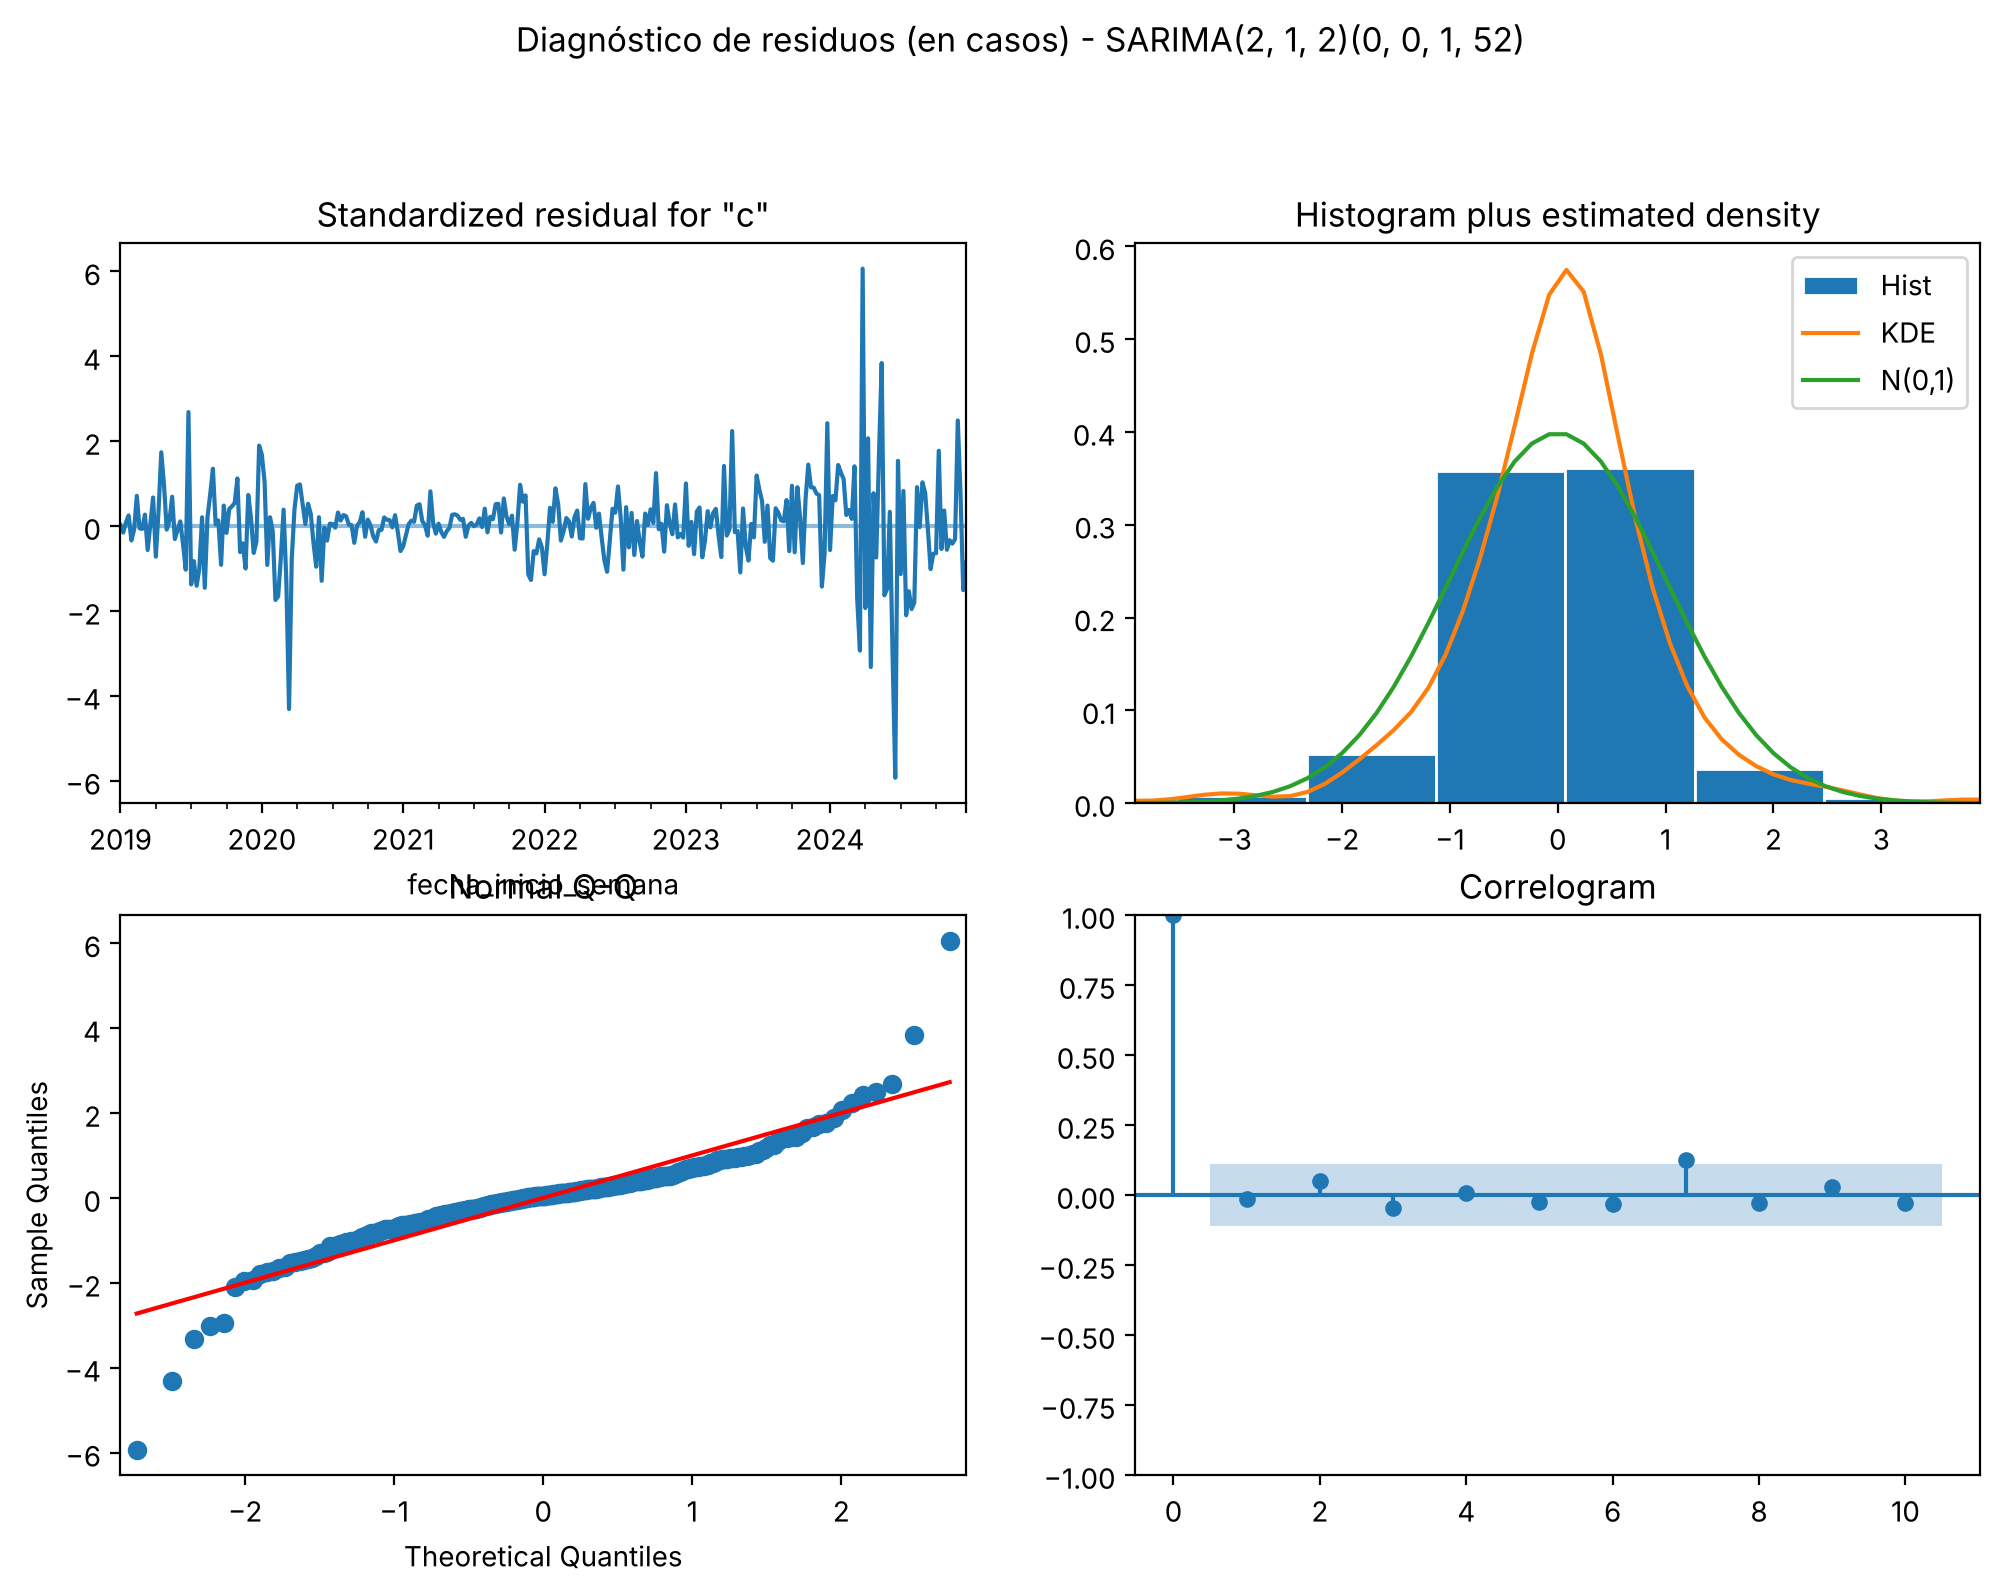

,lb_stat,lb_pvalue
13,58.455765,9.904867e-08
26,77.657825,4.790326e-07
52,108.327955,7.701420e-06


In [33]:
# Verificar ruido blanco
fig = mejor_sarima.plot_diagnostics(figsize=(12,8))
fig.suptitle(f"Diagnóstico de residuos (en casos) - SARIMA{mejor_sarima.model.order}{mejor_sarima.model.seasonal_order}", y=1.02)
plt.show()

# Ljung-Box
acorr_ljungbox(mejor_sarima.resid[1:], lags=[13, 26, 52], return_df=True)

**Interpretación**

- **MA estacional:** su coeficiente (0.24) es significativo (p = 0.013). Indica que el error de la misma semana del año anterior influye un poco en la semana actual.
- **Ljung-Box sigue rechazando H0** en todos los rezagos (p < 0.001), así que los residuos todavía no son ruido blanco.
- **Varianza y normalidad:** los residuos siguen siendo heterocedásticos (H = 2.92) y no normales.
- **Conclusión:** agregar la estacionalidad de 52 semanas no resolvió la autocorrelación que queda.

#### 4.3.3 Modelo SARIMAX con términos de Fourier (K = 1)

$$
Casos_t = \beta_1 \sin\left(\tfrac{2\pi t}{52.18}\right) + \beta_2 \cos\left(\tfrac{2\pi t}{52.18}\right) + \eta_t, \quad \eta_t \sim ARIMA(p,1,q)
$$

La estacionalidad anual la explican los términos de Fourier, así que el error $\eta_t$ se modela con un ARIMA sin parte estacional. Se usan los mismos órdenes propuestos para el ARIMA y la búsqueda automática.

In [34]:
# Variables exogenas del SARIMAX: un armonico de Fourier (K = 1)
vars_exog = ["sin1", "cos1"]
exog_train = fourier.loc[train.index, vars_exog]

# Estimar modelos SARIMAX
sarimax410 = ARIMA(serie_train, exog=exog_train, order=(4, 1, 0)).fit()
sarimax014 = ARIMA(serie_train, exog=exog_train, order=(0, 1, 4)).fit()
# Búsqueda automática
m_autoarimax = auto_arima(serie_train, X=exog_train, seasonal=False, trace=False)
auto_sarimax = ARIMA(serie_train, exog=exog_train, order=m_autoarimax.order).fit()

# guardar modelos
list_modelos_sarimax = {"SARIMAX(4,1,0)+Fourier(K=1)" : sarimax410, "SARIMAX(0,1,4)+Fourier(K=1)" : sarimax014, "AutoSARIMAX+Fourier(K=1)": auto_sarimax}

comparar_modelos_arima(list_modelos_sarimax)

COMPARACIÓN DE MODELOS ARIMA
                              Modelo                  Orden          AIC         AICc          BIC      Log-Lik           MSE        RMSE         MAE  Params  Obs
Ranking                                                                                                                                                           
1           AutoSARIMAX+Fourier(K=1)  (2, 1, 2)(0, 0, 0, 0)  4286.844496  4287.212917  4313.045518 -2136.422248  62003.362946  249.004745  153.357376       7  313
2        SARIMAX(4,1,0)+Fourier(K=1)  (4, 1, 0)(0, 0, 0, 0)  4293.215202  4293.583623  4319.416225 -2139.607601  63092.522801  251.182250  152.416532       7  313
3        SARIMAX(0,1,4)+Fourier(K=1)  (0, 1, 4)(0, 0, 0, 0)  4298.233170  4298.601591  4324.434192 -2142.116585  63966.002116  252.915010  153.503125       7  313
----------------------------------------------------------------------------------------------------
Mejor modelo (menor AICc): AutoSARIMAX+Fourier(K=1)  → 

**Interpretación**

- **El mejor SARIMAX es el AutoSARIMAX,** que eligió otra vez el orden (2,1,2) más los términos de Fourier sin₁ y cos₁ (AICc ≈ 4287.2).
- **Su AICc es mayor que el del ARIMA sin variables exógenas** (≈ 4284.9). Es decir, **agregar un armónico de Fourier no mejora el ajuste**: los dos parámetros extra no se compensan con una mejor verosimilitud.

In [35]:
# Reporte del mejor modelo (menor AICc)
nombre_mejor_sarimax = min(list_modelos_sarimax, key=lambda k: list_modelos_sarimax[k].aicc)
mejor_sarimax = list_modelos_sarimax[nombre_mejor_sarimax]
print(f"Mejor modelo SARIMAX: {nombre_mejor_sarimax}")
print(mejor_sarimax.summary())

Mejor modelo SARIMAX: AutoSARIMAX+Fourier(K=1)
                               SARIMAX Results                                
Dep. Variable:                  casos   No. Observations:                  313
Model:                 ARIMA(2, 1, 2)   Log Likelihood               -2136.422
Date:                Thu, 19 Nov 2026   AIC                           4286.844
Time:                        19:05:25   BIC                           4313.046
Sample:                    12-30-2018   HQIC                          4297.316
                         - 12-22-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sin1         303.8186    265.249      1.145      0.252    -216.059     823.697
cos1        -158.5139    303.912     -0.522      0.602    -754.170     437.142
ar.L1

**Interpretación de coeficientes:**
- **sin₁ (303.8, p = 0.25) y cos₁ (-158.5, p = 0.60):** no son significativos. Una vez que el ARIMA modela la dependencia semana a semana, una onda anual fija no explica los casos.
- **AR(1) = 1.32, AR(2) = -0.43, MA(1) = -1.45 y MA(2) = 0.65:** todos significativos y casi iguales a los del ARIMA sin variables exógenas. Esto confirma que la dinámica la llevan estos términos y no la estacionalidad.

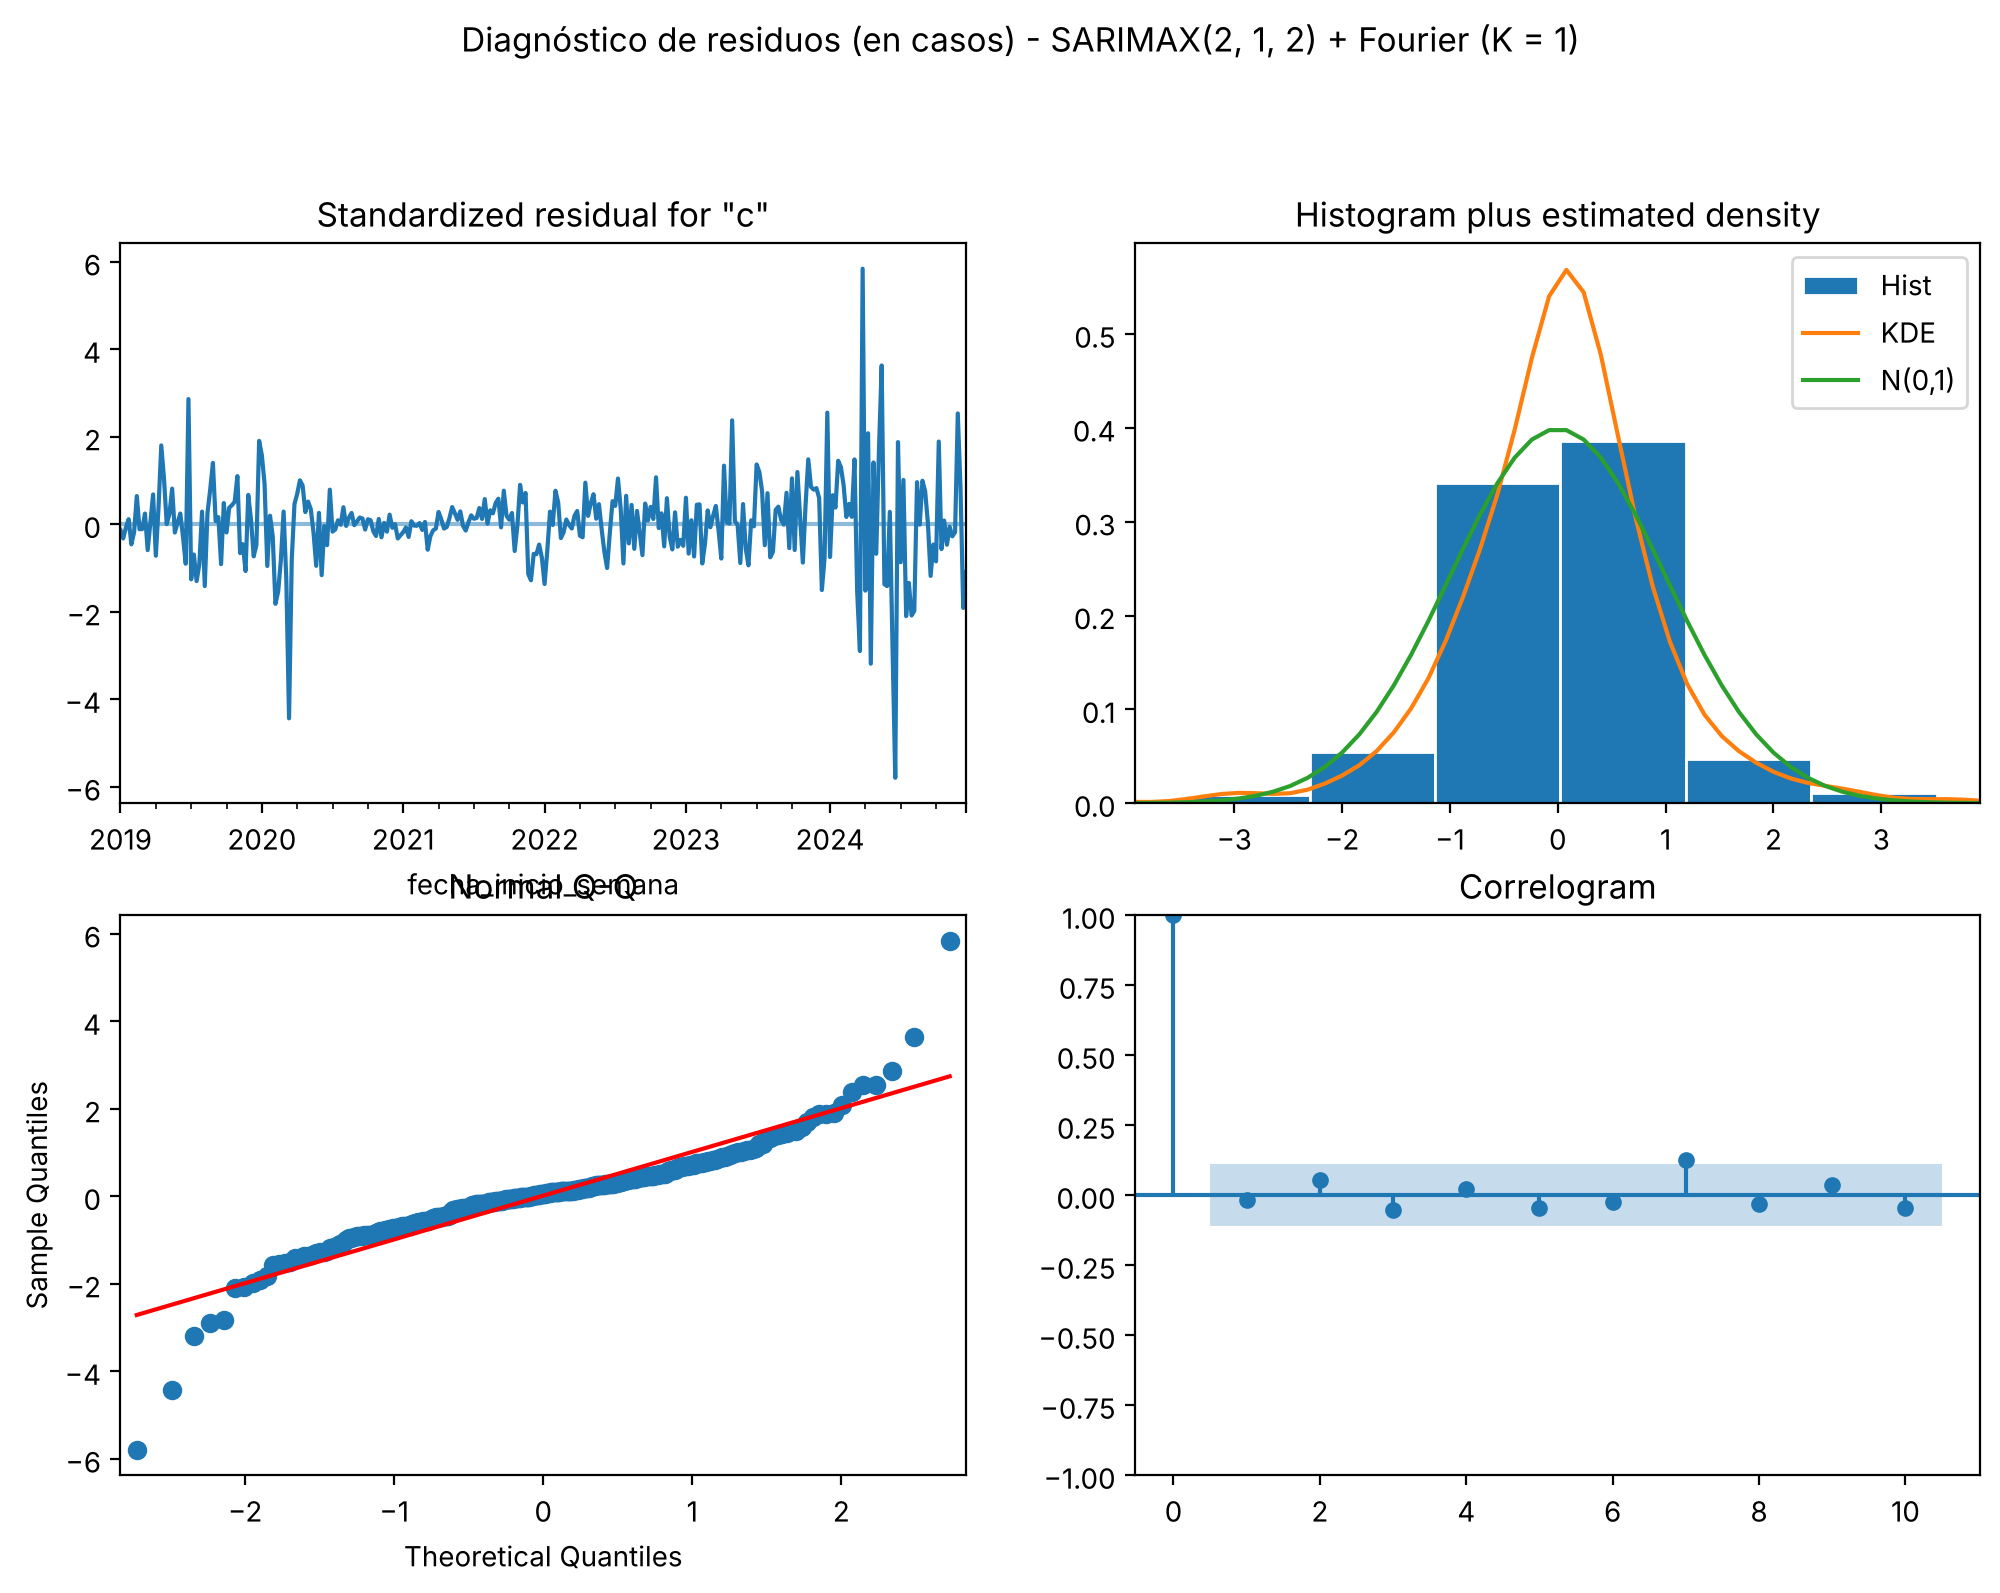

,lb_stat,lb_pvalue
13,62.259946,2.064405e-08
26,85.406518,3.003433e-08
52,124.342070,7.323417e-08


In [36]:
# Verificar ruido blanco
fig = mejor_sarimax.plot_diagnostics(figsize=(12,8))
fig.suptitle(f"Diagnóstico de residuos (en casos) - SARIMAX{mejor_sarimax.model.order} + Fourier (K = 1)", y=1.02)
plt.show()

# Ljung-Box
acorr_ljungbox(mejor_sarimax.resid[1:], lags=[13, 26, 52], return_df=True)

**Interpretación:** la prueba de Ljung-Box rechaza H0 en los tres rezagos (p < 0.001). Los residuos **no son ruido blanco** y su comportamiento es prácticamente el mismo del ARIMA(2,1,2), algo esperable porque los términos de Fourier no fueron significativos.

#### 4.3.4 SARIMAX con más armónicos de Fourier (K = 1 a 5)

En el taller se agregaban rezagos de la temperatura. Aquí lo equivalente es **agregar armónicos**: con $K = 2$ se suman $\sin(2\cdot 2\pi t/m)$ y $\cos(2\cdot 2\pi t/m)$, con $K = 3$ otro par, y así sucesivamente.

- Modelo con K = 1: $\sin_1, \cos_1$
- Modelo con K = 2: agrega $\sin_2, \cos_2$
- …
- Modelo con K = 5: agrega $\sin_5, \cos_5$

> Como el objetivo es comparar modelos, es **importante mantener el mismo set de entrenamiento** en todos. Además, todos usan el mismo orden ARIMA del mejor SARIMAX para que la única diferencia sea el número de armónicos.

In [37]:
# Todos los modelos usan el mismo orden ARIMA del mejor SARIMAX (solo cambia el numero de armonicos K)
orden = mejor_sarimax.model.order

list_modelo_sarimax_K = {}
vars_K = []
for K in range(1, 6):
    vars_K = vars_K + [f"sin{K}", f"cos{K}"]
    fit_sarimax_K = ARIMA(serie_train, exog=fourier.loc[train.index, vars_K], order=orden).fit()
    # guardar modelo
    list_modelo_sarimax_K[f"sarimax_K{K}"] = fit_sarimax_K

comparar_modelos_arima(list_modelo_sarimax_K)

COMPARACIÓN DE MODELOS ARIMA
             Modelo                  Orden          AIC         AICc          BIC      Log-Lik           MSE        RMSE         MAE  Params  Obs
Ranking                                                                                                                                          
1        sarimax_K4  (2, 1, 2)(0, 0, 0, 0)  4284.342681  4285.564158  4333.001723 -2129.171341  59004.181665  242.907764  152.444055      13  313
2        sarimax_K5  (2, 1, 2)(0, 0, 0, 0)  4283.983987  4285.605609  4340.129035 -2126.991993  58440.109564  241.743893  151.769249      15  313
3        sarimax_K2  (2, 1, 2)(0, 0, 0, 0)  4285.771888  4286.367915  4319.458917 -2133.885944  59534.244756  243.996403  151.689045       9  313
4        sarimax_K3  (2, 1, 2)(0, 0, 0, 0)  4286.035137  4286.915137  4327.208172 -2132.017568  59365.777061  243.650933  152.488667      11  313
5        sarimax_K1  (2, 1, 2)(0, 0, 0, 0)  4286.844496  4287.212917  4313.045518 -2136.422248 

**Interpretación**

- **El menor AICc lo tiene el modelo con K = 4 armónicos** (AICc ≈ 4285.6). Sin embargo, frente a K = 5 (≈ 4285.6) y K = 2 (≈ 4286.4) la diferencia es menor a 2 puntos, así que esos modelos son **prácticamente equivalentes**. Si se quisiera el más simple de ese grupo, K = 2 sería una buena opción.
- **Ninguno mejora al ARIMA(2,1,2) sin variables exógenas** (AICc ≈ 4284.9) **ni al SARIMA** (≈ 4279.3). Agregar armónicos, igual que agregar rezagos de la temperatura en el taller, mejora el ajuste solo marginalmente.
- El código del taller elige el de menor AICc, así que a partir de aquí se usa **K = 4**.

In [38]:
# Reporte del mejor modelo con K armonicos (menor AICc)
mejor_K = min(list_modelo_sarimax_K, key=lambda k: list_modelo_sarimax_K[k].aicc)
mejor_sarimax_K = list_modelo_sarimax_K[mejor_K]
vars_mejor_K = list(mejor_sarimax_K.model.exog_names)
print(f"Mejor modelo con armónicos: {mejor_K}")
print(mejor_sarimax_K.summary())

Mejor modelo con armónicos: sarimax_K4
                               SARIMAX Results                                
Dep. Variable:                  casos   No. Observations:                  313
Model:                 ARIMA(2, 1, 2)   Log Likelihood               -2129.171
Date:                Thu, 19 Nov 2026   AIC                           4284.343
Time:                        19:05:26   BIC                           4333.002
Sample:                    12-30-2018   HQIC                          4303.790
                         - 12-22-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sin1         302.8249    286.885      1.056      0.291    -259.459     865.109
cos1        -158.4692    352.314     -0.450      0.653    -848.991     532.053
sin2         

**Interpretación:** ninguno de los 8 coeficientes de Fourier es significativo al 5 %; el más cercano es cos₂ (p = 0.062). Los términos AR y MA siguen siendo significativos y con valores similares a los anteriores. Con K = 4 la curva estacional es más flexible, porque puede tener hasta cuatro subidas y bajadas por año, pero los datos no muestran un patrón anual que se repita lo suficiente como para que esos términos sean significativos.

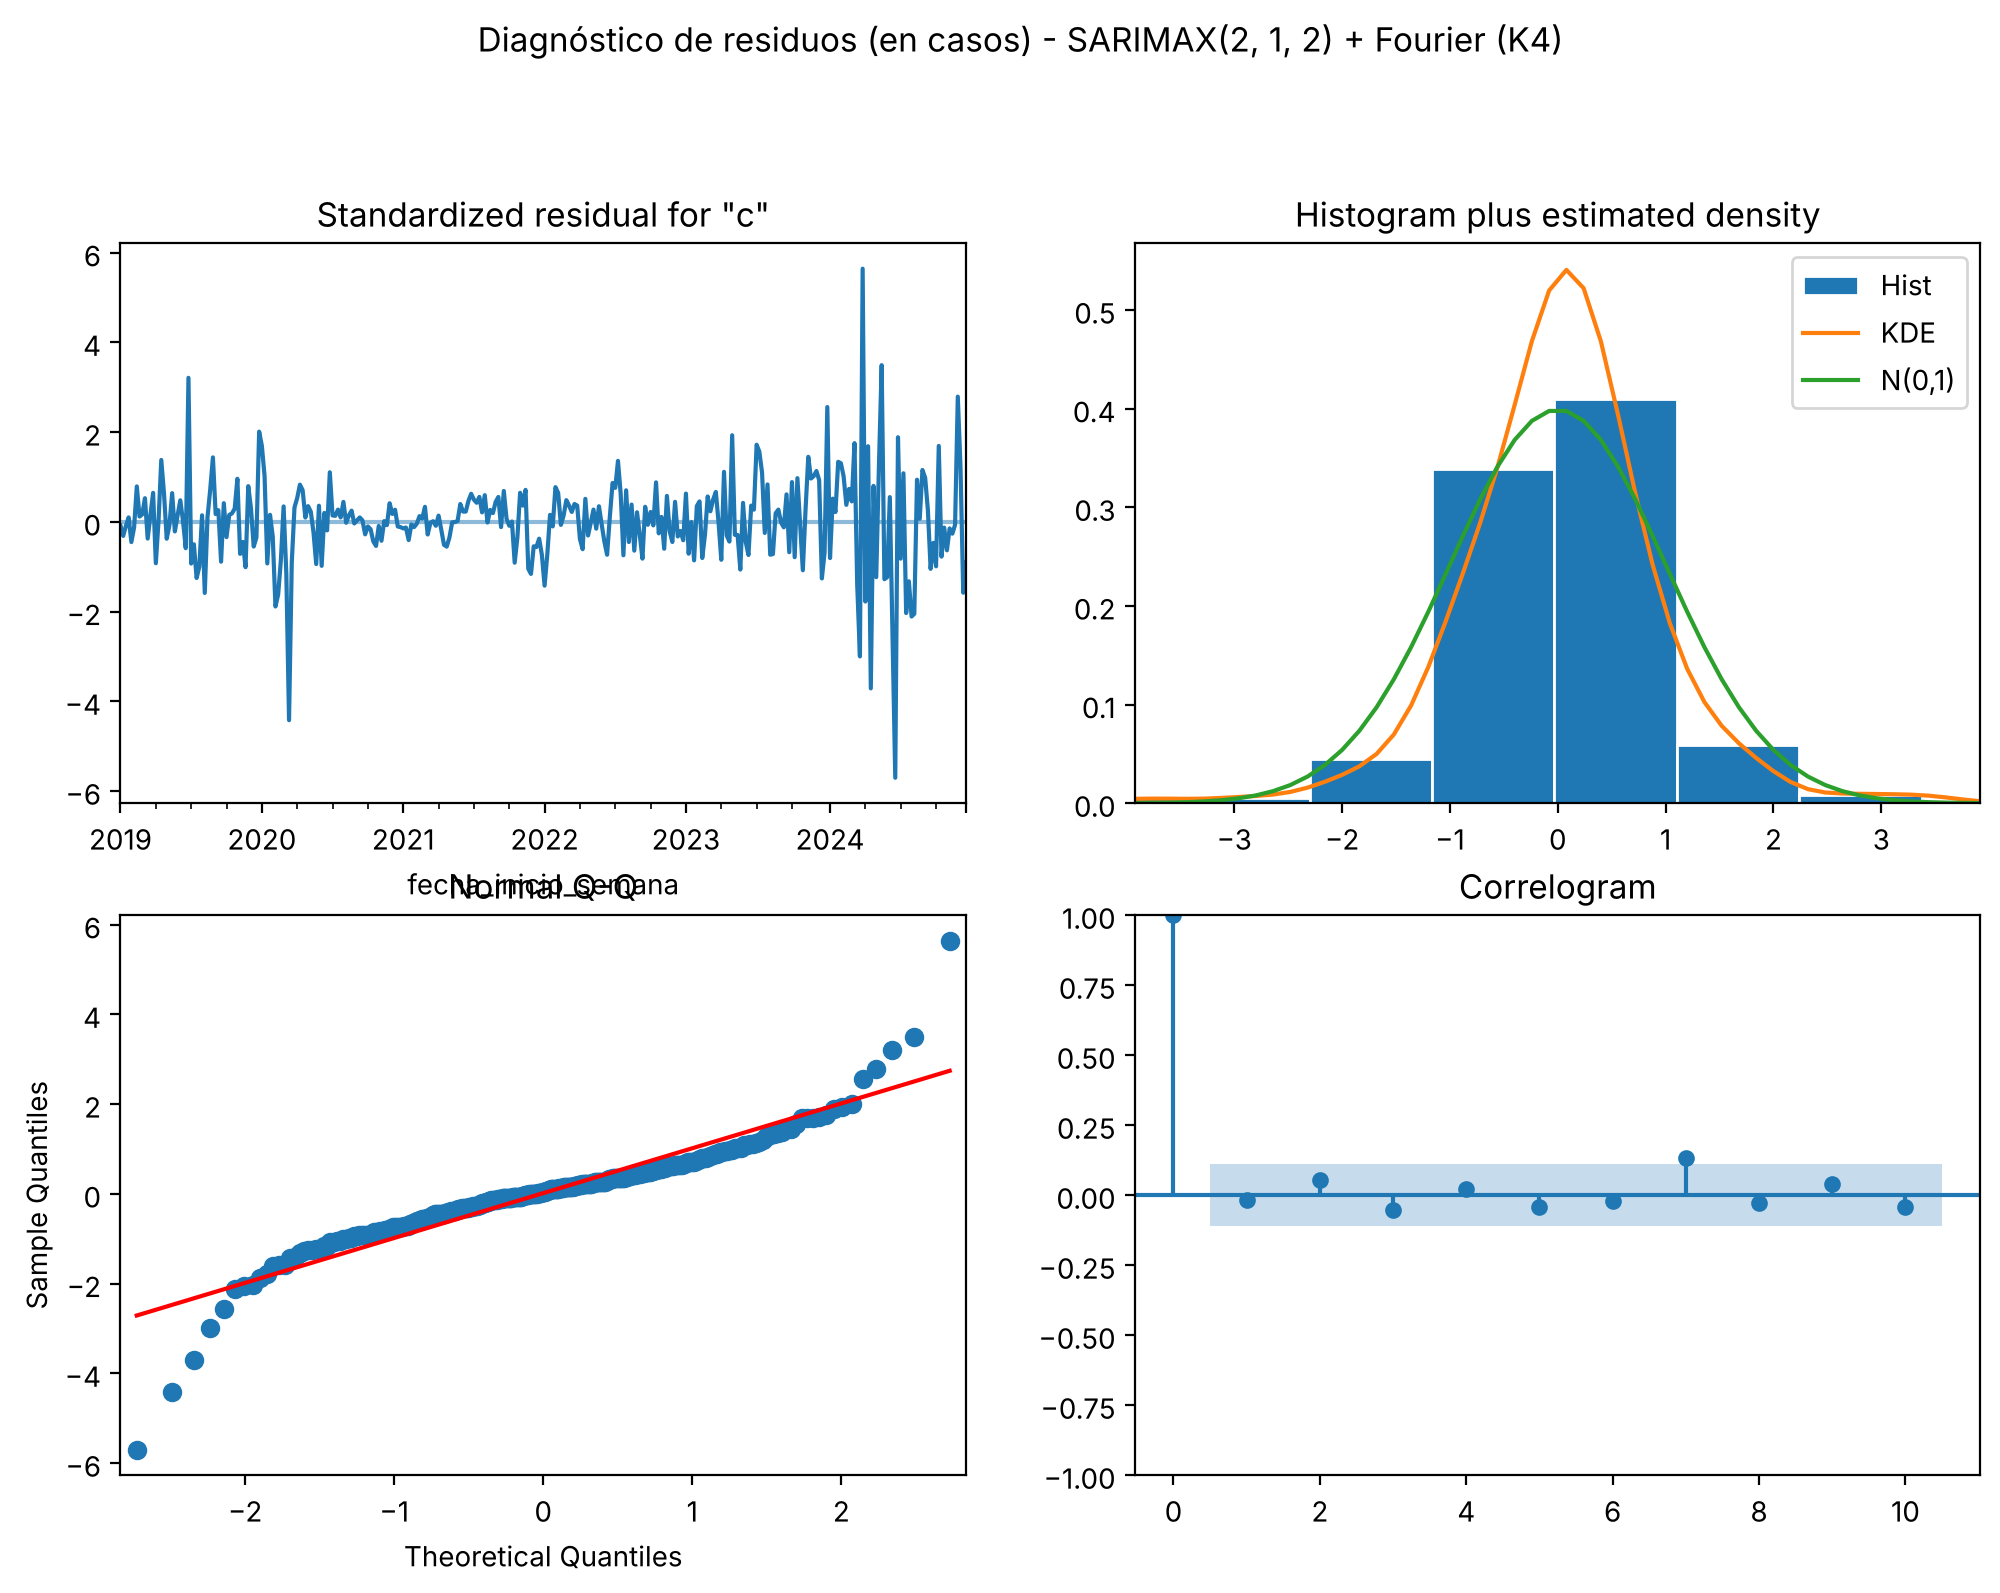

,lb_stat,lb_pvalue
13,62.357768,1.982298e-08
26,87.389021,1.456048e-08
52,126.452889,3.842757e-08


In [39]:
# Verificar ruido blanco
fig = mejor_sarimax_K.plot_diagnostics(figsize=(12,8))
fig.suptitle(f"Diagnóstico de residuos (en casos) - SARIMAX{mejor_sarimax_K.model.order} + Fourier ({mejor_K.split('_')[1]})", y=1.02)
plt.show()

# Ljung-Box
acorr_ljungbox(mejor_sarimax_K.resid[1:], lags=[13, 26, 52], return_df=True)

**Interpretación:** la prueba de Ljung-Box también rechaza H0 en todos los rezagos (p < 0.001). Los residuos siguen sin ser ruido blanco, igual que en los demás modelos de la familia ARIMA.

### 4.4 Diseño de la evaluación y métricas de error

**Horizontes.** Todos los pronósticos se evalúan sobre las 53 semanas de 2025:
- **4 semanas (horizonte principal):** cada semana de 2025 se pronostica 4 semanas antes, con los casos observados hasta ese momento. Por ejemplo, el pronóstico de la semana 10 se hace al final de la semana 6.
- **1 semana:** cada semana se pronostica con los casos observados hasta la semana anterior.
- **Año completo:** las 53 semanas se pronostican de una sola vez, con la información disponible hasta la semana 52 de 2024.

**Reglas para que la comparación sea limpia:**
- Los parámetros y los órdenes de los modelos ARIMA son los estimados con 2019–2024 y **no se reestiman** durante 2025. Solo se agrega la información de las semanas de 2025 que ya pasaron.
- Los términos de Fourier de 2025 se calculan con el calendario, sin usar ningún dato observado.
- El valor esperado del canal endémico es el mismo en los tres horizontes, porque queda fijo antes de empezar el año.

**Métricas de error**
- **RMSE:** raíz del error cuadrático medio, en casos. Penaliza más los errores grandes.
- **MAE:** error absoluto promedio, en casos por semana.
- **MAPE:** error porcentual promedio.
- **MASE:** error escalado frente al método *naive* estacional (m = 52) dentro del entrenamiento. MASE < 1 significa que el modelo se equivoca menos que ese método ingenuo en el entrenamiento.

> El canal endémico, los modelos de referencia y los modelos ARIMA se comparan **solo con estas métricas** y sobre las mismas semanas. El AICc no sirve para esta comparación.

In [40]:
# MASE: error del pronostico escalado por el error del metodo naive estacional (m = 52) en entrenamiento
def mean_absolute_scaled_error(y_true, y_pred, y_train, m=52):
    escala = np.mean(np.abs(np.asarray(y_train)[m:] - np.asarray(y_train)[:-m]))
    return np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred))) / escala

def comparar_pronosticos(pronosticos, y_train):
    y_true = pronosticos["Observado"]
    tab = pd.DataFrame({
        "Modelo" : [c for c in pronosticos.columns if c != "Observado"],
        "RMSE" : [mean_squared_error(y_true, pronosticos[c])**0.5 for c in pronosticos.columns if c != "Observado"],
        "MAE"  : [mean_absolute_error(y_true, pronosticos[c]) for c in pronosticos.columns if c != "Observado"],
        "MAPE (%)" : [mean_absolute_percentage_error(y_true, pronosticos[c]) * 100 for c in pronosticos.columns if c != "Observado"],
        "MASE" : [mean_absolute_scaled_error(y_true, pronosticos[c], y_train) for c in pronosticos.columns if c != "Observado"]
    }).sort_values("RMSE").round(4)
    tab = tab.assign(Ranking=range(1, len(tab) + 1)).set_index("Ranking")

    print("=" * 80)
    print("CAPACIDAD DE PRONÓSTICO EN LA VENTANA DE PRUEBA")
    print("=" * 80)
    print(tab.to_string())
    print("-" * 80)
    print(f"Mejor modelo (menor RMSE): {tab.iloc[0]['Modelo']}")
    print("=" * 80)
    return tab

# Pronostico a un paso con los parametros del entrenamiento (sin reestimar)
def pronostico_un_paso(modelo, exog=None):
    res = modelo.apply(serie_completa, exog=exog)
    return res.get_prediction(start=test.index[0]).predicted_mean

# Pronostico a h semanas: para cada semana objetivo se usan los datos observados hasta h semanas antes
def pronostico_h_semanas(modelo, h, semanas_objetivo, exog=None):
    pronosticos_h = []
    for semana in semanas_objetivo:
        n_obs = serie_completa.index.get_loc(semana) - h + 1   # semanas observadas al momento de pronosticar
        if exog is None:
            res = modelo.apply(serie_completa.iloc[:n_obs])
            f = res.get_forecast(steps=h)
        else:
            res = modelo.apply(serie_completa.iloc[:n_obs], exog=exog.iloc[:n_obs])
            f = res.get_forecast(steps=h, exog=exog.iloc[n_obs:n_obs + h])
        pronosticos_h.append(f.predicted_mean.iloc[-1])
    return np.array(pronosticos_h)

# Error absoluto medio por semestre de 2025: ¿en qué parte del año se equivoca cada modelo?
def mae_por_semestre(pronosticos):
    primer_semestre = (test["SEMANA"] <= 26).values
    modelos_pron = [c for c in pronosticos.columns if c != "Observado"]
    return pd.DataFrame({
        "MAE SE01–SE26": [mean_absolute_error(pronosticos["Observado"][primer_semestre], pronosticos[c][primer_semestre]) for c in modelos_pron],
        "MAE SE27–SE53": [mean_absolute_error(pronosticos["Observado"][~primer_semestre], pronosticos[c][~primer_semestre]) for c in modelos_pron],
    }, index=modelos_pron).round(1)

# Pronostico de referencia del canal endemico: valor esperado de cada semana de 2025 (fijo desde el inicio del año)
pred_canal = canal_2025.loc[test["SEMANA"], "Esperado"].values

# Nombre y colores de los modelos en las graficas
nombre_sarimax_K = f"SARIMAX_Fourier_{mejor_K.split('_')[1]}"
colores = {"Canal_endemico": "#E6A800", "Ingenuo": "grey", "ARIMA": "#d62728", "SARIMA": "#2ca02c",
           "SARIMAX_Fourier_K1": "#9467bd", nombre_sarimax_K: "#17becf"}

## 5. Resultados

Los resultados se presentan en este orden:
- **5.1 y 5.2** Diagnóstico de residuos de los modelos finales y modelo ARIMA-GARCH.
- **5.3** Horizonte principal: pronóstico a 4 semanas en 2025.
- **5.4 y 5.5** Análisis complementarios: 1 semana y año completo.
- **5.6** Evaluación con cuatro años de prueba (2022–2025).
- **5.7** Selección del modelo final.
- **5.8** Pronóstico de 2026-SE01 a 2026-SE04 y su lectura sobre el canal endémico de 2026.

### 5.1 Diagnóstico de residuos de los modelos finales

Para el mejor modelo de cada tipo (por AICc) se reúnen en una sola tabla tres grupos de pruebas sobre los residuos:

- **Autocorrelación – Ljung-Box** (rezagos 13, 26 y 52: un trimestre, un semestre y un año). H0: los residuos no están autocorrelacionados (son ruido blanco). Si p < 0.05 queda autocorrelación sin modelar.
- **Normalidad – Jarque-Bera y Shapiro-Wilk.** H0: los residuos son normales. Si p < 0.05 no lo son.
- **Heterocedasticidad condicional – ARCH-LM** (13 rezagos). H0: la varianza de los residuos no depende del tamaño de los errores recientes (no hay efecto ARCH). Si p < 0.05 hay efecto ARCH: después de un error grande tienden a venir más errores grandes.

In [41]:
# Diagnostico de residuos de los modelos finales de cada tipo (estimados con el entrenamiento)
def diagnostico_residuos(modelos: dict, rezagos=[13, 26, 52], rezagos_arch=13) -> pd.DataFrame:
    filas = []
    for nombre, m in modelos.items():
        res = m.resid[1:]
        lb = acorr_ljungbox(res, lags=rezagos, return_df=True)
        jb_est, jb_p = stats.jarque_bera(res)
        sw_est, sw_p = stats.shapiro(res)
        arch_est, arch_p, _, _ = het_arch(res, nlags=rezagos_arch)
        fila = {"Modelo": nombre}
        for k in rezagos:
            fila[f"Ljung-Box p (rezago {k})"] = lb.loc[k, "lb_pvalue"]
        fila["Ruido blanco"] = "Sí" if (lb["lb_pvalue"] >= 0.05).all() else "No"
        fila["Jarque-Bera (estadístico)"] = jb_est
        fila["Jarque-Bera p"] = jb_p
        fila["Shapiro-Wilk (estadístico)"] = sw_est
        fila["Shapiro-Wilk p"] = sw_p
        fila["Residuos normales"] = "Sí" if (jb_p >= 0.05 and sw_p >= 0.05) else "No"
        fila[f"ARCH-LM (estadístico, {rezagos_arch} rezagos)"] = arch_est
        fila["ARCH-LM p"] = arch_p
        fila["Efecto ARCH"] = "Sí" if arch_p < 0.05 else "No"
        filas.append(fila)
    return pd.DataFrame(filas).set_index("Modelo")

modelos_finales = {
    f"ARIMA{mejor_arima.model.order}" : mejor_arima,
    f"SARIMA{mejor_sarima.model.order}{mejor_sarima.model.seasonal_order}" : mejor_sarima,
    f"SARIMAX{mejor_sarimax.model.order} + Fourier K1" : mejor_sarimax,
    f"SARIMAX{mejor_sarimax_K.model.order} + Fourier {mejor_K.split('_')[1]}" : mejor_sarimax_K,
}
tab_diagnostico = diagnostico_residuos(modelos_finales)

print("=" * 100)
print("DIAGNÓSTICO DE RESIDUOS DE LOS MODELOS FINALES")
print("=" * 100)
print(tab_diagnostico.T.apply(lambda col: col.map(lambda v: f"{v:.4g}" if isinstance(v, float) else v)).to_string())
print("=" * 100)

DIAGNÓSTICO DE RESIDUOS DE LOS MODELOS FINALES
Modelo                            ARIMA(2, 1, 2) SARIMA(2, 1, 2)(0, 0, 1, 52) SARIMAX(2, 1, 2) + Fourier K1 SARIMAX(2, 1, 2) + Fourier K4
Ljung-Box p (rezago 13)                1.983e-08                    9.905e-08                     2.064e-08                     1.982e-08
Ljung-Box p (rezago 26)                 2.55e-08                     4.79e-07                     3.003e-08                     1.456e-08
Ljung-Box p (rezago 52)                6.935e-08                    7.701e-06                     7.323e-08                     3.843e-08
Ruido blanco                                  No                           No                            No                            No
Jarque-Bera (estadístico)                  954.1                         1116                         927.1                         829.3
Jarque-Bera p                         6.583e-208                   3.756e-243                     4.78e-202                  

**Interpretación**

| Prueba | Resultado en los cuatro modelos | Conclusión |
| :--- | :--- | :--- |
| Ljung-Box (rezagos 13, 26 y 52) | p < 0.001 en todos los rezagos | **No son ruido blanco:** queda autocorrelación sin modelar |
| Jarque-Bera y Shapiro-Wilk | p < 0.001 (Jarque-Bera entre 829.3 y 1 116; Shapiro-Wilk entre 0.8807 y 0.8956) | **No son normales:** hay más errores grandes de los que tendría una distribución normal |
| ARCH-LM (13 rezagos) | Estadístico entre 66.74 y 69.99, p < 0.001 | **Hay efecto ARCH:** la varianza de los errores no es constante |

- **Los cuatro modelos fallan las tres pruebas, y de forma muy parecida.** Agregar la estacionalidad de 52 semanas o los términos de Fourier no cambia el diagnóstico.
- **¿Qué significa para el pronóstico?**
  - El pronóstico puntual (el número de casos) se puede usar, pero no aprovecha toda la información de la serie: queda estructura sin modelar.
  - Los **intervalos de pronóstico** de estos modelos suponen errores normales con varianza constante. Como eso no se cumple, quedan **demasiado angostos en las epidemias y demasiado anchos en los periodos tranquilos**.
- **El efecto ARCH justifica el modelo GARCH** de la sección 5.2.

### 5.2 Modelo ARIMA-GARCH(1,1)

Si la prueba ARCH-LM detecta heterocedasticidad condicional, la varianza del error no es constante y se puede modelar con un GARCH(1,1). El ARIMA sigue modelando la **media** (cuántos casos se esperan) y el GARCH modela la **varianza** del error (qué tan incierto es ese pronóstico):

$$ e_t = \sigma_t z_t, \qquad \sigma_t^2 = \omega + \alpha\, e_{t-1}^2 + \beta\, \sigma_{t-1}^2 $$

- $e_t$ es el residuo del ARIMA en la semana $t$ y $\sigma_t$ es la **volatilidad condicional**: la desviación estándar del error que el modelo espera para esa semana.
- $\alpha$ mide cuánto sube la varianza después de un error grande, y $\beta$ cuánto tarda en volver a bajar. La suma $\alpha + \beta$ es la **persistencia**: cuanto más cerca de 1, más duran los periodos de alta variabilidad.

Se estima en dos pasos: primero el ARIMA y después el GARCH(1,1) sobre sus residuos, con media cero (librería `arch`).

In [42]:
# Modelo GARCH(1,1) sobre los residuos del mejor ARIMA (media cero): la media la modela el ARIMA y la varianza el GARCH
resid_arima = mejor_arima.resid[1:]
garch = arch_model(resid_arima, mean="Zero", vol="GARCH", p=1, q=1, rescale=False).fit(disp="off")
print(garch.summary())
print(f"\nPersistencia de la volatilidad (alpha + beta): {garch.params['alpha[1]'] + garch.params['beta[1]']:.4f}")

                       Zero Mean - GARCH Model Results                        
Dep. Variable:                   None   R-squared:                       0.000
Mean Model:                 Zero Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -2036.38
Distribution:                  Normal   AIC:                           4078.75
Method:            Maximum Likelihood   BIC:                           4089.98
                                        No. Observations:                  312
Date:                Thu, Nov 19 2026   Df Residuals:                      312
Time:                        19:05:27   Df Model:                            0
                               Volatility Model                              
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
omega        345.3925    275.471      1.254      0.210 

DIAGNÓSTICO ANTES Y DESPUÉS DEL GARCH(1,1)
                                   Residuos del ARIMA  Residuos estandarizados ARIMA-GARCH
Ljung-Box p (rezago 13)                     1.983e-08                              0.04582
Ljung-Box p (rezago 26)                      2.55e-08                              0.04672
Ljung-Box p (rezago 52)                     6.935e-08                            0.0002873
Ljung-Box residuos² p (rezago 13)           2.172e-24                               0.8806
Ljung-Box residuos² p (rezago 26)           1.779e-20                               0.9774
Ljung-Box residuos² p (rezago 52)           2.953e-13                                0.327
ARCH-LM p (13 rezagos)                      1.339e-09                               0.8664
Jarque-Bera p                              6.583e-208                            5.707e-12
Curtosis                                        11.55                                4.821

Desviación estándar constante del ARIMA: 228.4

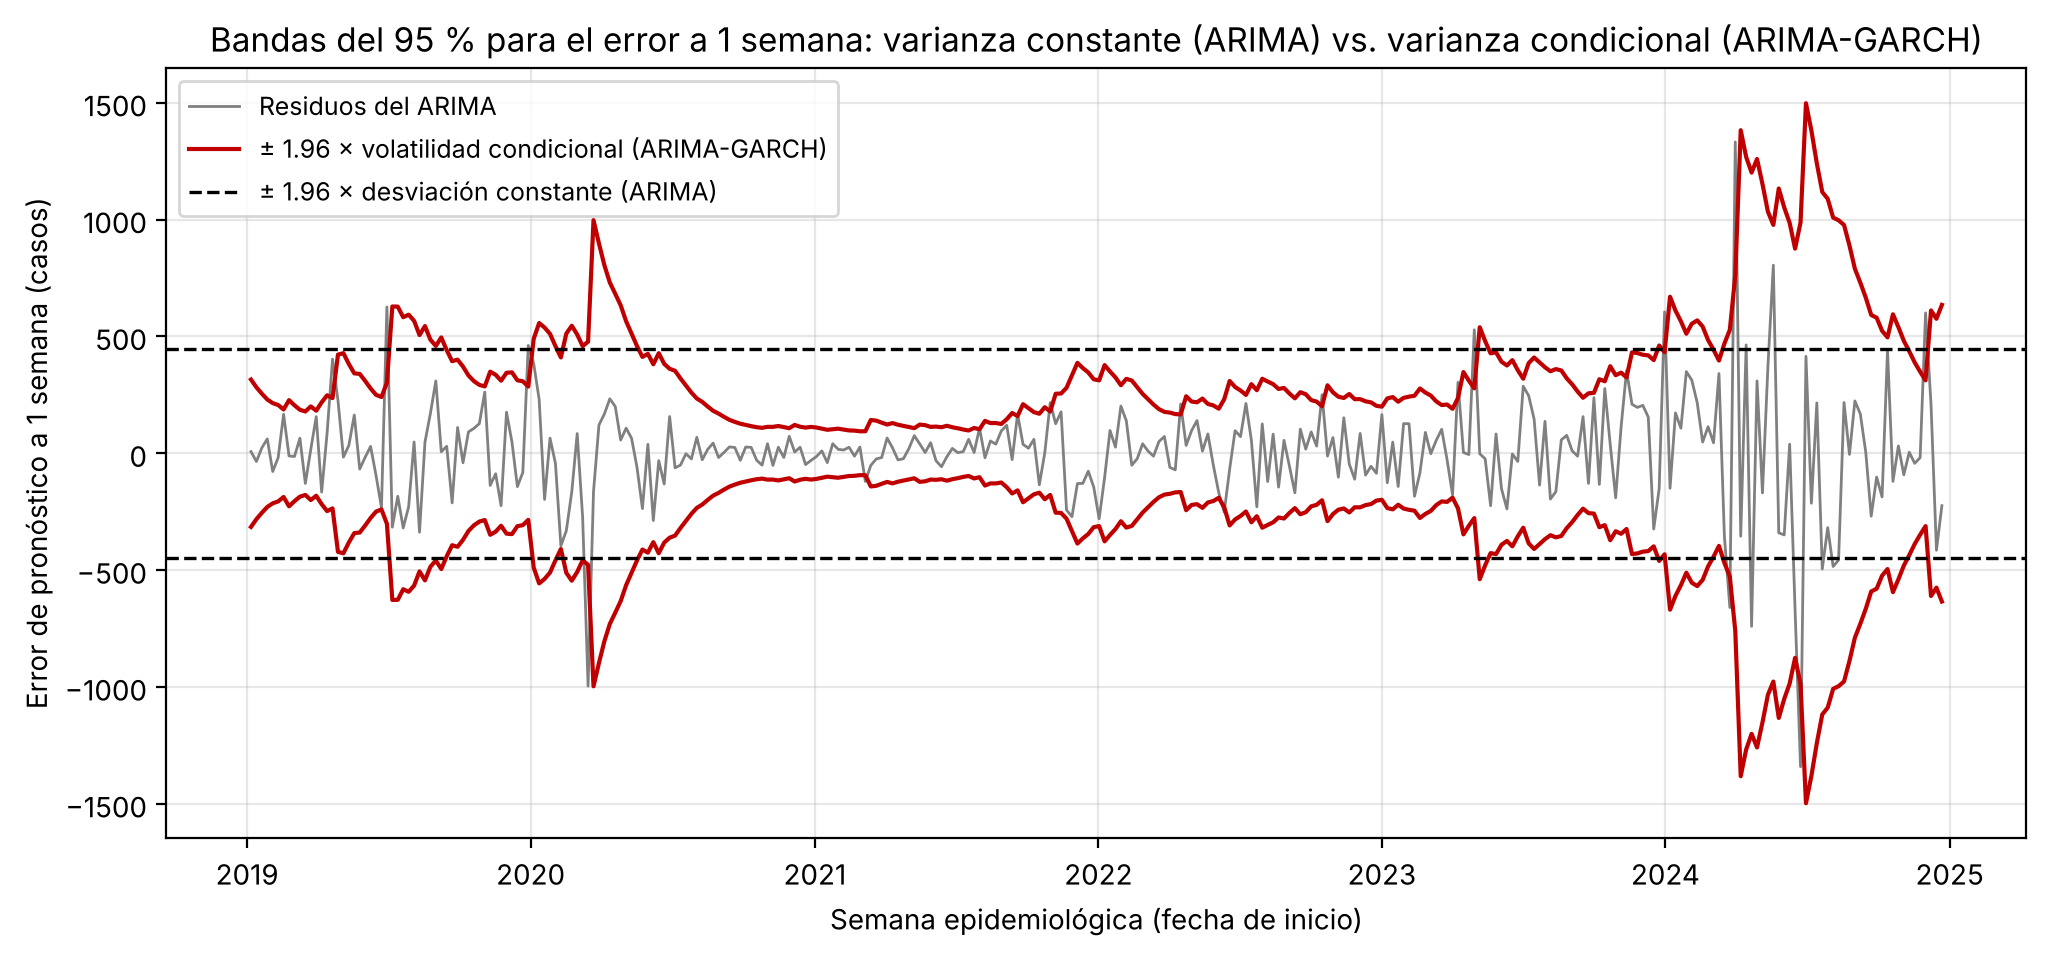

In [43]:
# Diagnostico: residuos del ARIMA frente a residuos estandarizados del ARIMA-GARCH (residuo / volatilidad condicional)
resid_estandarizados = garch.std_resid

def diagnostico_serie(res):
    lb = acorr_ljungbox(res, lags=[13, 26, 52], return_df=True)["lb_pvalue"]
    lb2 = acorr_ljungbox(res**2, lags=[13, 26, 52], return_df=True)["lb_pvalue"]
    return {"Ljung-Box p (rezago 13)": lb[13], "Ljung-Box p (rezago 26)": lb[26], "Ljung-Box p (rezago 52)": lb[52],
            "Ljung-Box residuos² p (rezago 13)": lb2[13], "Ljung-Box residuos² p (rezago 26)": lb2[26], "Ljung-Box residuos² p (rezago 52)": lb2[52],
            "ARCH-LM p (13 rezagos)": het_arch(res, nlags=13)[1],
            "Jarque-Bera p": stats.jarque_bera(res)[1],
            "Curtosis": stats.kurtosis(res, fisher=False)}

tab_garch = pd.DataFrame({"Residuos del ARIMA": diagnostico_serie(resid_arima),
                          "Residuos estandarizados ARIMA-GARCH": diagnostico_serie(resid_estandarizados)})
print("=" * 90)
print("DIAGNÓSTICO ANTES Y DESPUÉS DEL GARCH(1,1)")
print("=" * 90)
print(tab_garch.to_string(float_format=lambda v: f"{v:.4g}"))
print("=" * 90)

# Volatilidad condicional (desviacion estandar del error que estima el GARCH para cada semana), en casos
volatilidad = garch.conditional_volatility
sigma_arima = np.sqrt(mejor_arima.params["sigma2"])
tab_volatilidad = volatilidad.groupby(train.loc[volatilidad.index, "ANO"]).agg(["mean", "min", "max"]).round(1)
tab_volatilidad.columns = ["Volatilidad media", "Mínima", "Máxima"]
print(f"\nDesviación estándar constante del ARIMA: {sigma_arima:.1f} casos")
print(f"Volatilidad condicional del GARCH: media {volatilidad.mean():.1f}, mínima {volatilidad.min():.1f}, máxima {volatilidad.max():.1f} casos")
semana_max = volatilidad.idxmax()
print(f"Semana de máxima volatilidad: {int(train.loc[semana_max, 'ANO'])}-SE{int(train.loc[semana_max, 'SEMANA']):02d}")
print(f"Semiancho del intervalo del 95 % a 1 semana: ARIMA {1.96 * sigma_arima:.0f} casos (constante); "
      f"ARIMA-GARCH entre {1.96 * volatilidad.min():.0f} y {1.96 * volatilidad.max():.0f} casos")
print()
print(tab_volatilidad.to_string())

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(resid_arima.index, resid_arima, color="grey", linewidth=1, label="Residuos del ARIMA")
ax.plot(volatilidad.index, 1.96 * volatilidad, color="#C00000", linewidth=1.5, label="± 1.96 × volatilidad condicional (ARIMA-GARCH)")
ax.plot(volatilidad.index, -1.96 * volatilidad, color="#C00000", linewidth=1.5)
ax.axhline(1.96 * sigma_arima, color="black", linestyle="--", linewidth=1.2, label="± 1.96 × desviación constante (ARIMA)")
ax.axhline(-1.96 * sigma_arima, color="black", linestyle="--", linewidth=1.2)
ax.set_xlabel("Semana epidemiológica (fecha de inicio)")
ax.set_ylabel("Error de pronóstico a 1 semana (casos)")
ax.set_title("Bandas del 95 % para el error a 1 semana: varianza constante (ARIMA) vs. varianza condicional (ARIMA-GARCH)")
ax.legend(loc="upper left", fontsize=9)
ax.grid(True, alpha=0.3)
plt.show()

**Interpretación**

**Parámetros**
- **α = 0.2134 y β = 0.7866,** los dos significativos (p < 0.001). El término ω (345.4) no es significativo (p = 0.210).
- **La persistencia α + β es 1.0000.** Los periodos de alta variabilidad duran mucho: después de un error grande, la incertidumbre tarda muchas semanas en volver a bajar. Es lo que pasa en una epidemia.

**Diagnóstico**
- **El GARCH corrige el efecto ARCH:** el p-valor de la prueba ARCH-LM pasa de menos de 0.001 a 0.8664, y la prueba de Ljung-Box sobre los residuos al cuadrado ya no rechaza H0 (p = 0.8806, 0.9774 y 0.327).
- **La autocorrelación mejora, pero no desaparece:** en los residuos estandarizados, Ljung-Box queda en el límite en los rezagos 13 y 26 (p = 0.0458 y 0.0467) y sigue rechazando en el 52 (p ≈ 0.0003). Es esperable, porque el GARCH modela la varianza y no cambia la media.
- **Las colas se reducen:** la curtosis baja de 11.55 a 4.821, aunque Jarque-Bera sigue rechazando la normalidad.

**¿Qué aporta el GARCH?**
- **No cambia el número de casos pronosticado.** Cambia qué tan ancho es el intervalo alrededor de ese número.
- El ARIMA supone la misma incertidumbre en todas las semanas: una desviación de 228.4 casos, es decir, un intervalo del 95 % a 1 semana de **± 448 casos siempre**.
- Con el GARCH, ese intervalo va de **± 94 casos** en las semanas más tranquilas a **± 1 498 casos** en la más variable (2024-SE27). La volatilidad media fue de 79.6 casos en 2021 y de 395.7 en 2024.
- En la gráfica, las bandas del ARIMA-GARCH (rojo) **se ensanchan en la epidemia de 2024 y en la caída de 2020, y se angostan en 2021–2022**, siguiendo el tamaño real de los errores. Las bandas constantes (negro punteado) quedan muy anchas en los años tranquilos y muy angostas en la epidemia.
- **Relación con el canal endémico:** cuando el canal marca brote, la incertidumbre del pronóstico es mayor. El ARIMA-GARCH lo refleja con intervalos más anchos: en una epidemia el pronóstico se debe leer con más cautela.

### 5.3 Horizonte principal: pronóstico a 4 semanas en 2025

Es el horizonte de la pregunta de pronóstico: el INS analiza el dengue en periodos de 4 semanas. Para cada semana de 2025, cada modelo la pronostica **4 semanas antes**, con los casos observados hasta ese momento.

- **Ejemplo:** el pronóstico de la semana 10 se hace al final de la semana 6, con los datos hasta la semana 6.
- **Parámetros:** son los estimados con 2019–2024 y no se reestiman.
- **Modelos de referencia:** el ingenuo y el ingenuo con deriva usan el dato de 4 semanas antes; el ingenuo estacional, el de 52 semanas antes.
- **Canal endémico:** su valor es el esperado de cada semana, fijo desde el inicio del año.

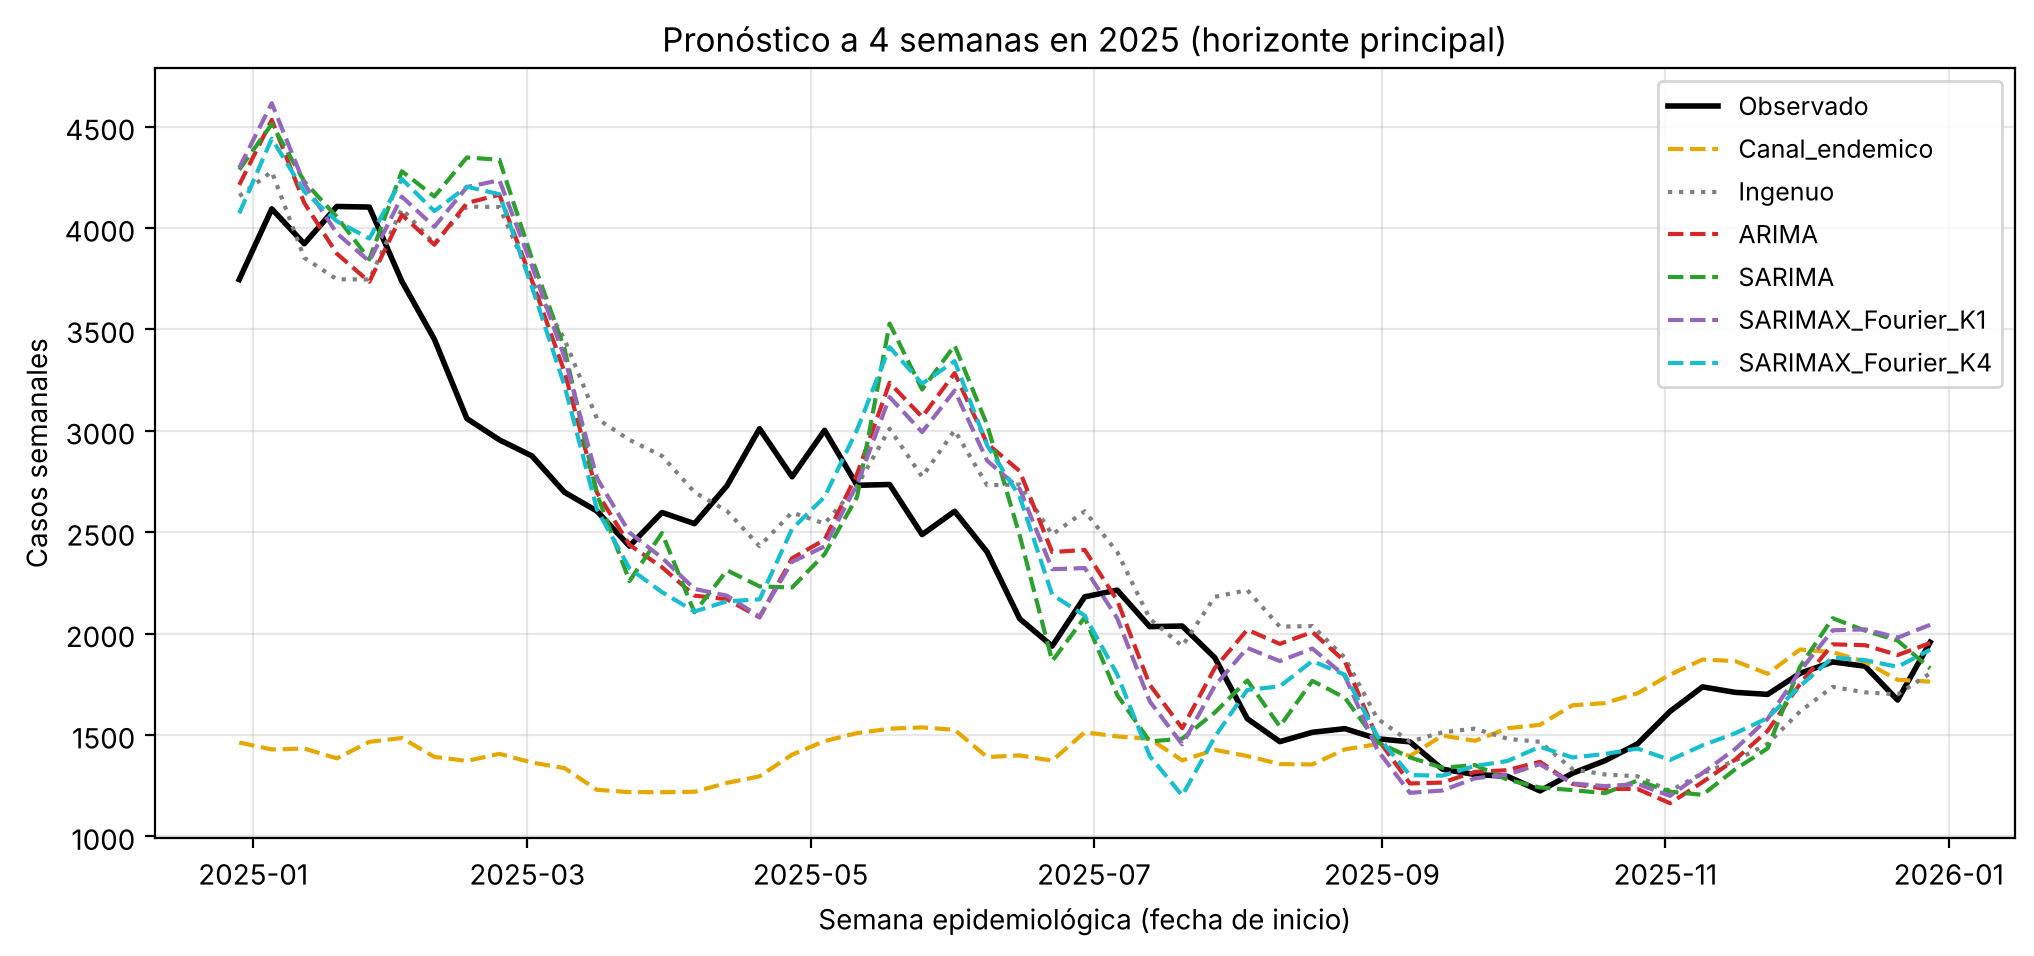

CAPACIDAD DE PRONÓSTICO EN LA VENTANA DE PRUEBA
                     Modelo       RMSE        MAE  MAPE (%)    MASE
Ranking                                                            
1                   Ingenuo   415.0497   332.0566   14.9735  0.2088
2            Ingenuo_deriva   423.9733   337.9961   15.2103  0.2125
3                     ARIMA   445.8380   350.5519   15.1101  0.2204
4        SARIMAX_Fourier_K4   448.7013   339.8566   14.2422  0.2137
5        SARIMAX_Fourier_K1   449.3895   353.3561   15.0438  0.2222
6                    SARIMA   486.1229   368.3290   15.1403  0.2316
7            Canal_endemico  1207.9185   902.2670   32.5512  0.5673
8        Ingenuo_estacional  4029.2572  3673.4340  173.5037  2.3099
--------------------------------------------------------------------------------
Mejor modelo (menor RMSE): Ingenuo


In [44]:
# Pronostico a 4 semanas en 2025 (horizonte principal)
ing_4, est_4, der_4 = pronostico_ingenuos(serie_completa, test.index, 4)
pronosticos_4sem = pd.DataFrame({
    "Observado" : test["casos"],
    "Canal_endemico" : pred_canal,
    "Ingenuo" : ing_4,
    "Ingenuo_estacional" : est_4,
    "Ingenuo_deriva" : der_4,
    "ARIMA" : pronostico_h_semanas(mejor_arima, 4, test.index),
    "SARIMA" : pronostico_h_semanas(mejor_sarima, 4, test.index),
    "SARIMAX_Fourier_K1" : pronostico_h_semanas(mejor_sarimax, 4, test.index, fourier[vars_exog]),
    nombre_sarimax_K : pronostico_h_semanas(mejor_sarimax_K, 4, test.index, fourier[vars_mejor_K])
}, index=test.index)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(test.index, test["casos"], label="Observado", color="black", linewidth=2)
for modelo, color in colores.items():
    ax.plot(pronosticos_4sem.index, pronosticos_4sem[modelo], label=modelo, color=color, linestyle=":" if modelo == "Ingenuo" else "--")
ax.set_xlabel("Semana epidemiológica (fecha de inicio)")
ax.set_ylabel("Casos semanales")
ax.set_title("Pronóstico a 4 semanas en 2025 (horizonte principal)")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.show()

tab_metricas_4sem = comparar_pronosticos(pronosticos_4sem, serie_train)

In [45]:
# Error por semestre a 4 semanas
mae_semestre_4sem = mae_por_semestre(pronosticos_4sem)
mae_semestre_4sem

,MAE SE01–SE26,MAE SE27–SE53
Canal_endemico,1588.2,241.7
Ingenuo,433.6,234.3
Ingenuo_estacional,4333.0,3038.3
Ingenuo_deriva,443.6,236.3
ARIMA,497.4,209.1
SARIMA,531.3,211.4
SARIMAX_Fourier_K1,500.3,211.9
SARIMAX_Fourier_K4,491.1,194.3


**Interpretación**

| Herramienta | RMSE | MAE | MAPE (%) |
| :--- | :--- | :--- | :--- |
| Ingenuo (último valor) | 415.0 | 332.1 | 15.0 |
| Ingenuo con deriva | 424.0 | 338.0 | 15.2 |
| ARIMA(2,1,2) | 445.8 | 350.6 | 15.1 |
| SARIMAX + Fourier K = 4 | 448.7 | 339.9 | 14.2 |
| SARIMAX + Fourier K = 1 | 449.4 | 353.4 | 15.0 |
| SARIMA(2,1,2)(0,0,1)₅₂ | 486.1 | 368.3 | 15.1 |
| Valor esperado del canal | 1 207.9 | 902.3 | 32.6 |
| Ingenuo estacional | 4 029.3 | 3 673.4 | 173.5 |

- **A 4 semanas, los modelos que usan los casos recientes anticipan mucho mejor que "lo normal".** El MAE de la familia ARIMA está entre 339.9 y 368.3 casos por semana (MAPE entre 14.2 % y 15.1 %), frente a 902.3 casos (MAPE 32.6 %) del valor esperado del canal.
- **La familia ARIMA no supera al modelo ingenuo.** El ingenuo tiene el menor RMSE (415.0) y el menor MAE (332.1); el ARIMA(2,1,2) queda tercero (RMSE 445.8). El SARIMAX con K = 4 tiene el menor MAPE (14.2 %). Las diferencias dentro de este grupo son pequeñas. Es decir, **lo que hace la diferencia frente al canal no es la complejidad del modelo, sino usar los datos más recientes.** Este punto se retoma en la selección del modelo final (sección 5.7).
- **El ingenuo estacional es el peor** (MAPE 173.5 %): pronosticar 2025 con la misma semana de 2024 es repetir la epidemia. Confirma que en esta serie "lo que pasó hace un año" no sirve de guía.
- **Los modelos reaccionan tarde:** en la gráfica, sus curvas parecen la curva observada corrida unas semanas a la derecha, porque solo conocen los datos hasta 4 semanas antes.

**En qué falla cada herramienta y cómo la cubre la otra (error por semestre)**
- **Primer semestre (cola de la epidemia):** el valor esperado del canal se equivoca en 1 588.2 casos por semana; el ARIMA, en 497.4, y el ingenuo, en 433.6. Aquí el canal no sirve para saber cuántos casos vienen, **pero clasificó correctamente esas semanas como brote** (sección 4.1.3). Son dos respuestas distintas y las dos son útiles: el canal dice "esto es anormal" y el modelo dice "el próximo periodo habrá alrededor de tantos casos".
- **Segundo semestre (regreso a la normalidad):** los errores se parecen: 241.7 casos el canal, 209.1 el ARIMA y 234.3 el ingenuo. Cuando el año vuelve a ser normal, "lo normal" también funciona como pronóstico, y el canal confirma que los casos están dentro de lo esperado.

### 5.4 Análisis complementario: pronóstico a 1 semana, actualizando con los casos observados

Aquí cada modelo pronostica **solo la semana siguiente** usando los casos observados hasta la semana anterior.

- Los parámetros **no se reestiman**: son los mismos estimados con 2019–2024. Solo se agrega la información de las semanas de 2025 que ya pasaron.
- El valor esperado del canal endémico no cambia, porque se fija antes de empezar el año y no usa los casos que van llegando.

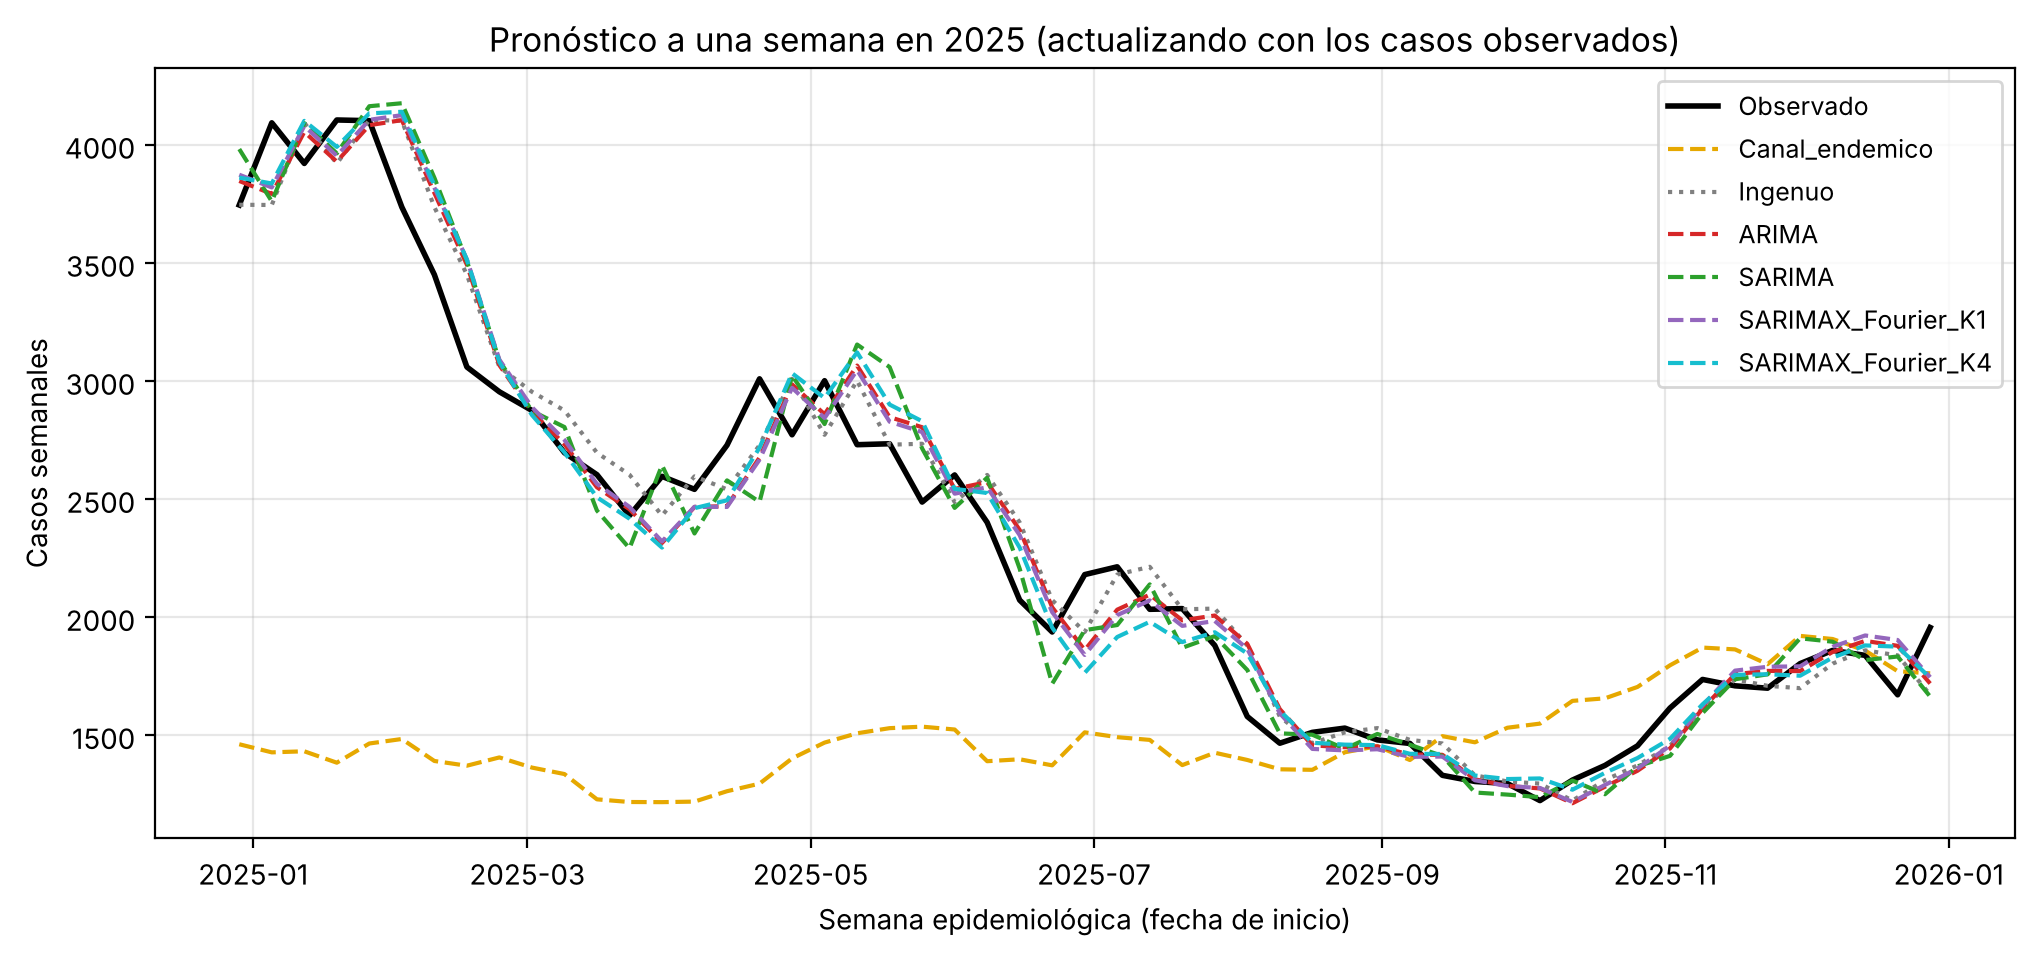

CAPACIDAD DE PRONÓSTICO EN LA VENTANA DE PRUEBA
                     Modelo       RMSE        MAE  MAPE (%)    MASE
Ranking                                                            
1                   Ingenuo   175.9724   140.0000    6.0915  0.0880
2            Ingenuo_deriva   176.9631   140.9406    6.1235  0.0886
3                     ARIMA   183.1729   143.9726    6.2750  0.0905
4        SARIMAX_Fourier_K1   183.2349   144.2209    6.2605  0.0907
5        SARIMAX_Fourier_K4   188.2009   142.2090    6.0702  0.0894
6                    SARIMA   202.3615   158.1796    6.5470  0.0995
7            Canal_endemico  1207.9185   902.2670   32.5512  0.5673
8        Ingenuo_estacional  4029.2572  3673.4340  173.5037  2.3099
--------------------------------------------------------------------------------
Mejor modelo (menor RMSE): Ingenuo


In [46]:
# Pronostico a 1 semana en 2025 (parametros del entrenamiento, sin reestimar)
ing_1, est_1, der_1 = pronostico_ingenuos(serie_completa, test.index, 1)
pronosticos_1paso = pd.DataFrame({
    "Observado" : test["casos"],
    "Canal_endemico" : pred_canal,
    "Ingenuo" : ing_1,
    "Ingenuo_estacional" : est_1,
    "Ingenuo_deriva" : der_1,
    "ARIMA" : pronostico_un_paso(mejor_arima).values,
    "SARIMA" : pronostico_un_paso(mejor_sarima).values,
    "SARIMAX_Fourier_K1" : pronostico_un_paso(mejor_sarimax, fourier[vars_exog]).values,
    nombre_sarimax_K : pronostico_un_paso(mejor_sarimax_K, fourier[vars_mejor_K]).values
}, index=test.index)

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(test.index, test["casos"], label="Observado", color="black", linewidth=2)
for modelo, color in colores.items():
    ax.plot(pronosticos_1paso.index, pronosticos_1paso[modelo], label=modelo, color=color, linestyle=":" if modelo == "Ingenuo" else "--")
ax.set_xlabel("Semana epidemiológica (fecha de inicio)")
ax.set_ylabel("Casos semanales")
ax.set_title("Pronóstico a una semana en 2025 (actualizando con los casos observados)")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.show()

tab_metricas_1paso = comparar_pronosticos(pronosticos_1paso, serie_train)

**Interpretación**

- **A 1 semana el error baja todavía más.** El ingenuo y la familia ARIMA pronostican la semana siguiente con un MAE de entre 140.0 y 158.2 casos (MAPE entre 6.1 % y 6.5 %), frente a 902.3 casos (MAPE 32.6 %) del valor esperado del canal: unas 6 veces menos.
- **El orden es el mismo que a 4 semanas:** el ingenuo tiene el menor RMSE (176.0) y el menor MAE (140.0); el ARIMA(2,1,2) queda muy cerca (RMSE 183.2, MAE 144.0); el SARIMAX con K = 4 tiene el menor MAPE (6.07 %) y el SARIMA es un poco peor (MAE 158.2).
- **El error crece con el horizonte:** el MAE del ARIMA pasa de 144.0 casos a 1 semana a 350.6 a 4 semanas. Cuanto más lejos se pronostica, menos ayuda el último dato.
- **El error del canal es el mismo que a 4 semanas** (MAE 902.3), porque su valor esperado está fijo desde el inicio del año y no usa los casos que van llegando. Esa es su naturaleza como referencia: no cambia con el horizonte.

### 5.5 Análisis complementario: pronóstico del año completo (2025-SE01 – 2025-SE53)

Todos los pronósticos se hacen **de una sola vez para las 53 semanas de 2025**, con la información disponible hasta la semana 52 de 2024. Es el horizonte en el que el canal y los modelos están en igualdad de condiciones, porque ninguno usa datos de 2025:
- **ARIMA y SARIMA:** pronóstico a 53 pasos.
- **SARIMAX:** los términos de Fourier de 2025 se calculan con el calendario, sin usar ningún dato observado de 2025.
- **Modelos de referencia:** el ingenuo repite la semana 52 de 2024, el ingenuo estacional repite las 52 semanas de 2024 y el ingenuo con deriva suma el cambio promedio histórico.
- **Canal endémico:** el valor esperado (media geométrica de 2019–2023) de cada semana.

In [47]:
# Pronostico de las 53 semanas de 2025 de una sola vez, con la informacion disponible hasta 2024-SE52
h = len(test)

# Modelos de referencia
ing_anio, est_anio, der_anio = pronostico_ingenuos_anio(serie_train, h)

# 1. ARIMA
pred_arima = mejor_arima.get_forecast(steps=h).predicted_mean

# 2. SARIMA
pred_sarima = mejor_sarima.get_forecast(steps=h).predicted_mean

# 3. SARIMAX con Fourier K = 1 (los terminos de Fourier de 2025 se conocen por calendario)
pred_sarimax = mejor_sarimax.get_forecast(steps=h, exog=fourier.loc[test.index, vars_exog]).predicted_mean

# 4. SARIMAX con el mejor numero de armonicos
pred_sarimax_K = mejor_sarimax_K.get_forecast(steps=h, exog=fourier.loc[test.index, vars_mejor_K]).predicted_mean

pronosticos = pd.DataFrame({
    "Observado" : test["casos"],
    "Canal_endemico" : pred_canal,
    "Ingenuo" : ing_anio,
    "Ingenuo_estacional" : est_anio,
    "Ingenuo_deriva" : der_anio,
    "ARIMA" : pred_arima.values,
    "SARIMA" : pred_sarima.values,
    "SARIMAX_Fourier_K1" : pred_sarimax.values,
    nombre_sarimax_K : pred_sarimax_K.values
}, index=test.index)

# Rango de cada pronostico (minimo y maximo de las 53 semanas)
print(pronosticos.agg(["min", "max"]).round(0).T.to_string())

                       min     max
Observado           1224.0  4106.0
Canal_endemico      1217.0  1921.0
Ingenuo             3747.0  3747.0
Ingenuo_estacional  3570.0  9410.0
Ingenuo_deriva      3754.0  4099.0
ARIMA               3763.0  3885.0
SARIMA              3359.0  4902.0
SARIMAX_Fourier_K1  3479.0  4167.0
SARIMAX_Fourier_K4  3461.0  4454.0


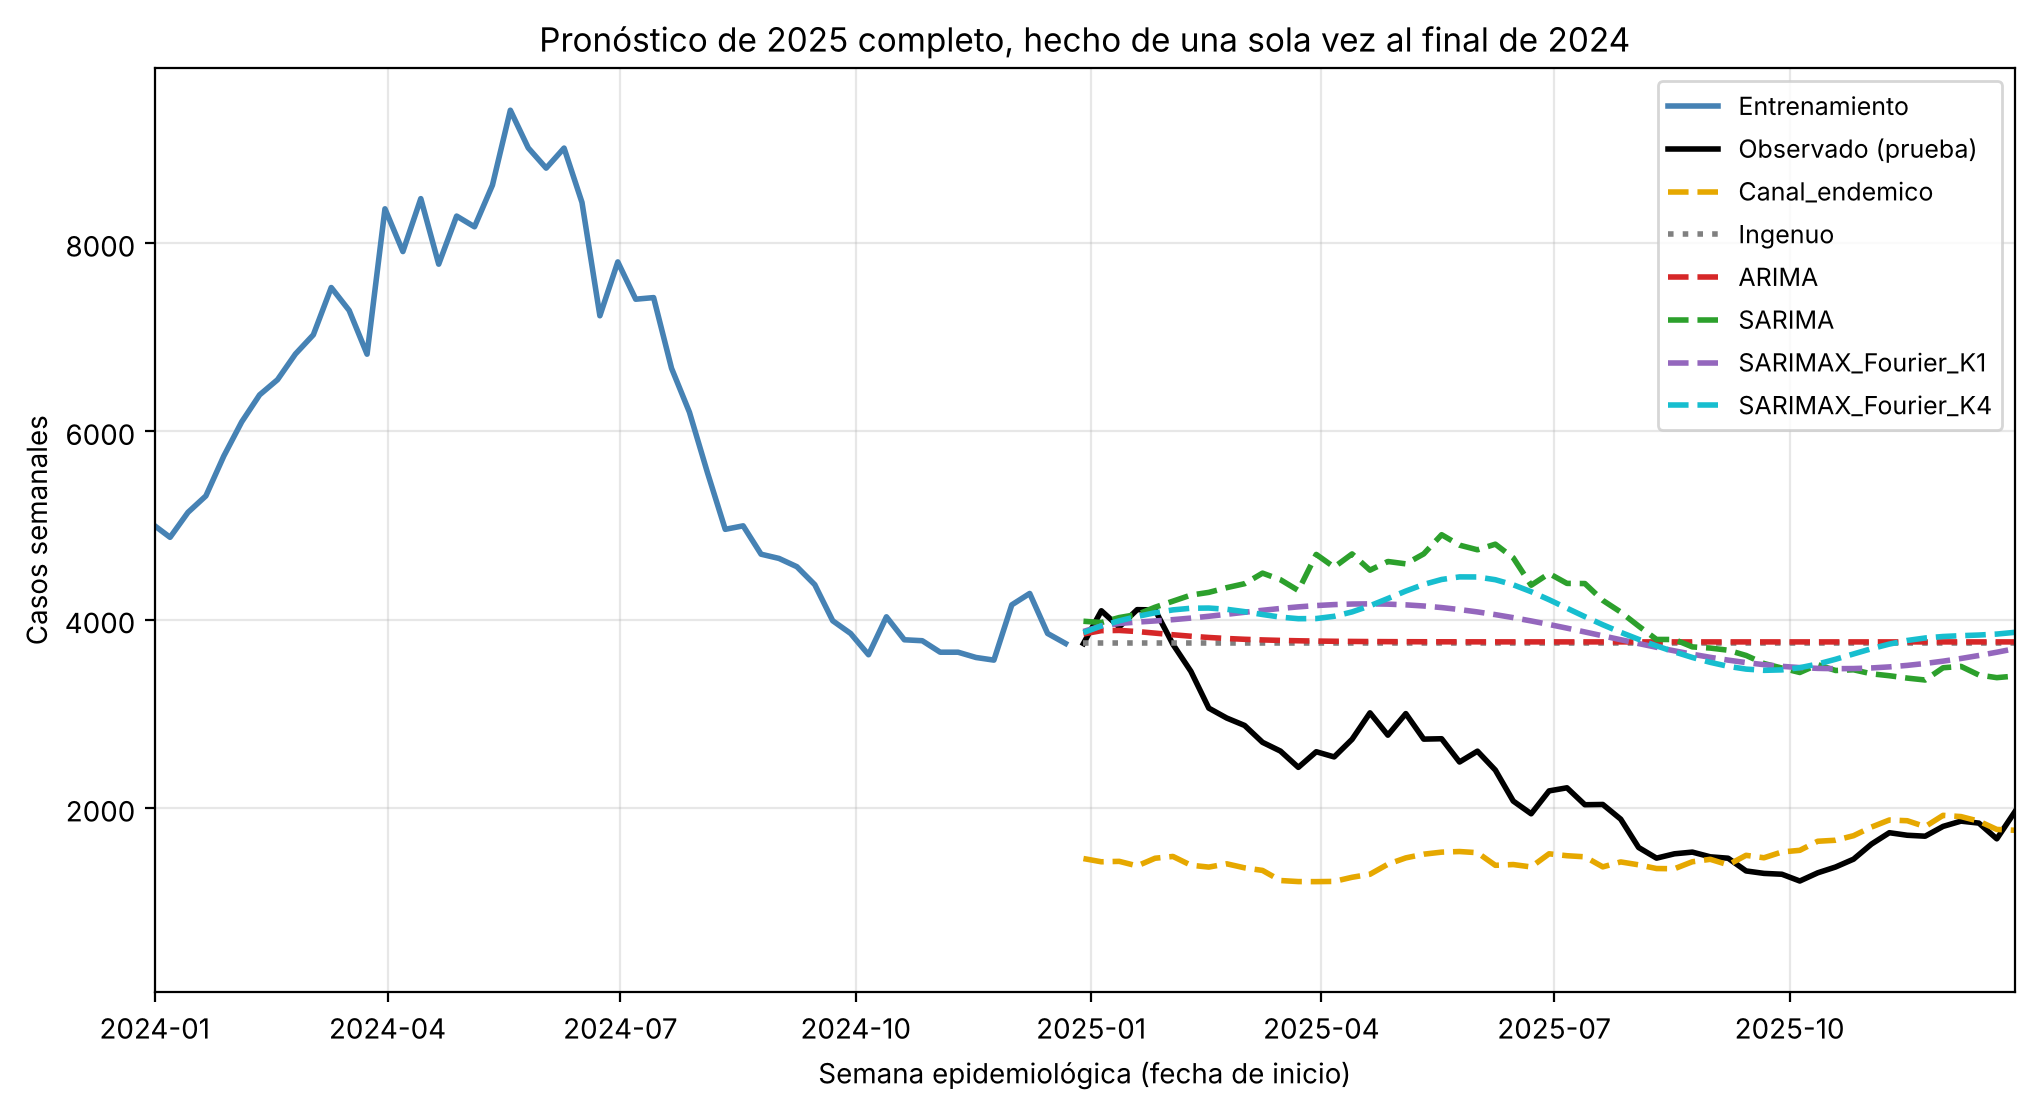

In [48]:
# Graficar resultados pronostico
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(train.index, train["casos"], label="Entrenamiento", color='steelblue', linewidth=2)
ax.plot(test.index, test["casos"], label="Observado (prueba)", color='black', linewidth=2)
for modelo, color in colores.items():
    ax.plot(pronosticos.index, pronosticos[modelo], label=modelo, color=color, linestyle=":" if modelo == "Ingenuo" else "--", linewidth=2)
ax.set_xlim(pd.Timestamp('2024-01-01'), test.index[-1])
ax.set_xlabel('Semana epidemiológica (fecha de inicio)')
ax.set_ylabel('Casos semanales')
ax.set_title('Pronóstico de 2025 completo, hecho de una sola vez al final de 2024')
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.show()

**Interpretación del gráfico**

- **ARIMA (rojo) e ingenuo (gris punteado):** el ARIMA tiene d = 1, así que su pronóstico de largo plazo **se queda cerca del último nivel observado**: entre 3 763 y 3 885 casos por semana durante todo 2025. El ingenuo repite los 3 747 casos de la última semana de 2024. Ninguno "sabe" que la serie va a volver a un nivel normal.
- **SARIMA (verde):** el MA estacional repite parte de la forma del año anterior, y como el año anterior fue la epidemia de 2024, **sube hasta 4 902 casos** a mitad de año, justo cuando los casos reales bajaban.
- **SARIMAX con Fourier (morado y azul claro):** dibujan una onda anual suave alrededor del mismo nivel, entre 3 461 y 4 454 casos. Tampoco anticipan el descenso.
- **Valor esperado del canal (amarillo):** es el nivel típico de cada semana en años no epidémicos, de 1 217 a 1 921 casos. **Queda muy por debajo en el primer semestre**, cuando todavía quedaba la cola de la epidemia (esa distancia es la señal de brote), y en el segundo semestre **coincide muy bien** con lo observado.
- Los otros dos modelos de referencia no se dibujan para no deformar la escala: el ingenuo con deriva va de 3 754 a 4 099 casos y el ingenuo estacional repite la epidemia de 2024 (hasta 9 410 casos).

In [49]:
tab_metricas = comparar_pronosticos(pronosticos, serie_train)

CAPACIDAD DE PRONÓSTICO EN LA VENTANA DE PRUEBA
                     Modelo       RMSE        MAE  MAPE (%)    MASE
Ranking                                                            
1            Canal_endemico  1207.9185   902.2670   32.5512  0.5673
2                   Ingenuo  1658.9386  1492.1509   84.2552  0.9383
3                     ARIMA  1674.5494  1505.5606   85.0349  0.9467
4        SARIMAX_Fourier_K1  1675.2828  1556.6174   84.7659  0.9788
5        SARIMAX_Fourier_K4  1777.1802  1651.1296   89.3847  1.0382
6            Ingenuo_deriva  1859.3247  1667.7805   94.2934  1.0487
7                    SARIMA  1881.3523  1760.0546   92.8576  1.1067
8        Ingenuo_estacional  4043.6615  3697.4151  174.7291  2.3249
--------------------------------------------------------------------------------
Mejor modelo (menor RMSE): Canal_endemico


In [50]:
# Error absoluto medio por semestre de 2025: ¿en qué parte del año se equivoca cada modelo?
mae_semestre = mae_por_semestre(pronosticos)
mae_semestre

,MAE SE01–SE26,MAE SE27–SE53
Canal_endemico,1588.2,241.7
Ingenuo,865.0,2096.0
Ingenuo_estacional,4333.0,3085.4
Ingenuo_deriva,947.5,2361.4
ARIMA,875.3,2112.5
SARIMA,1478.5,2031.2
SARIMAX_Fourier_K1,1121.8,1975.3
SARIMAX_Fourier_K4,1201.7,2083.9


**Interpretación**

| Herramienta | RMSE | MAE | MAPE (%) | MASE |
| :--- | :--- | :--- | :--- | :--- |
| **Valor esperado del canal** | **1 207.9** | **902.3** | **32.6** | **0.57** |
| Ingenuo | 1 658.9 | 1 492.2 | 84.3 | 0.94 |
| ARIMA(2,1,2) | 1 674.5 | 1 505.6 | 85.0 | 0.95 |
| SARIMAX(2,1,2) + Fourier K = 1 | 1 675.3 | 1 556.6 | 84.8 | 0.98 |
| SARIMAX(2,1,2) + Fourier K = 4 | 1 777.2 | 1 651.1 | 89.4 | 1.04 |
| Ingenuo con deriva | 1 859.3 | 1 667.8 | 94.3 | 1.05 |
| SARIMA(2,1,2)(0,0,1)₅₂ | 1 881.4 | 1 760.1 | 92.9 | 1.11 |
| Ingenuo estacional | 4 043.7 | 3 697.4 | 174.7 | 2.32 |

- **Cuando se pronostica todo 2025 por adelantado, "lo normal" es la mejor guía.** El valor esperado del canal tiene el menor error en las cuatro métricas (MAE 902.3). El ARIMA(2,1,2) y el ingenuo, que se quedan en el nivel de finales de 2024, se equivocan en unos 1 500 casos por semana (MAE 1 505.6 y 1 492.2).
- **Aquí se ve la complementariedad en la otra dirección:** el canal "recuerda" cuál es el nivel normal de cada semana, y un modelo con d = 1 no puede anticipar el regreso a ese nivel. A un año de distancia, el último dato ya no informa.
- **Error por semestre:**
  - El valor esperado del canal se equivoca mucho en el primer semestre (MAE 1 588.2) y muy poco en el segundo (MAE 241.7).
  - Con el ARIMA pasa lo contrario: le va mejor en el primer semestre (875.3), porque la serie todavía estaba cerca del nivel de finales de 2024, y mucho peor en el segundo (2 112.5).
- **El orden por AICc no coincide con el orden por pronóstico:** el SARIMA tenía el mejor AICc de la familia y es el que **peor pronostica** de los modelos ARIMA, porque repite la forma de la epidemia de 2024. Como en el taller, *un mejor AICc no garantiza un mejor pronóstico fuera de la muestra*.
- **Sobre la MASE:** su escala es el error del método *naive* estacional dentro del entrenamiento, que es muy grande porque incluye el salto de 2023 a la epidemia de 2024. Por eso el ARIMA tiene MASE < 1 aunque su error sea alto. Lo importante es la comparación entre herramientas.
- **Este horizonte no es el de la pregunta de pronóstico.** Nadie planea la respuesta al dengue con un pronóstico hecho en diciembre para todo el año siguiente. Se incluye porque es el horizonte en el que el canal queda fijo, y muestra para qué sirve cada herramienta: **el canal para saber qué es normal en cualquier semana del año; el ARIMA para las próximas semanas.**

#### Prueba de robustez: ¿y si se modela el logaritmo de los casos?

Todos los modelos anteriores fallan la prueba de Ljung-Box, y sus residuos son heterocedásticos (la varianza crece cuando hay más casos, sobre todo en la epidemia de 2024). Una solución habitual es modelar $\ln(casos)$. Aquí se comprueba si esa transformación cambia el resultado del pronóstico a 53 semanas. El pronóstico se devuelve a casos con $e^{\hat{y}}$.

In [51]:
# ARIMA sobre el logaritmo de los casos
log_train = np.log(serie_train)
m_log = auto_arima(log_train, seasonal=False, trace=False)
arima_log = ARIMA(log_train, order=m_log.order).fit()
print(f"Modelo seleccionado para ln(casos): ARIMA{m_log.order}")
print(acorr_ljungbox(arima_log.resid[1:], lags=[13, 26, 52], return_df=True))

pred_arima_log = np.exp(arima_log.get_forecast(steps=h).predicted_mean)
pronosticos_log = pd.DataFrame({
    "Observado" : test["casos"],
    "Canal_endemico" : pred_canal,
    "ARIMA" : pred_arima.values,
    "ARIMA_log" : pred_arima_log.values
}, index=test.index)
tab_metricas_log = comparar_pronosticos(pronosticos_log, serie_train)

Modelo seleccionado para ln(casos): ARIMA(1, 1, 2)
      lb_stat  lb_pvalue
13  16.259736   0.235388
26  36.945116   0.075608
52  93.973813   0.000326
CAPACIDAD DE PRONÓSTICO EN LA VENTANA DE PRUEBA
                 Modelo       RMSE        MAE  MAPE (%)    MASE
Ranking                                                        
1        Canal_endemico  1207.9185   902.2670   32.5512  0.5673
2             ARIMA_log  1544.2991  1383.2508   78.3966  0.8698
3                 ARIMA  1674.5494  1505.5606   85.0349  0.9467
--------------------------------------------------------------------------------
Mejor modelo (menor RMSE): Canal_endemico


**Interpretación**

- **Con logaritmo, `auto_arima` elige un ARIMA(1,1,2).** Sus residuos mejoran: Ljung-Box ya **no rechaza H0** en los rezagos 13 (p ≈ 0.24) y 26 (p ≈ 0.08), aunque sí en el 52 (p < 0.001).
- **Su pronóstico a 53 semanas mejora frente al ARIMA en niveles** (MAE 1 383.3 frente a 1 505.6), **pero sigue lejos del valor esperado del canal** (MAE 902.3).
- **Conclusión:** que el ARIMA no anticipe el año completo **no se debe a una mala especificación de los residuos**. Se debe a que, con d = 1, ningún modelo de esta familia puede anticipar que la serie volverá al nivel normal después de una epidemia. Esa información ("cuál es el nivel normal") es la que tiene el canal.

### 5.6 Evaluación con varios años de prueba (2022, 2023, 2024 y 2025)

Hasta aquí todo se evaluó en un solo año, 2025, que tiene una particularidad: viene justo después de la epidemia de 2024. Para saber si los resultados se mantienen, se repite **todo el experimento con cuatro años de prueba distintos**:

| Año de prueba | Entrenamiento de los modelos | Años del canal endémico | Tipo de año |
| :--- | :--- | :--- | :--- |
| 2022 | 2019–2021 | 2019, 2020, 2021 | Casos bajos, en lenta subida |
| 2023 | 2019–2022 | 2019, 2020, 2021, 2022 | Subida antes de la epidemia |
| 2024 | 2019–2023 | 2019, 2020, 2021, 2022, 2023 | Epidemia |
| 2025 | 2019–2024 | 2019, 2020, 2021, 2022, 2023 | Descenso después de la epidemia |

**Reglas, iguales para todos los años:**
- **Canal endémico:** se usa la regla del INS, es decir, hasta 5 años anteriores sin el año epidémico 2024. Como los datos empiezan en 2019, los canales de 2022 y 2023 solo tienen 3 y 4 años históricos.
- **Selección de los modelos:** para que ningún modelo use información del futuro, los órdenes se **vuelven a elegir en cada entrenamiento**:
  - **ARIMA:** `auto_arima` sin estacionalidad.
  - **SARIMA:** el mismo orden regular más el MA estacional (0,0,1)₅₂ del mejor SARIMA de la sección 4.3.2. Así se evita repetir la búsqueda con m = 52, que tarda varios minutos en cada año.
  - **SARIMAX:** `auto_arima` con los términos de Fourier K = 1. El modelo con K = 4 usa ese mismo orden.
- **Modelos de referencia:** ingenuo, ingenuo estacional e ingenuo con deriva, calculados solo con datos anteriores a cada pronóstico.
- **Horizontes:** 4 semanas (principal), 1 semana y año completo, este último pronosticado de una vez desde el final del entrenamiento.
- **Métricas:** RMSE, MAE, MAPE y MASE. La escala de la MASE se calcula con el entrenamiento de cada año.

Esta celda tarda unos 2 minutos.

In [52]:
def evaluar_anio_prueba(anio):
    y_tr = serie_completa[datos["ANO"] < anio]
    y_te = serie_completa[datos["ANO"] == anio]

    # Canal endemico: hasta 5 años anteriores sin el año epidemico 2024
    anios_canal = [a for a in range(2019, anio) if a != 2024][-5:]
    canal = canal_endemico(datos, anios_canal)
    pred_canal_anio = canal.loc[datos.loc[y_te.index, "SEMANA"], "Esperado"].values

    # Modelos: los ordenes se eligen con el entrenamiento de ese año
    orden_arima = auto_arima(y_tr, seasonal=False, trace=False).order
    K1 = ["sin1", "cos1"]
    K4 = [f"{f}{k}" for k in range(1, 5) for f in ["sin", "cos"]]
    orden_sarimax = auto_arima(y_tr, X=fourier.loc[y_tr.index, K1], seasonal=False, trace=False).order
    modelos = {
        "ARIMA" : (ARIMA(y_tr, order=orden_arima).fit(), None),
        "SARIMA" : (ARIMA(y_tr, order=orden_arima, seasonal_order=(0, 0, 1, 52)).fit(), None),
        "SARIMAX_Fourier_K1" : (ARIMA(y_tr, exog=fourier.loc[y_tr.index, K1], order=orden_sarimax).fit(), fourier[K1]),
        "SARIMAX_Fourier_K4" : (ARIMA(y_tr, exog=fourier.loc[y_tr.index, K4], order=orden_sarimax).fit(), fourier[K4]),
    }
    semanas_brote = int((y_te.values > canal.loc[datos.loc[y_te.index, "SEMANA"], "Limite_superior"].values).sum())
    print(f"{anio}: canal con {anios_canal} ({semanas_brote} de {len(y_te)} semanas por encima del límite superior) | "
          f"ARIMA{orden_arima} | SARIMA{orden_arima}(0,0,1)52 | SARIMAX{orden_sarimax}")

    escala_mase = np.mean(np.abs(y_tr.values[52:] - y_tr.values[:-52]))
    filas = []
    for horizonte in ["1 semana", "4 semanas", "Año completo"]:
        preds = {"Canal_endemico" : pred_canal_anio}
        # Modelos de referencia (solo usan datos anteriores a cada pronostico)
        if horizonte == "Año completo":
            ing, est, der = pronostico_ingenuos_anio(y_tr, len(y_te))
        else:
            ing, est, der = pronostico_ingenuos(serie_completa, y_te.index, int(horizonte[0]))
        preds.update({"Ingenuo" : ing, "Ingenuo_estacional" : est, "Ingenuo_deriva" : der})
        for nombre, (modelo, X) in modelos.items():
            if horizonte == "Año completo":
                f = modelo.get_forecast(steps=len(y_te)) if X is None else modelo.get_forecast(steps=len(y_te), exog=X.loc[y_te.index])
                preds[nombre] = f.predicted_mean.values
            else:
                preds[nombre] = pronostico_h_semanas(modelo, int(horizonte[0]), y_te.index, X)
        for nombre, pred in preds.items():
            error = y_te.values - pred
            filas.append({"Año de prueba": anio, "Horizonte": horizonte, "Modelo": nombre,
                          "RMSE": np.sqrt(np.mean(error**2)), "MAE": np.mean(np.abs(error)),
                          "MAPE (%)": np.mean(np.abs(error) / y_te.values) * 100,
                          "MASE": np.mean(np.abs(error)) / escala_mase})
    return filas

resultados_anios = pd.DataFrame([fila for anio in [2022, 2023, 2024, 2025] for fila in evaluar_anio_prueba(anio)]).round(2)
resultados_anios.head(10)

2022: canal con [2019, 2020, 2021] (0 de 52 semanas por encima del límite superior) | ARIMA(0, 1, 0) | SARIMA(0, 1, 0)(0,0,1)52 | SARIMAX(0, 1, 0)


2023: canal con [2019, 2020, 2021, 2022] (21 de 52 semanas por encima del límite superior) | ARIMA(0, 1, 0) | SARIMA(0, 1, 0)(0,0,1)52 | SARIMAX(0, 1, 0)


2024: canal con [2019, 2020, 2021, 2022, 2023] (52 de 52 semanas por encima del límite superior) | ARIMA(0, 1, 0) | SARIMA(0, 1, 0)(0,0,1)52 | SARIMAX(0, 1, 0)


2025: canal con [2019, 2020, 2021, 2022, 2023] (21 de 53 semanas por encima del límite superior) | ARIMA(2, 1, 2) | SARIMA(2, 1, 2)(0,0,1)52 | SARIMAX(2, 1, 2)


,Año de prueba,Horizonte,Modelo,RMSE,MAE,MAPE (%),MASE
0,2022,1 semana,Canal_endemico,363.38,278.32,26.14,0.20
1,2022,1 semana,Ingenuo,117.17,91.73,7.29,0.07
2,2022,1 semana,Ingenuo_estacional,499.73,413.98,32.27,0.30
3,2022,1 semana,Ingenuo_deriva,117.53,92.21,7.33,0.07
4,2022,1 semana,ARIMA,117.17,91.73,7.29,0.07
5,2022,1 semana,SARIMA,115.01,89.80,7.21,0.07
6,2022,1 semana,SARIMAX_Fourier_K1,119.85,96.49,7.68,0.07
7,2022,1 semana,SARIMAX_Fourier_K4,123.78,101.48,8.36,0.07
8,2022,4 semanas,Canal_endemico,363.38,278.32,26.14,0.20
9,2022,4 semanas,Ingenuo,261.08,195.65,16.21,0.14


In [53]:
# MAE y MAPE por modelo, año de prueba y horizonte
orden_modelos = ["Canal_endemico", "Ingenuo", "Ingenuo_estacional", "Ingenuo_deriva", "ARIMA", "SARIMA", "SARIMAX_Fourier_K1", "SARIMAX_Fourier_K4"]
orden_horizontes = ["4 semanas", "1 semana", "Año completo"]
for metrica in ["MAE", "MAPE (%)"]:
    for horizonte in orden_horizontes:
        tab = (resultados_anios[resultados_anios["Horizonte"] == horizonte]
               .pivot(index="Modelo", columns="Año de prueba", values=metrica).reindex(orden_modelos))
        tab["Promedio"] = tab.mean(axis=1)
        print("=" * 80)
        print(f"{metrica} - horizonte: {horizonte}")
        print("=" * 80)
        print(tab.round(1).to_string())
        print()

MAE - horizonte: 4 semanas
Año de prueba        2022    2023    2024    2025  Promedio
Modelo                                                     
Canal_endemico      278.3  1139.0  4524.8   902.3    1711.1
Ingenuo             195.6   261.3   818.5   332.1     401.9
Ingenuo_estacional  414.0  1175.6  3615.6  3673.4    2219.7
Ingenuo_deriva      198.7   255.4   817.1   338.0     402.3
ARIMA               195.6   261.3   818.5   350.6     406.5
SARIMA              192.7   247.7   827.0   368.3     409.0
SARIMAX_Fourier_K1  211.3   255.8   850.6   353.4     417.8
SARIMAX_Fourier_K4  215.4   263.2   848.6   339.9     416.8

MAE - horizonte: 1 semana
Año de prueba        2022    2023    2024    2025  Promedio
Modelo                                                     
Canal_endemico      278.3  1139.0  4524.8   902.3    1711.1
Ingenuo              91.7   143.7   364.1   140.0     184.9
Ingenuo_estacional  414.0  1175.6  3615.6  3673.4    2219.7
Ingenuo_deriva       92.2   143.0   365.7   14

In [54]:
# Mejor modelo (menor RMSE, como en el taller) en cada año y horizonte. Si hay empate se muestran todos los empatados.
def modelos_con_menor_rmse(grupo):
    return " = ".join(grupo.loc[grupo["RMSE"] == grupo["RMSE"].min(), "Modelo"])

ganadores = (resultados_anios.groupby(["Horizonte", "Año de prueba"])[["Modelo", "RMSE"]].apply(modelos_con_menor_rmse)
             .unstack("Año de prueba").reindex(orden_horizontes))
print("=" * 100)
print("MEJOR MODELO (menor RMSE) POR AÑO DE PRUEBA Y HORIZONTE")
print("=" * 100)
print(ganadores.to_string())
print("=" * 100)

# ¿Cuantas veces menor es el error (MAE) del ARIMA y del ingenuo frente al valor esperado del canal?
def razon_mae(modelo):
    canal = resultados_anios[resultados_anios["Modelo"] == "Canal_endemico"].pivot(index="Horizonte", columns="Año de prueba", values="MAE")
    mod = resultados_anios[resultados_anios["Modelo"] == modelo].pivot(index="Horizonte", columns="Año de prueba", values="MAE")
    return (canal / mod).reindex(orden_horizontes).round(1)

print("\nMAE del canal dividido entre el MAE del ARIMA (valores mayores que 1: el ARIMA se equivoca menos)")
print(razon_mae("ARIMA").to_string())
print("\nMAE del canal dividido entre el MAE del ingenuo (valores mayores que 1: el ingenuo se equivoca menos)")
print(razon_mae("Ingenuo").to_string())

# Resumen por horizonte: años en que cada modelo tiene menor RMSE que el canal, y MAE promedio de los 4 años
filas = []
for horizonte in orden_horizontes:
    r = resultados_anios[resultados_anios["Horizonte"] == horizonte].pivot(index="Año de prueba", columns="Modelo", values="RMSE")
    m = resultados_anios[resultados_anios["Horizonte"] == horizonte].pivot(index="Año de prueba", columns="Modelo", values="MAE")
    filas.append({"Horizonte": horizonte,
                  "Años en que el ARIMA supera al canal": f"{int((r['ARIMA'] < r['Canal_endemico']).sum())} de {len(r)}",
                  "Años en que el ARIMA supera al ingenuo": f"{int((r['ARIMA'] < r['Ingenuo']).sum())} de {len(r)}",
                  "Años en que ARIMA e ingenuo empatan": f"{int((r['ARIMA'] == r['Ingenuo']).sum())} de {len(r)}",
                  "MAE promedio ARIMA": round(m["ARIMA"].mean(), 1), "MAE promedio ingenuo": round(m["Ingenuo"].mean(), 1),
                  "MAE promedio canal": round(m["Canal_endemico"].mean(), 1)})
print("\nRESUMEN POR HORIZONTE (4 años de prueba)")
print(pd.DataFrame(filas).set_index("Horizonte").T.to_string())

MEJOR MODELO (menor RMSE) POR AÑO DE PRUEBA Y HORIZONTE
Año de prueba    2022             2023             2024            2025
Horizonte                                                              
4 semanas      SARIMA           SARIMA  Ingenuo = ARIMA         Ingenuo
1 semana       SARIMA           SARIMA           SARIMA         Ingenuo
Año completo   SARIMA  Ingenuo = ARIMA   Ingenuo_deriva  Canal_endemico

MAE del canal dividido entre el MAE del ARIMA (valores mayores que 1: el ARIMA se equivoca menos)
Año de prueba  2022  2023  2024  2025
Horizonte                            
4 semanas       1.4   4.4   5.5   2.6
1 semana        3.0   7.9  12.4   6.3
Año completo    1.1   1.3   2.3   0.6

MAE del canal dividido entre el MAE del ingenuo (valores mayores que 1: el ingenuo se equivoca menos)
Año de prueba  2022  2023  2024  2025
Horizonte                            
4 semanas       1.4   4.4   5.5   2.7
1 semana        3.0   7.9  12.4   6.4
Año completo    1.1   1.3   2.3   0.6

R

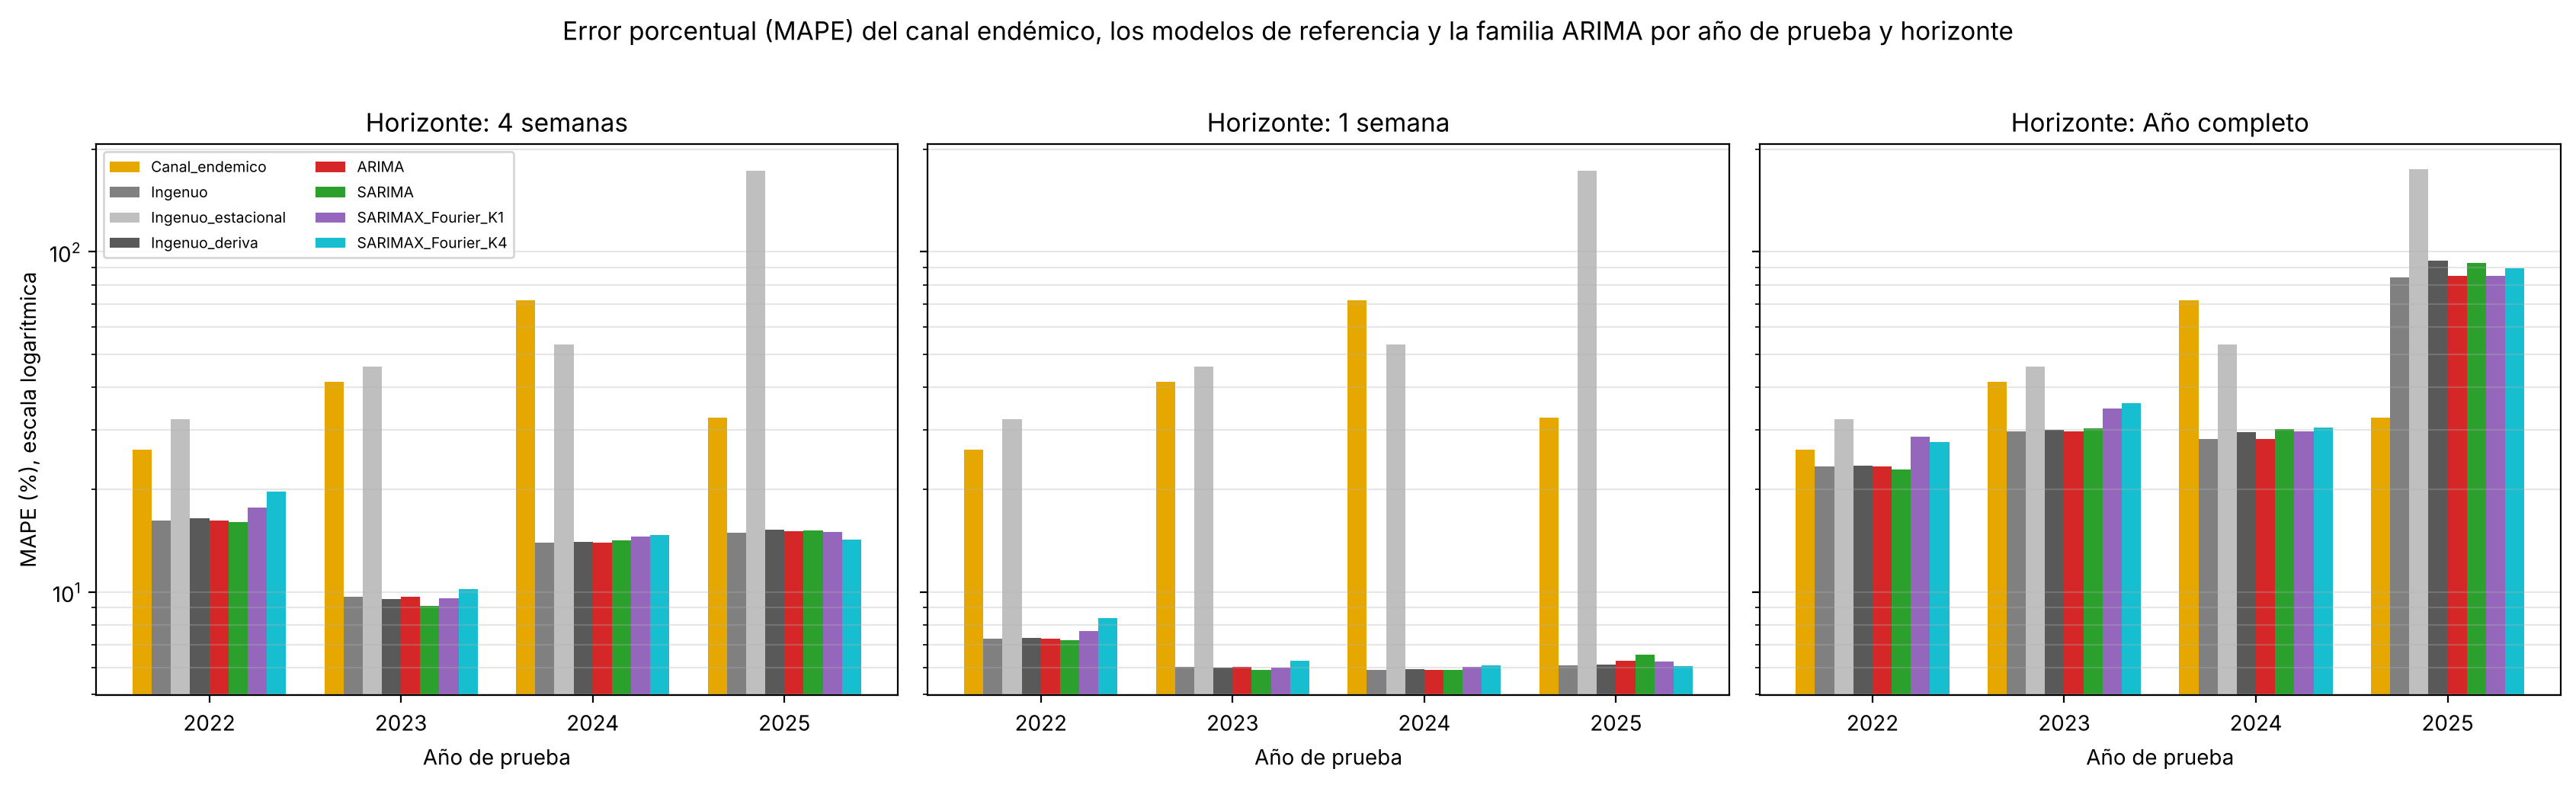

In [55]:
# MAPE por año y horizonte (el MAPE permite comparar años con niveles de casos muy distintos)
colores_modelos = {"Canal_endemico": "#E6A800", "Ingenuo": "grey", "Ingenuo_estacional": "#BFBFBF", "Ingenuo_deriva": "#595959",
                   "ARIMA": "#d62728", "SARIMA": "#2ca02c", "SARIMAX_Fourier_K1": "#9467bd", "SARIMAX_Fourier_K4": "#17becf"}
anios_prueba = [2022, 2023, 2024, 2025]
ancho = 0.1
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for ax, horizonte in zip(axes, orden_horizontes):
    tab = resultados_anios[resultados_anios["Horizonte"] == horizonte].pivot(index="Año de prueba", columns="Modelo", values="MAPE (%)")
    for i, modelo in enumerate(orden_modelos):
        ax.bar(np.arange(len(anios_prueba)) + (i - 3.5) * ancho, tab.loc[anios_prueba, modelo], width=ancho,
               color=colores_modelos[modelo], label=modelo)
    ax.set_yscale("log")
    ax.set_xticks(np.arange(len(anios_prueba)))
    ax.set_xticklabels(anios_prueba)
    ax.set_title(f"Horizonte: {horizonte}")
    ax.set_xlabel("Año de prueba")
    ax.grid(True, axis="y", which="both", alpha=0.3)
axes[0].set_ylabel("MAPE (%), escala logarítmica")
axes[0].legend(fontsize=7, loc="upper left", ncol=2)
fig.suptitle("Error porcentual (MAPE) del canal endémico, los modelos de referencia y la familia ARIMA por año de prueba y horizonte", y=1.02)
plt.tight_layout()
plt.show()

**Interpretación**

**Horizonte principal (4 semanas) y 1 semana: usar los casos recientes anticipa mejor que "lo normal" en los cuatro años.**
- **A 4 semanas:** el MAPE del ARIMA es 16.2 %, 9.7 %, 14.0 % y 15.1 % (2022 a 2025). El del valor esperado del canal es 26.1 %, 41.4 %, 71.9 % y 32.6 %. El MAE del canal es entre 1.4 y 5.5 veces el del ARIMA, según el año.
- **A 1 semana:** el MAPE del ARIMA está entre 5.9 % y 7.3 %, y el MAE del canal es entre 3.0 y 12.4 veces el del ARIMA.
- **En promedio de los cuatro años,** el MAE del ARIMA es de 406.5 casos a 4 semanas y 185.9 a 1 semana, frente a 1 711.1 del canal.
- La ventaja es mayor justo cuando el año se aleja de lo normal: en la epidemia de 2024 (5.5 veces a 4 semanas) más que en 2022, un año de casos bajos (1.4 veces).

**Año completo: el ARIMA tiene menor error que el canal en 3 de los 4 años.**
- El canal solo tiene menor error en 2025, el único año en que los casos **vuelven** al nivel histórico después de una epidemia. En los años de subida (2023) y de epidemia (2024), seguir el nivel reciente se acerca más que el promedio histórico.

**El ARIMA frente al modelo ingenuo: empatan o gana el ingenuo.**
- Con los entrenamientos de 2022, 2023 y 2024, `auto_arima` eligió un **ARIMA(0,1,0)**, que es exactamente el modelo ingenuo: por eso el ARIMA y el ingenuo **empatan en 3 de los 4 años** en los tres horizontes.
- En 2025, el ARIMA(2,1,2) no supera al ingenuo en ningún horizonte.
- El MAE promedio de los dos es casi igual: 406.5 y 401.9 a 4 semanas, 185.9 y 184.9 a 1 semana.
- **Lectura:** en esta serie, el mejor pronóstico de corto plazo es muy simple (los casos seguirán cerca del último nivel observado), y los términos AR, MA, estacionales o de Fourier aportan poco.

**Mejor modelo en cada una de las 12 combinaciones de año y horizonte (menor RMSE):**
- **SARIMA en 6:** en 2022–2024 es un ARIMA(0,1,0) con un término MA estacional, es decir, el ingenuo con una pequeña corrección.
- **Ingenuo en 4** (en 2 de ellas empatado con el ARIMA) **e ingenuo con deriva en 1.**
- **Valor esperado del canal en 1:** el año completo de 2025.
- Es decir, en **11 de las 12 combinaciones** el menor error lo tiene una herramienta que usa los casos recientes, y solo en 1 lo tiene "lo normal".

**El ingenuo estacional es casi siempre el peor** (MAPE entre 32.3 % y 173.5 % a 4 semanas). Confirma que la serie no tiene una estacionalidad anual estable: lo que pasó hace un año no ayuda a saber qué pasará ahora.

**En qué falla cada herramienta y cómo la cubre la otra**

| Año | Lo que hizo el canal (vigilancia) | Lo que hizo el ARIMA (pronóstico a 4 semanas) |
| :--- | :--- | :--- |
| 2022 | 0 de 52 semanas en brote: año normal | MAPE 16.2 %; la ventaja sobre "lo normal" es pequeña |
| 2023 | 21 de 52 semanas en brote: **aviso de la epidemia que venía** | MAPE 9.7 %: siguió la subida |
| 2024 | **52 de 52 semanas en brote: detectó la epidemia completa.** Como pronóstico, su valor esperado tuvo un MAPE de 71.9 % | MAPE 14.0 %: siguió el nivel epidémico, **pero por sí solo no habría dicho que esos niveles eran anormales** |
| 2025 | 21 de 53 semanas en brote (la cola de la epidemia) y regreso a lo esperado al final | MAPE 15.1 %; en el año completo no anticipó el regreso a lo normal |

- **El error grande del canal en 2024 no es una falla de la vigilancia: es la señal de alarma.** Su trabajo era mostrar que los casos estaban muy por encima de lo normal, y lo hizo en las 52 semanas.
- **El error pequeño del ARIMA en 2024 tampoco es toda la historia:** un pronóstico de 8 000 casos no dice si 8 000 es mucho o poco. Esa lectura la da el canal.

**Otros detalles a tener en cuenta**
- **Canales de 2022 y 2023:** se construyeron con solo 3 y 4 años históricos, porque los datos empiezan en 2019. El INS usa 5.
- **No todos los modelos de la familia son mejores que "lo normal" a un año:** en 2022, a año completo, los SARIMAX con Fourier (MAE 341.1 y 317.1) quedaron por encima del valor esperado del canal (278.3).

### 5.7 Selección del modelo final

**Regla de selección:** el modelo final es el de **menor RMSE en el periodo de prueba (2025) al horizonte principal h = 4 semanas**, comparando los modelos de la familia ARIMA con los modelos de referencia y con el valor esperado del canal. Es la misma regla del taller (menor RMSE), aplicada al horizonte de la pregunta de pronóstico.

In [56]:
# Seleccion del modelo final: menor RMSE en el periodo de prueba (2025) al horizonte principal h = 4 semanas
tab_seleccion = tab_metricas_4sem.copy()
tab_seleccion["RMSE frente al mejor (%)"] = ((tab_seleccion["RMSE"] / tab_seleccion["RMSE"].iloc[0] - 1) * 100).round(1)
nombre_final = tab_seleccion.iloc[0]["Modelo"]

print("=" * 90)
print("SELECCIÓN DEL MODELO FINAL (prueba 2025, h = 4 semanas)")
print("=" * 90)
print(tab_seleccion.to_string())
print("-" * 90)
print(f"Modelo seleccionado (menor RMSE a h = 4): {nombre_final}")
print("=" * 90)

# RMSE a 4 semanas en los cuatro años de prueba (para ver si la seleccion se sostiene fuera de 2025)
rmse_4sem_anios = (resultados_anios[resultados_anios["Horizonte"] == "4 semanas"]
                   .pivot(index="Modelo", columns="Año de prueba", values="RMSE").reindex(orden_modelos))
rmse_4sem_anios["Promedio"] = rmse_4sem_anios.mean(axis=1)
print("\nRMSE a 4 semanas por año de prueba")
print(rmse_4sem_anios.round(1).to_string())

SELECCIÓN DEL MODELO FINAL (prueba 2025, h = 4 semanas)
                     Modelo       RMSE        MAE  MAPE (%)    MASE  RMSE frente al mejor (%)
Ranking                                                                                      
1                   Ingenuo   415.0497   332.0566   14.9735  0.2088                       0.0
2            Ingenuo_deriva   423.9733   337.9961   15.2103  0.2125                       2.2
3                     ARIMA   445.8380   350.5519   15.1101  0.2204                       7.4
4        SARIMAX_Fourier_K4   448.7013   339.8566   14.2422  0.2137                       8.1
5        SARIMAX_Fourier_K1   449.3895   353.3561   15.0438  0.2222                       8.3
6                    SARIMA   486.1229   368.3290   15.1403  0.2316                      17.1
7            Canal_endemico  1207.9185   902.2670   32.5512  0.5673                     191.0
8        Ingenuo_estacional  4029.2572  3673.4340  173.5037  2.3099                     870.8
----

In [57]:
# El modelo ingenuo (ultimo valor) es exactamente un ARIMA(0,1,0): una caminata aleatoria sin parametros AR ni MA
arima010 = ARIMA(serie_train, order=(0, 1, 0)).fit()
iguales = np.allclose(pronostico_h_semanas(arima010, 4, test.index), pronosticos_4sem["Ingenuo"].values)
print(f"¿El pronóstico a 4 semanas del ARIMA(0,1,0) es idéntico al del modelo ingenuo? {'Sí' if iguales else 'No'}\n")

# Ajuste dentro de la muestra del ARIMA(0,1,0) frente al mejor ARIMA por AICc
comparar_modelos_arima({"ARIMA(0,1,0)": arima010, f"ARIMA{mejor_arima.model.order}": mejor_arima})

¿El pronóstico a 4 semanas del ARIMA(0,1,0) es idéntico al del modelo ingenuo? Sí

COMPARACIÓN DE MODELOS ARIMA
                 Modelo                  Orden          AIC         AICc          BIC      Log-Lik           MSE        RMSE         MAE  Params  Obs
Ranking                                                                                                                                              
1        ARIMA(2, 1, 2)  (2, 1, 2)(0, 0, 0, 0)  4284.736542  4284.932620  4303.451558 -2137.368271  60969.342187  246.919708  151.922341       5  313
2          ARIMA(0,1,0)  (0, 1, 0)(0, 0, 0, 0)  4308.710421  4308.723324  4312.453424 -2153.355210  66654.476038  258.175282  156.086262       1  313
----------------------------------------------------------------------------------------------------
Mejor modelo (menor AICc): ARIMA(2, 1, 2)  →  AICc: 4284.932620248531


**Interpretación**

- **El menor RMSE a h = 4 semanas en 2025 lo tiene el modelo ingenuo (415.0).** Le siguen el ingenuo con deriva (424.0, 2.2 % más), el ARIMA(2,1,2) (445.8, 7.4 % más), los SARIMAX con Fourier (448.7 y 449.4) y el SARIMA (486.1, 17.1 % más). El valor esperado del canal queda en 1 207.9 (191.0 % más) y el ingenuo estacional en 4 029.3.
- **El modelo ingenuo es exactamente un ARIMA(0,1,0)**, como comprueba la celda anterior: una caminata aleatoria, el miembro más simple de la familia ARIMA. Su pronóstico es "los casos seguirán en el último nivel observado".
- **Modelo final: ARIMA(0,1,0).** Se selecciona por tres razones:
  - **Desempeño:** tiene el menor RMSE y el menor MAE en la prueba al horizonte principal.
  - **Se sostiene en los otros años:** su RMSE promedio a 4 semanas en los cuatro años de prueba es el más bajo (507.1, frente a 514.8 del ARIMA y 520.9 del SARIMA). Además, es el mismo modelo que `auto_arima` eligió con los entrenamientos de 2022, 2023 y 2024.
  - **Parsimonia:** no tiene parámetros AR ni MA que estimar.
- **Otra vez, el AICc y el pronóstico no coinciden:** dentro del entrenamiento el ARIMA(2,1,2) ajusta mejor (AICc 4 284.9 frente a 4 308.7), pero fuera de la muestra el ARIMA(0,1,0) pronostica mejor a 4 semanas. Los términos AR y MA adicionales describen bien el pasado, pero no mejoran el pronóstico.
- **Qué significa este resultado:**
  - Las diferencias entre los modelos de la familia ARIMA y los ingenuos son pequeñas (hasta 17.1 % en RMSE) frente a la distancia con el valor esperado del canal (191.0 %). **Lo que aporta el pronóstico de corto plazo es usar el dato más reciente**, y eso es justo lo que el canal, por diseño, no hace.
  - Es una buena noticia para el uso práctico: el complemento del canal puede ser un modelo muy simple, fácil de calcular y de explicar en un boletín.
  - El ARIMA(2,1,2), el mejor por AICc, se mantiene como **contraste** en la sección 5.8.

### 5.8 Pronóstico de 2026-SE01 a 2026-SE04 y su lectura sobre el canal endémico de 2026

Con el modelo seleccionado se hace lo que se haría en la práctica:

1. **Se reestima con toda la serie** (2019-SE01 a 2025-SE53), para aprovechar también los datos de 2025. El orden del modelo no cambia: es el que se seleccionó con la prueba.
2. **Se pronostican las 4 semanas siguientes** (2026-SE01 a 2026-SE04) con intervalos del 80 % y del 95 %.
3. Se calculan también los intervalos con la **varianza condicional del GARCH(1,1)**. Si $\hat\sigma^2_{T+i}$ es la varianza que el GARCH pronostica para la semana $i$ y $\psi_j$ son los pesos del modelo ARIMA, el error estándar del pronóstico a $k$ semanas es
$$ EE_k = \sqrt{\sum_{j=0}^{k-1} \psi_j^2\, \hat\sigma^2_{T+k-j}} $$
4. **Se ubica el pronóstico sobre el canal endémico de 2026**, el que se replicó en la sección 4.1.2 con los años 2020–2023 y 2025, y se indica en qué zona caería cada semana.

Este último paso es la demostración central de la complementariedad: **el ARIMA da el número de casos esperados y el canal dice si esa cantidad es normal o preocupante.**

In [58]:
# Reestimar el modelo seleccionado con TODA la serie (2019-SE01 a 2025-SE53)
especificaciones = {
    "Ingenuo" : dict(order=(0, 1, 0)),
    "Ingenuo_deriva" : dict(order=(0, 1, 0), trend="t"),
    "ARIMA" : dict(order=mejor_arima.model.order),
    "SARIMA" : dict(order=mejor_sarima.model.order, seasonal_order=mejor_sarima.model.seasonal_order),
}
modelo_final = ARIMA(serie_completa, **especificaciones[nombre_final]).fit()
print(f"Modelo final: {nombre_final} -> ARIMA{modelo_final.model.order}, reestimado con {int(modelo_final.nobs)} semanas")
print(modelo_final.summary())

Modelo final: Ingenuo -> ARIMA(0, 1, 0), reestimado con 366 semanas
                               SARIMAX Results                                
Dep. Variable:                  casos   No. Observations:                  366
Model:                 ARIMA(0, 1, 0)   Log Likelihood               -2506.398
Date:                Thu, 19 Nov 2026   AIC                           5014.797
Time:                        19:07:46   BIC                           5018.697
Sample:                    12-30-2018   HQIC                          5016.346
                         - 12-28-2025                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2      5.395e+04   1735.517     31.086      0.000    5.05e+04    5.74e+04
Ljung-Box (L1) (Q):                   0.58   Jarque-Bera (JB): 

In [59]:
# Pronostico de las 4 semanas siguientes: 2026-SE01 a 2026-SE04, con intervalos del 80 % y del 95 %
h_final = 4
pron_final = modelo_final.get_forecast(steps=h_final)
ic80 = pron_final.conf_int(alpha=0.20)
ic95 = pron_final.conf_int(alpha=0.05)

tab_pronostico = pd.DataFrame({
    "Semana": [f"2026-SE{s:02d}" for s in range(1, h_final + 1)],
    "Pronóstico": pron_final.predicted_mean.values,
    "Error estándar": pron_final.se_mean.values,
    "LI 80%": ic80.iloc[:, 0].values, "LS 80%": ic80.iloc[:, 1].values,
    "LI 95%": ic95.iloc[:, 0].values, "LS 95%": ic95.iloc[:, 1].values,
}, index=pron_final.predicted_mean.index)
tab_pronostico.index.name = "Inicio de la semana"

print(f"Última semana observada: {int(datos['ANO'].iloc[-1])}-SE{int(datos['SEMANA'].iloc[-1]):02d} ({datos.index[-1].date()}), {serie_completa.iloc[-1]:.0f} casos")
print(f"Inicio de la semana epidemiológica 1 de 2026: {inicio_anio_epidemiologico(2026).date()}\n")
print("=" * 100)
print("PRONÓSTICO 2026-SE01 A 2026-SE04 (casos notificados por semana)")
print("=" * 100)
print(tab_pronostico.round(0).to_string())
print("=" * 100)

# Contraste: el mejor ARIMA por AICc, tambien reestimado con toda la serie
modelo_contraste = ARIMA(serie_completa, order=mejor_arima.model.order).fit()
pron_contraste = modelo_contraste.get_forecast(steps=h_final)
tab_contraste = pd.DataFrame({
    "Semana": tab_pronostico["Semana"].values,
    f"Modelo final ARIMA{modelo_final.model.order}": pron_final.predicted_mean.values,
    f"Contraste ARIMA{modelo_contraste.model.order}": pron_contraste.predicted_mean.values,
})
tab_contraste["Diferencia"] = tab_contraste.iloc[:, 2] - tab_contraste.iloc[:, 1]
print(f"\nContraste con el ARIMA{modelo_contraste.model.order} reestimado con toda la serie")
print(tab_contraste.round(0).to_string(index=False))

Última semana observada: 2025-SE53 (2025-12-28), 1957 casos
Inicio de la semana epidemiológica 1 de 2026: 2026-01-04

PRONÓSTICO 2026-SE01 A 2026-SE04 (casos notificados por semana)
                        Semana  Pronóstico  Error estándar  LI 80%  LS 80%  LI 95%  LS 95%
Inicio de la semana                                                                       
2026-01-04           2026-SE01      1957.0           232.0  1659.0  2255.0  1502.0  2412.0
2026-01-11           2026-SE02      1957.0           328.0  1536.0  2378.0  1313.0  2601.0
2026-01-18           2026-SE03      1957.0           402.0  1441.0  2473.0  1168.0  2746.0
2026-01-25           2026-SE04      1957.0           465.0  1362.0  2552.0  1047.0  2867.0



Contraste con el ARIMA(2, 1, 2) reestimado con toda la serie
   Semana  Modelo final ARIMA(0, 1, 0)  Contraste ARIMA(2, 1, 2)  Diferencia
2026-SE01                       1957.0                    1883.0       -74.0
2026-SE02                       1957.0                    1805.0      -152.0
2026-SE03                       1957.0                    1727.0      -230.0
2026-SE04                       1957.0                    1655.0      -302.0


In [60]:
# Intervalos con varianza condicional: GARCH(1,1) sobre los residuos del modelo final (toda la serie)
garch_final = arch_model(modelo_final.resid[1:], mean="Zero", vol="GARCH", p=1, q=1, rescale=False).fit(disp="off")
var_futura = garch_final.forecast(horizon=h_final).variance.iloc[-1].values      # varianza pronosticada para cada una de las 4 semanas

# Pesos psi del modelo: cuanto pesa en el pronostico a k semanas el error de cada semana intermedia
psi = np.asarray(modelo_final.impulse_responses(steps=h_final - 1)).ravel()
ee_garch = np.array([np.sqrt(np.sum(psi[:k]**2 * var_futura[:k][::-1])) for k in range(1, h_final + 1)])

z80, z95 = stats.norm.ppf(0.90), stats.norm.ppf(0.975)
tab_garch_final = pd.DataFrame({
    "Semana": tab_pronostico["Semana"].values,
    "Pronóstico": pron_final.predicted_mean.values,
    "Error estándar (varianza constante)": pron_final.se_mean.values,
    "Error estándar (GARCH)": ee_garch,
    "LI 80% GARCH": pron_final.predicted_mean.values - z80 * ee_garch, "LS 80% GARCH": pron_final.predicted_mean.values + z80 * ee_garch,
    "LI 95% GARCH": pron_final.predicted_mean.values - z95 * ee_garch, "LS 95% GARCH": pron_final.predicted_mean.values + z95 * ee_garch,
})
print(f"GARCH(1,1) del modelo final: omega = {garch_final.params['omega']:.2f}, alpha = {garch_final.params['alpha[1]']:.4f}, beta = {garch_final.params['beta[1]']:.4f}")
print(f"Desviación estándar constante del modelo final: {np.sqrt(modelo_final.params['sigma2']):.1f} casos")
print(f"Volatilidad condicional en la última semana observada: {garch_final.conditional_volatility.iloc[-1]:.1f} casos")
print(f"Volatilidad condicional media en 2024: {garch_final.conditional_volatility[datos['ANO'].reindex(garch_final.conditional_volatility.index) == 2024].mean():.1f} casos; "
      f"en 2025: {garch_final.conditional_volatility[datos['ANO'].reindex(garch_final.conditional_volatility.index) == 2025].mean():.1f} casos\n")
print(tab_garch_final.round(0).to_string(index=False))

GARCH(1,1) del modelo final: omega = 349.73, alpha = 0.2010, beta = 0.7990
Desviación estándar constante del modelo final: 232.3 casos
Volatilidad condicional en la última semana observada: 110.0 casos
Volatilidad condicional media en 2024: 440.2 casos; en 2025: 186.0 casos

   Semana  Pronóstico  Error estándar (varianza constante)  Error estándar (GARCH)  LI 80% GARCH  LS 80% GARCH  LI 95% GARCH  LS 95% GARCH
2026-SE01      1957.0                                232.0                   162.0        1749.0        2165.0        1639.0        2275.0
2026-SE02      1957.0                                328.0                   230.0        1662.0        2252.0        1506.0        2408.0
2026-SE03      1957.0                                402.0                   283.0        1594.0        2320.0        1402.0        2512.0
2026-SE04      1957.0                                465.0                   328.0        1537.0        2377.0        1315.0        2599.0


In [61]:
# Ubicar el pronostico sobre el canal endemico de 2026 (el replicado con los años 2020-2023 y 2025)
canal_sem = canal_2026.loc[1:h_final]
tab_zonas_2026 = pd.DataFrame({
    "Semana": tab_pronostico["Semana"].values,
    "Límite inferior canal": canal_sem["Limite_inferior"].values,
    "Valor esperado canal": canal_sem["Esperado"].values,
    "Límite superior canal": canal_sem["Limite_superior"].values,
    "Pronóstico": tab_pronostico["Pronóstico"].values,
    "Pronóstico / esperado": tab_pronostico["Pronóstico"].values / canal_sem["Esperado"].values,
})
for columna in ["Pronóstico", "LI 80%", "LS 80%", "LI 95%", "LS 95%"]:
    tab_zonas_2026[f"Zona ({columna})"] = [clasificar_zona(valor, canal_sem.loc[s]) for valor, s in zip(tab_pronostico[columna].values, canal_sem.index)]

print("=" * 100)
print("PRONÓSTICO 2026-SE01 A SE04 SOBRE EL CANAL ENDÉMICO DE 2026")
print("=" * 100)
print(tab_zonas_2026.iloc[:, :6].round({"Límite inferior canal": 0, "Valor esperado canal": 0, "Límite superior canal": 0, "Pronóstico": 0, "Pronóstico / esperado": 2}).to_string(index=False))
print()
print(tab_zonas_2026[["Semana"] + [c for c in tab_zonas_2026.columns if c.startswith("Zona")]].to_string(index=False))
print("=" * 100)

PRONÓSTICO 2026-SE01 A SE04 SOBRE EL CANAL ENDÉMICO DE 2026
   Semana  Límite inferior canal  Valor esperado canal  Límite superior canal  Pronóstico  Pronóstico / esperado
2026-SE01                   80.0                1718.0                 3355.0      1957.0                   1.14
2026-SE02                    0.0                1707.0                 3607.0      1957.0                   1.15
2026-SE03                    0.0                1703.0                 3597.0      1957.0                   1.15
2026-SE04                    0.0                1653.0                 3599.0      1957.0                   1.18

   Semana Zona (Pronóstico)         Zona (LI 80%) Zona (LS 80%)         Zona (LI 95%) Zona (LS 95%)
2026-SE01            Alerta Dentro de lo esperado        Alerta Dentro de lo esperado        Alerta
2026-SE02            Alerta Dentro de lo esperado        Alerta Dentro de lo esperado        Alerta
2026-SE03            Alerta Dentro de lo esperado        Alerta Dentro de 

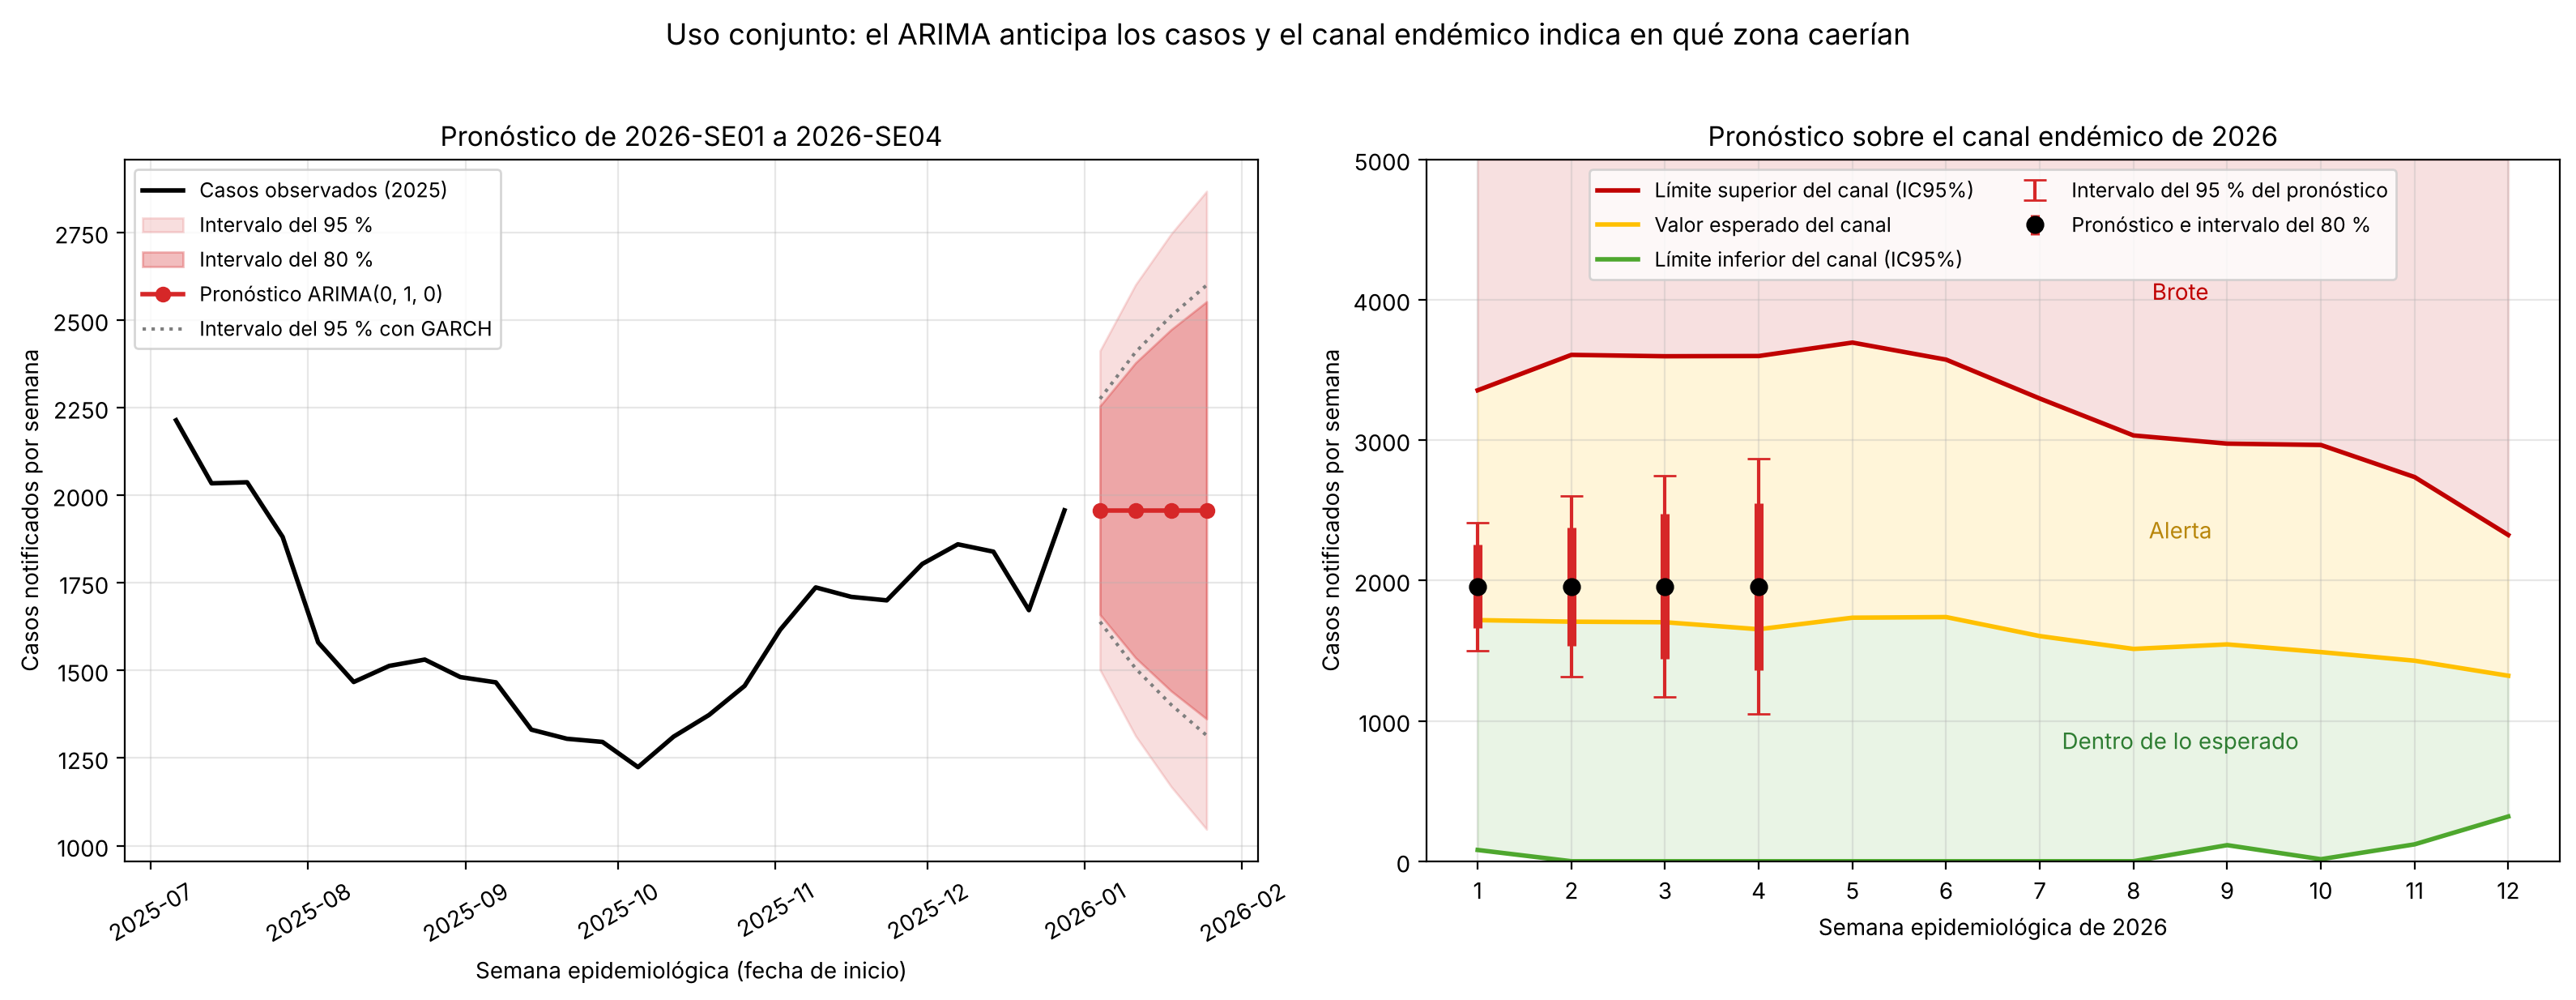

In [62]:
# Grafico: (izquierda) ultimas semanas observadas y pronostico; (derecha) pronostico sobre el canal endemico de 2026
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]
ultimas = serie_completa.iloc[-26:]
fechas_pron = tab_pronostico.index
ax.plot(ultimas.index, ultimas, color="black", linewidth=2, label="Casos observados (2025)")
ax.fill_between(fechas_pron, tab_pronostico["LI 95%"], tab_pronostico["LS 95%"], color="#d62728", alpha=0.15, label="Intervalo del 95 %")
ax.fill_between(fechas_pron, tab_pronostico["LI 80%"], tab_pronostico["LS 80%"], color="#d62728", alpha=0.30, label="Intervalo del 80 %")
ax.plot(fechas_pron, tab_pronostico["Pronóstico"], color="#d62728", marker="o", linewidth=2, label=f"Pronóstico ARIMA{modelo_final.model.order}")
ax.plot(fechas_pron, tab_garch_final["LI 95% GARCH"], color="#7F7F7F", linestyle=":", linewidth=1.5, label="Intervalo del 95 % con GARCH")
ax.plot(fechas_pron, tab_garch_final["LS 95% GARCH"], color="#7F7F7F", linestyle=":", linewidth=1.5)
ax.set_xlabel("Semana epidemiológica (fecha de inicio)")
ax.set_ylabel("Casos notificados por semana")
ax.set_title("Pronóstico de 2026-SE01 a 2026-SE04")
ax.legend(fontsize=9, loc="upper left")
ax.grid(True, alpha=0.3)
ax.tick_params(axis="x", rotation=30)

ax = axes[1]
sem = canal_2026.index[:12]
ax.fill_between(sem, canal_2026.loc[sem, "Limite_superior"], 5000, color="#C00000", alpha=0.12)
ax.fill_between(sem, canal_2026.loc[sem, "Esperado"], canal_2026.loc[sem, "Limite_superior"], color="#FFC000", alpha=0.15)
ax.fill_between(sem, canal_2026.loc[sem, "Limite_inferior"], canal_2026.loc[sem, "Esperado"], color="#4EA72E", alpha=0.12)
ax.plot(sem, canal_2026.loc[sem, "Limite_superior"], color="#C00000", linewidth=2, label="Límite superior del canal (IC95%)")
ax.plot(sem, canal_2026.loc[sem, "Esperado"], color="#FFC000", linewidth=2, label="Valor esperado del canal")
ax.plot(sem, canal_2026.loc[sem, "Limite_inferior"], color="#4EA72E", linewidth=2, label="Límite inferior del canal (IC95%)")
semanas_pron = np.arange(1, h_final + 1)
ax.errorbar(semanas_pron, tab_pronostico["Pronóstico"], yerr=[tab_pronostico["Pronóstico"] - tab_pronostico["LI 95%"], tab_pronostico["LS 95%"] - tab_pronostico["Pronóstico"]],
            fmt="none", ecolor="#d62728", elinewidth=1.5, capsize=5, label="Intervalo del 95 % del pronóstico")
ax.errorbar(semanas_pron, tab_pronostico["Pronóstico"], yerr=[tab_pronostico["Pronóstico"] - tab_pronostico["LI 80%"], tab_pronostico["LS 80%"] - tab_pronostico["Pronóstico"]],
            fmt="o", color="black", ecolor="#d62728", elinewidth=4, capsize=0, markersize=7, label="Pronóstico e intervalo del 80 %")
ax.text(8.5, 4000, "Brote", ha="center", fontsize=10, color="#C00000")
ax.text(8.5, 2300, "Alerta", ha="center", fontsize=10, color="#B8860B")
ax.text(8.5, 800, "Dentro de lo esperado", ha="center", fontsize=10, color="#2E7D32")
ax.set_xticks(sem)
ax.set_ylim(0, 5000)
ax.set_xlabel("Semana epidemiológica de 2026")
ax.set_ylabel("Casos notificados por semana")
ax.set_title("Pronóstico sobre el canal endémico de 2026")
ax.legend(fontsize=9, loc="upper center", ncol=2)
ax.grid(True, alpha=0.3)

fig.suptitle("Uso conjunto: el ARIMA anticipa los casos y el canal endémico indica en qué zona caerían", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

**Interpretación**

**El pronóstico**
- La última semana observada (2025-SE53) tuvo 1 957 casos. El modelo final pronostica **1 957 casos por semana** para 2026-SE01 a 2026-SE04.
- **La incertidumbre crece con el horizonte:** el intervalo del 80 % va de 1 659 a 2 255 casos en la semana 1 y de 1 362 a 2 552 en la semana 4. El del 95 % va de 1 502 a 2 412 en la semana 1 y de 1 047 a 2 867 en la semana 4.
- **Contraste con el ARIMA(2,1,2):** pronostica un descenso suave, de 1 883 casos en la semana 1 a 1 655 en la semana 4 (entre 74 y 302 casos menos que el modelo final). Todos sus valores caen dentro del intervalo del 80 % del modelo final, así que los dos modelos cuentan la misma historia.

**Intervalos con GARCH**
- El modelo final supone una desviación constante de 232.3 casos, que está inflada por la epidemia de 2024 (volatilidad media de 440.2 casos). Al final de 2025 la serie está tranquila: la volatilidad de la última semana es de 110.0 casos.
- Por eso los intervalos con GARCH son **más angostos**: el error estándar a 4 semanas baja de 465 a 328 casos, y el intervalo del 95 % queda entre 1 315 y 2 599 casos (en lugar de 1 047 a 2 867).
- Es el aporte del GARCH visto en la sección 5.2, ahora en la otra dirección: en un periodo tranquilo el pronóstico es más confiable de lo que sugiere la varianza constante.

**Lectura sobre el canal endémico de 2026**
- El valor esperado del canal para las semanas 1 a 4 de 2026 está entre 1 653 y 1 718 casos, y el límite superior entre 3 355 y 3 607.
- **El pronóstico cae en zona de alerta en las cuatro semanas:** está entre 14 % y 18 % por encima del valor esperado, pero muy por debajo del límite superior.
- **Con los intervalos:** los límites inferiores (80 % y 95 %) caen en "dentro de lo esperado" y los superiores en "alerta". **Ningún límite llega a la zona de brote:** el límite superior del 95 % en la semana 4 (2 867 casos) queda por debajo del límite superior del canal (3 599).

**Interpretación en salud pública**
- **Mensaje conjunto:** para el primer periodo epidemiológico de 2026 se esperarían cerca de 1 957 casos por semana, una cantidad **algo mayor que lo habitual para esas semanas (alerta), sin señales de brote**.
- Ninguna de las dos herramientas puede dar ese mensaje sola:
  - El ARIMA dice "1 957 casos", pero no si eso es mucho o poco para enero.
  - El canal dice que para enero lo normal son unos 1 700 casos y que el brote empieza por encima de 3 355, pero no cuántos casos vendrán.
- **Uso práctico:** con este resultado, una secretaría de salud mantendría la vigilancia y las acciones de prevención habituales, con atención a que los casos están por encima de lo esperado, sin activar todavía una respuesta de brote. El pronóstico se actualizaría cada semana con el dato nuevo.
- **Comparación con lo que publicó el INS:** en la Figura 16 del BES de la semana 38 de 2026, los casos observados de las primeras semanas de 2026 aparecen entre el valor esperado y el límite superior, es decir, en alerta, que es la zona que anticipa este pronóstico. Es una lectura visual de la gráfica del boletín, no una cifra calculada en este cuaderno.
- **Cuidado al comparar:** el pronóstico se hace con datos depurados, y el boletín ubica sobre el canal los casos notificados en el momento, que suelen ser un poco más altos (sección 2.2).

## 6. Conclusiones

### 6.1 Respuesta a la pregunta de pronóstico

**¿Cuántos casos de dengue se notificarán en las próximas 4 semanas, y en qué zona del canal caerían?** Para 2026-SE01 a 2026-SE04 el modelo final pronostica 1 957 casos por semana (intervalo del 95 % en la semana 4: 1 047 a 2 867). Sobre el canal endémico de 2026, esa cantidad cae en **zona de alerta** en las cuatro semanas, y ni siquiera el límite superior del intervalo llega a la zona de brote.

### 6.2 Lo que mostraron los resultados

1. **El canal endémico se replicó con éxito.** Con el método de Bortman (media geométrica ± t·S/√n) y los años 2020, 2021, 2022, 2023 y 2025, el canal del cuaderno coincide con la Figura 16 del BES con diferencias menores al 1 % en las semanas 1 a 52.
2. **A 4 semanas, usar los casos recientes anticipa mucho mejor que suponer "lo normal".** En los cuatro años de prueba, el MAE del valor esperado del canal fue entre 1.4 y 5.5 veces el del ARIMA; a 1 semana, entre 3.0 y 12.4 veces.
3. **El mejor pronóstico de corto plazo es el más simple.** El modelo final es un ARIMA(0,1,0), que equivale al modelo ingenuo: tuvo el menor RMSE a 4 semanas en 2025 (415.0, frente a 445.8 del ARIMA(2,1,2) y 1 207.9 del valor esperado del canal). Los términos AR, MA, estacionales y de Fourier no mejoraron el pronóstico, porque **la estacionalidad anual del dengue en Colombia es débil**: la serie está dominada por ciclos epidémicos de varios años.
4. **A un año, "lo normal" es mejor guía después de una epidemia.** En el año completo de 2025 el valor esperado del canal tuvo un MAE de 902.3, frente a 1 505.6 del ARIMA(2,1,2). Los modelos con d = 1 se quedan en el último nivel observado; el canal "recuerda" el nivel normal de cada semana.
5. **El AICc sirve para escoger dentro de la familia ARIMA, pero no predice qué modelo pronosticará mejor.** El SARIMA tuvo el mejor AICc y fue el peor ARIMA al pronosticar 2025 completo; el ARIMA(2,1,2) tuvo mejor AICc que el ARIMA(0,1,0) y pronosticó peor a 4 semanas.
6. **Los residuos no son ruido blanco, ni normales, y tienen efecto ARCH.** El GARCH(1,1) corrige el efecto ARCH y da intervalos que se ensanchan en las epidemias y se angostan en los periodos tranquilos.

### 6.3 Dos herramientas complementarias: en qué falla cada una y cómo la cubre la otra

| Situación | Canal endémico (vigilancia) | ARIMA (pronóstico) |
| :--- | :--- | :--- |
| **Epidemia (2024)** | ✔ Marcó las 52 semanas en brote. ✘ Su valor esperado no sirve para saber cuántos casos vienen (MAPE 71.9 %) | ✔ Siguió el nivel epidémico (MAPE 14.0 % a 4 semanas). ✘ Por sí solo no dice que ese nivel es anormal |
| **Cola de la epidemia (primer semestre de 2025)** | ✔ Clasificó las semanas 1 a 21 como brote. ✘ Quedó muy por debajo de los casos (MAE 1 588.2) | ✔ Estuvo mucho más cerca a 4 semanas (MAE 497.4) |
| **Regreso a la normalidad (segundo semestre de 2025)** | ✔ Su valor esperado coincidió con lo observado (MAE 241.7) y marcó "dentro de lo esperado" | ✔ A 4 semanas acertó igual (MAE 209.1). ✘ A un año no anticipó el regreso (MAE 2 112.5) |
| **Próximas 4 semanas (2026-SE01 a SE04)** | Dice qué es normal (unos 1 700 casos) y dónde empieza el brote | Dice cuántos casos se esperan (1 957) y con qué incertidumbre |

- **El canal responde "¿cómo estamos?" y el ARIMA responde "¿cuántos casos vienen?".** Ninguna de las dos preguntas reemplaza a la otra.
- **El ARIMA no compite con el canal.** Que el valor esperado del canal tenga un error grande como pronóstico no es una falla: es la señal de alarma que debe dar. Y un pronóstico sin el canal es solo un número, sin una referencia para saber si es preocupante.

### 6.4 Propuesta: cómo se usarían juntos en un boletín

Cada semana, junto a la gráfica del canal endémico (como la Figura 16 del BES), se agregarían tres elementos:

1. **Situación actual (canal):** la zona en la que cayeron los casos de la semana, como se hace hoy.
2. **Pronóstico del próximo periodo (ARIMA):** los casos esperados para las 4 semanas siguientes, con sus intervalos del 80 % y del 95 %, dibujados sobre el mismo canal.
3. **Zona probable:** la zona en la que caería el pronóstico y la zona de los límites del intervalo. Por ejemplo: *"se esperan cerca de 1 957 casos por semana: zona de alerta; no se espera brote en las próximas 4 semanas"*.

El pronóstico se actualizaría cada semana con el dato nuevo, sin cambiar el canal. No se propone modificar ni reemplazar el canal del INS: se propone un **complemento** que le agrega una mirada hacia adelante.

### 6.5 Limitaciones

- **Un solo periodo, 2019–2025:** la serie tiene 366 semanas y una sola gran epidemia completa (2024). La evaluación usa cuatro años de prueba, y los canales de 2022 y 2023 se construyeron con solo 3 y 4 años históricos. Con más años (por ejemplo, desde 2010) las conclusiones serían más firmes.
- **Residuos que no son ruido blanco:** ningún modelo de la familia ARIMA dejó residuos sin autocorrelación ni normales. El GARCH corrige la varianza, pero no la media.
- **Sin variables climáticas:** el SARIMAX usa términos de Fourier, no lluvia, temperatura ni el fenómeno de El Niño. Esas variables podrían anticipar el inicio y el fin de las epidemias, que es lo que un modelo con d = 1 no puede hacer.
- **Datos depurados frente a cifras preliminares:** el cuaderno usa la versión depurada del Sivigila. El boletín trabaja con los casos notificados en el momento, que son un poco más altos y se ajustan después. Un pronóstico en tiempo real tendría que hacerse con datos preliminares.
- **Semana 53 del canal:** no se pudo replicar exactamente, porque el boletín no explica cómo la calcula.
- **El modelo final es el más simple posible:** un ARIMA(0,1,0) pronostica que los casos seguirán en el último nivel. No anticipa cambios de tendencia: los sigue con retraso.
- **Modelos sin reestimar dentro del año:** en los pronósticos a 1 y 4 semanas los parámetros no se reestiman dentro del año de prueba.

### 6.6 Próximos pasos

- Incluir **variables climáticas** en el SARIMAX y probar modelos no lineales, como la propuesta híbrida SARIMAX + LSTM del semillero.
- Evaluar **cuántas veces el pronóstico anticipa correctamente la zona del canal** en la que estará el país 4 semanas después.
- Repetir el análisis por **departamento**, donde el canal endémico también se usa.

## 7. Reproducibilidad

- **Semilla:** al inicio del cuaderno se fija `np.random.seed(123)`. Todos los procesos son **deterministas** (no hay simulaciones, muestreo ni particiones aleatorias), así que al volver a ejecutar el cuaderno con los mismos archivos y las mismas versiones se obtienen los mismos resultados.
- **Datos:** el cuaderno necesita los archivos `dengue_semanal_2019_2025.csv` y `canal_ins_figura16_digitalizado.csv` en la misma carpeta (en Colab, `/content`).
- **Tiempo de ejecución:** unos 6 a 8 minutos, sobre todo por la búsqueda automática del SARIMA y la evaluación con cuatro años de prueba.
- **Versiones:** la siguiente celda imprime las versiones de Python y de los paquetes usados.

In [63]:
# Versiones de Python y de los paquetes con los que se ejecuto el cuaderno
import sys, scipy, sklearn, matplotlib, statsmodels, pmdarima, arch
print(f"Python       : {sys.version.split()[0]}")
for nombre, paquete in [("pandas", pd), ("numpy", np), ("statsmodels", statsmodels), ("pmdarima", pmdarima), ("scipy", scipy),
                        ("scikit-learn", sklearn), ("matplotlib", matplotlib), ("arch", arch)]:
    print(f"{nombre:<13}: {paquete.__version__}")

Python       : 3.13.18
pandas       : 3.0.5
numpy        : 2.5.3
statsmodels  : 0.15.0
pmdarima     : 2.1.1
scipy        : 1.18.1
scikit-learn : 1.9.1
matplotlib   : 3.11.2
arch         : 9.0.0
